<html>
  <body>
    <header></header>
        <CENTER>
          <img src="https://professor.uvv.br/Content/img/logo-uvv.png" alt="UVV-LOGO" style = width="100px"; height="100px">
        </CENTER>
        <CENTER><b>DATA SCIENCE PROJECT</b></CENTER><br/>
        <CENTER><b>WORKFLOW PARTE 1 DO PROJETO</b></CENTER><br/>

NOME COMPLETO: Jessica Matos Vieira

LINK PARA SEU PRÓPRIO COLAB: (https://colab.research.google.com/drive/1x2Kt_fjvplIovXxo2XP5_efFuJwPHHj0?usp=sharing)

LINK PARA SEU PRÓPRIO GITHUB: [Aqui](https://)

LINK PARA SEU VÍDEO NO YOUTUBE: (https://youtu.be/r39NP9KcSsE)

<center>

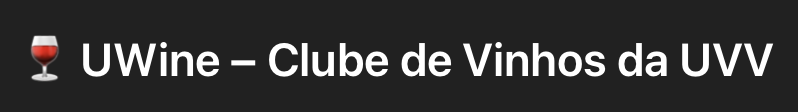

<center>

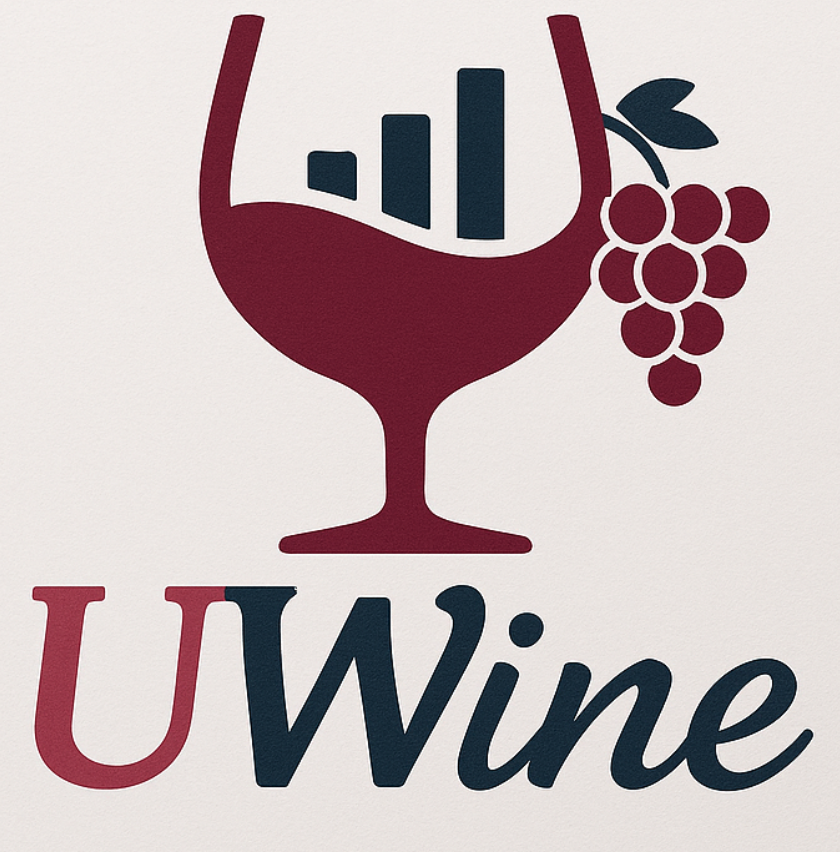

# **Cenário Fictício**:

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Prezados(as) alunos(as),

É com entusiasmo que apresento a proposta do **Projeto de Conclusão de Curso (TCC)** para os estudantes do curso de Ciência de Dados da Universidade Vila Velha: o UWine – Clube de Vinhos da UVV.

A proposta do projeto consiste na análise de um Clube de Vinhos universitário fictício, com base em dados simulados, que será totalmente orientado por técnicas e práticas de Ciência de Dados.

Sendo assim, você foi designado como **Consultor em Ciência de Dados** ( ***Data Science Consultant*** ) para fazer uma análise completa dos dados dos clientes a partir de um conjunto de dados (Amostra) com mais de 1 milhão de notas fiscais (~ 350 Megabytes). Além disso, há uma entrada diária de aproximadamente umas 5000 novas notas fiscais no sistema.

O objetivo é permitir que cada consultor(a) percorra foco analíticos diferentes dentro do mesmo ecossistema de dados, aplicando modelos de machine learning supervisionado ou não supervisionado, análise preditiva, dashboards interativos, entre outros.

Para garantir organização, profundidade técnica e coerência metodológica no desenvolvimento do ***Projeto UWine***, adotaremos um workflow composto por cinco etapas principais, alinhadas às boas práticas da Ciência de Dados. Cada etapa representa um marco do processo analítico, permitindo que cada analista avance de forma estruturada do entendimento inicial dos dados até a entrega final dos insights.

# BIBLIOTECAS E FUNÇÕES E CÓDIGOS

In [ ]:
# Bibliotecas necessárias para o Bootstrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import bootstrap

In [ ]:
# load do seu TABLE ? aqui: Numero 35
table = pd.read_csv('/content/table35.csv', index_col=0)

In [ ]:
display(table.head())

n_linhas, n_colunas = table.shape

print(f"Dimensão da base: {n_linhas:,} linhas e {n_colunas} colunas.")

table.info()

valores_nulos = table.isna().sum().sort_values(ascending=False)

valores_nulos = valores_nulos[valores_nulos > 0]

if len(valores_nulos) > 0:
    display(valores_nulos)
else:
    print("Não foram identificados valores ausentes na base de dados.")

,NOTA FISCAL,REGIÃO,SEXO,ESTADO CIVIL,DEPENDENTES,RENDA BRUTO (R$),OPINIÃO DO CLIENTE,NOTA DE SATISFAÇÃO (%),MEAN: alcohol,MEAN: malic_acid,...,MEAN: total_phenols,MEAN: flavanoids,MEAN: nonflavanoid_phenols,MEAN: proanthocyanins,MEAN: color_intensity,MEAN: hue,MEAN: od280/od315_of_diluted_wines,MEAN: proline,TIPO DA CONTA,TOTAL (R$)
0,3040000,SUDESTE,MASCULINO,DESQUITADO(A) / VIÚVO(A),0,3277.97,Entrega foi boa e rápida na UVVine,68.680,12.245079,0.906198,...,2.514985,2.514115,0.501508,1.397787,2.567010,1.054149,1.718176,551.649054,ESSENTIAL,297.01
1,3798158,SUDESTE,MASCULINO,CASADO,1,3271.03,Entrega foi boa e rápida na UVVine,68.680,11.789243,0.993655,...,3.307939,2.737521,0.265122,1.415335,6.091335,1.016404,2.786091,621.263114,ESSENTIAL,459.93
2,7574953,SUL,MASCULINO,SOLTEIRO,1,24311.44,Não tenho muito a dizer sobre a UVVine,71.104,13.422807,1.134886,...,1.751734,2.601709,0.232736,1.636040,4.630146,0.851902,3.303643,759.533252,PRIME,1217.56
3,4110910,NORDESTE,MASCULINO,CASADO,1,7754.09,Fiquei satisfeito com o serviço da UVVine,68.680,13.390899,2.935562,...,2.831677,1.843286,0.147159,2.073711,2.687034,1.128665,2.525002,599.740581,VIP,389.69
4,1930151,SUDESTE,MASCULINO,SOLTEIRO,2,3243.67,Sem opinião formada sobre a UVVine,68.680,11.174728,1.292823,...,2.202044,0.073151,0.263229,1.767853,7.452256,0.494935,3.182431,862.158049,ESSENTIAL,520.98


Dimensão da base: 1,120,000 linhas e 23 colunas.
<class 'pandas.core.frame.DataFrame'>
Index: 1120000 entries, 0 to 1119999
Data columns (total 23 columns):
 #   Column                              Non-Null Count    Dtype  
---  ------                              --------------    -----  
 0   NOTA FISCAL                         1120000 non-null  int64  
 1   REGIÃO                              1120000 non-null  object 
 2   SEXO                                1120000 non-null  object 
 3   ESTADO CIVIL                        1120000 non-null  object 
 4   DEPENDENTES                         1120000 non-null  int64  
 5   RENDA BRUTO (R$)                    1120000 non-null  float64
 6   OPINIÃO DO CLIENTE                  1120000 non-null  object 
 7   NOTA DE SATISFAÇÃO (%)              1120000 non-null  float64
 8   MEAN: alcohol                       1120000 non-null  float64
 9   MEAN: malic_acid                    1120000 non-null  float64
 10  MEAN: ash                         

In [ ]:
RESULTADOS = {}

def calcular_tamanho_amostra_proporcao(N, z=1.96, p=0.5, e=0.05):
    """Calcula o tamanho mínimo da amostra para população finita e infinita."""
    numerador = (z ** 2) * p * (1 - p)
    denominador = e ** 2
    n = numerador / denominador

    n_ajustado = n / (1 + (n / N))
    return int(np.ceil(n)), int(np.ceil(n_ajustado))

In [ ]:
# Paleta padrão dos gráficos
PLOT_COLORS = {
    "main_line": "tab:blue",
    "ref_line": "tab:orange",
    "ideal_pt": "tab:green",
    "zero": "tab:red",
    "ci": "tab:purple",
    "li": "tab:red",
    "ls": "tab:purple",
    "hist": "tab:blue",
    "kde": "tab:orange",
}

In [ ]:
# @title
def optimal_stratified_sample_size(
    df,
    value_column,
    strata_column,
    n_min=100,
    n_max=50000,
    step=100,
    stabilization_threshold=0.01,
    consecutive_points=3,
    plot=True
):
    """
    Estimate the optimal sample size for an infinite stratified population
    using Neyman allocation and consecutive marginal stabilization of the
    stratified standard error.

    Parameters
    ----------
    df : pandas.DataFrame
        Input dataset.

    value_column : str
        Numerical target variable used to estimate the mean.

    strata_column : str
        Categorical stratification variable.

    n_min : int, default=100
        Minimum total sample size evaluated.

    n_max : int, default=50000
        Maximum total sample size evaluated.

    step : int, default=100
        Increment between consecutive sample sizes.

    stabilization_threshold : float, default=0.01
        Maximum relative reduction accepted for standard error stabilization.
        Example: 0.01 means 1%.

    consecutive_points : int, default=3
        Number of consecutive marginal reductions that must remain below
        the stabilization threshold.

    plot : bool, default=True
        If True, plot the standard error stabilization curve.

    Returns
    -------
    summary : pandas.DataFrame
        Sample allocation per stratum.

    results : dict
        Dictionary containing:
        - optimal_n
        - optimal_standard_error
        - sample_sizes
        - standard_error_curve
        - marginal_reduction
        - stabilization_threshold
        - consecutive_points
        - strata_statistics
    """

    # Keep only the required columns and remove missing values
    data = df[[value_column, strata_column]].dropna().copy()

    # Convert the target variable to numeric
    data[value_column] = pd.to_numeric(data[value_column], errors="coerce")
    data = data.dropna()

    if data.empty:
        raise ValueError("The dataset is empty after removing missing or invalid values.")

    # Estimate stratum weights
    weights = (
        data[strata_column]
        .value_counts(normalize=True)
        .sort_index()
    )

    # Estimate stratum standard deviations
    stds = (
        data.groupby(strata_column)[value_column]
        .std()
        .sort_index()
    )

    # Align both series
    stds = stds.loc[weights.index]

    strata = weights.index.values
    Wh = weights.values
    Sh = stds.values

    if np.any(np.isnan(Sh)):
        raise ValueError(
            "At least one stratum has insufficient observations "
            "to calculate standard deviation."
        )

    if np.any(Sh == 0):
        print(
            "Warning: At least one stratum has zero standard deviation. "
            "Neyman allocation may assign a very small sample to this stratum."
        )

    # Neyman allocation weights
    neyman_weights = Wh * Sh

    if neyman_weights.sum() == 0:
        raise ValueError(
            "Neyman weights are zero. Check the variability of the target variable."
        )

    sample_sizes = np.arange(n_min, n_max + step, step)

    standard_errors = []
    allocations = []

    for n in sample_sizes:

        nh = n * neyman_weights / neyman_weights.sum()

        se = np.sqrt(
            np.sum(
                (Wh ** 2) * (Sh ** 2) / nh
            )
        )

        standard_errors.append(se)
        allocations.append(nh)

    standard_errors = np.array(standard_errors)
    allocations = np.array(allocations)

    # Marginal relative reduction of the standard error
    marginal_reduction = (
        np.abs(np.diff(standard_errors)) / standard_errors[:-1]
    )

    stable_sequence_index = None

    for i in range(0, len(marginal_reduction) - consecutive_points + 1):

        window = marginal_reduction[i:i + consecutive_points]

        if np.all(window < stabilization_threshold):
            stable_sequence_index = i
            break

    if stable_sequence_index is None:
        raise ValueError(
            "No consecutive stabilization point found within the evaluated interval. "
            "Try increasing n_max, increasing step, or using a larger threshold."
        )

    optimal_index = stable_sequence_index + consecutive_points

    optimal_n = sample_sizes[optimal_index]
    optimal_se = standard_errors[optimal_index]
    optimal_allocation = allocations[optimal_index]

    summary = pd.DataFrame({
        "Stratum": strata,
        "Population Weight (Wh)": Wh,
        "Std. Deviation (Sh)": Sh,
        "Neyman Weight (Wh x Sh)": neyman_weights,
        "Allocated Sample (nh)": np.round(optimal_allocation).astype(int)
    })

    summary["Allocated Sample (%)"] = (
        summary["Allocated Sample (nh)"] /
        summary["Allocated Sample (nh)"].sum()
    )

    strata_statistics = pd.DataFrame({
        "Stratum": strata,
        "Wh": Wh,
        "Sh": Sh,
        "Wh_x_Sh": neyman_weights
    })

    if plot:

        plt.figure(figsize=(11, 6))

        plt.plot(
            sample_sizes,
            standard_errors,
            linewidth=3,
            label="Stratified standard error"
        )

        plt.scatter(
            optimal_n,
            optimal_se,
            s=120,
            label="Optimal sample size"
        )

        plt.axvline(
            optimal_n,
            linestyle="--"
        )

        plt.text(
            optimal_n,
            optimal_se,
            f"  n = {optimal_n}\n  SE = {optimal_se:.4f}",
            verticalalignment="bottom"
        )

        plt.xlabel("Total Sample Size (n)")
        plt.ylabel("Stratified Standard Error")
        plt.title("Consecutive Marginal Stabilization of the Standard Error")
        plt.grid(True)
        plt.legend()
        plt.show()

    results = {
        "optimal_n": int(optimal_n),
        "optimal_standard_error": float(optimal_se),
        "sample_sizes": sample_sizes,
        "standard_error_curve": standard_errors,
        "marginal_reduction": marginal_reduction,
        "stabilization_threshold": stabilization_threshold,
        "consecutive_points": consecutive_points,
        "strata_statistics": strata_statistics
    }

    return summary, results

In [ ]:
def AtividadeA1_1():
  """
  HELP:
  Fazer toda a Atividade A1.1 aqui!
  Docstring desejável em todo o Projeto
  """

In [ ]:
def AtividadeA1_1():
    y = table["TOTAL (R$)"].dropna()
    N = len(y)

    tamanhos = np.arange(100, 200_100, 100)
    erros_padrao = np.zeros(len(tamanhos), dtype=float)

    rng = np.random.default_rng(42)
    R_pequeno = 15
    R_grande = 3

    for idx, n in enumerate(tamanhos):
        R = R_pequeno if n <= 50_000 else R_grande
        se_rep = []

        for _ in range(R):
            seed = int(rng.integers(0, 1_000_000_000))
            amostra = y.sample(n=n, replace=False, random_state=seed)
            se_rep.append(amostra.std(ddof=1) / np.sqrt(n))

        erros_padrao[idx] = np.mean(se_rep)

    se_medio = float(erros_padrao.mean())
    media_total = float(y.mean())

    ic_inf = media_total - 1.96 * se_medio
    ic_sup = media_total + 1.96 * se_medio

    idx_ideal = int(np.where(erros_padrao <= se_medio)[0][0])
    n_ideal = int(tamanhos[idx_ideal])
    se_ideal = float(erros_padrao[idx_ideal])

    RESULTADOS["A1.1"] = {
        "N": int(N),
        "media_total": media_total,
        "se_medio": se_medio,
        "ic_95": (float(ic_inf), float(ic_sup)),
        "tamanho_ideal": n_ideal,
        "tamanhos": tamanhos,
        "erros_padrao": erros_padrao,
        "se_ideal": se_ideal,
    }

    print(f"População disponível (N): {N:,}")
    print(f"Média de TOTAL (R$): {media_total:.2f}")
    print(f"Erro-padrão-médio: {se_medio:.6f}")
    print(f"IC 95% da média: [{ic_inf:.2f}, {ic_sup:.2f}]")
    print(f"Tamanho ideal da amostra: {n_ideal:,}")


In [ ]:
def AtividadeA1_1_grupos():
    grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]
    resultados_grupos = []

    rng = np.random.default_rng(42)

    for grupo in grupos_alvo:
        df_grupo = table[table["TIPO DA CONTA"] == grupo].copy()
        y = df_grupo["TOTAL (R$)"].dropna()
        N = len(y)

        tamanhos = np.arange(100, min(N, 200000) + 1, 100)
        erros_padrao = np.zeros(len(tamanhos), dtype=float)

        R_pequeno = 15
        R_grande = 3

        for idx, n in enumerate(tamanhos):
            R = R_pequeno if n <= 50000 else R_grande
            se_rep = []

            for _ in range(R):
                seed = int(rng.integers(0, 1_000_000_000))
                amostra = y.sample(n=n, replace=False, random_state=seed)
                se_rep.append(amostra.std(ddof=1) / np.sqrt(n))

            erros_padrao[idx] = np.mean(se_rep)

        se_medio = float(erros_padrao.mean())
        media_total = float(y.mean())

        ic_inf = media_total - 1.96 * se_medio
        ic_sup = media_total + 1.96 * se_medio

        idx_ideal = int(np.where(erros_padrao <= se_medio)[0][0])
        n_ideal = int(tamanhos[idx_ideal])
        se_ideal = float(erros_padrao[idx_ideal])

        resultados_grupos.append({
            "grupo": grupo,
            "N": int(N),
            "media_total": media_total,
            "se_medio": se_medio,
            "ic_inf": float(ic_inf),
            "ic_sup": float(ic_sup),
            "tamanho_ideal": n_ideal,
            "se_ideal": se_ideal,
            "tamanhos": tamanhos,
            "erros_padrao": erros_padrao,
        })

    RESULTADOS["A1.1_grupos"] = resultados_grupos

    print("Análise da amostragem por grupos concluída.")
    print(f"Grupos analisados: {', '.join([r['grupo'] for r in resultados_grupos])}")

In [ ]:
AtividadeA1_1()
resultado = RESULTADOS["A1.1"]

População disponível (N): 1,120,000
Média de TOTAL (R$): 790.98
Erro-padrão-médio: 3.638091
IC 95% da média: [783.85, 798.11]
Tamanho ideal da amostra: 51,500


A análise avaliou a evolução do erro-padrão da média da variável TOTAL (R$) conforme o tamanho da amostra aumentava.

Para a população geral, foram obtidos:

População: 1.120.000 registros

Média de TOTAL: R$ 790,98

Erro-padrão médio: 3,638091

IC 95%: R 783,85aR  798,11

Tamanho ideal: 51.500 registros.

O gráfico mostrou que o erro-padrão diminui à medida que o tamanho da amostra aumenta, apresentando estabilização progressiva. O notebook adotou como critério o primeiro tamanho em que o erro-padrão atingiu o nível de referência definido.

Os resultados demonstram que o aumento do tamanho da amostra reduz progressivamente o erro-padrão da estimativa. A partir das simulações realizadas, identificou-se que uma amostra de 51.500 registros apresenta um nível de erro-padrão considerado adequado segundo o critério adotado. Portanto, esse tamanho foi definido como a amostra ideal para representar a população geral nas etapas posteriores da análise

In [ ]:
AtividadeA1_1_grupos()
resultado = RESULTADOS["A1.1_grupos"]

Análise da amostragem por grupos concluída.
Grupos analisados: ESSENTIAL, PRIME, VIP


In [ ]:
resumo_grupos = pd.DataFrame([
    {
        "Grupo": r["grupo"],
        "N_grupo": r["N"],
        "Média TOTAL (R$)": r["media_total"],
        "SE médio": r["se_medio"],
        "IC95% inferior": r["ic_inf"],
        "IC95% superior": r["ic_sup"],
        "Tamanho ideal": r["tamanho_ideal"],
    }
    for r in resultado
])

display(resumo_grupos.round(4))

,Grupo,N_grupo,Média TOTAL (R$),SE médio,IC95% inferior,IC95% superior,Tamanho ideal
0,ESSENTIAL,700015,392.2672,1.1812,389.9521,394.5823,50700
1,PRIME,175002,2237.5692,4.8890,2227.9867,2247.1516,45400
2,VIP,244983,896.9160,1.9001,893.1917,900.6403,51400


A análise estratificada mostrou que os três segmentos apresentam tamanhos amostrais ideais próximos: 50.700 para ESSENTIAL, 45.400 para PRIME e 51.400 para VIP. Isso indica que a estabilidade estatística da estimativa é consistente entre os segmentos. Como o objetivo é trabalhar com uma amostra única representativa da população geral, o valor de 51.500 registros é o mais adequado, pois atende também ao grupo que exige maior tamanho amostral.

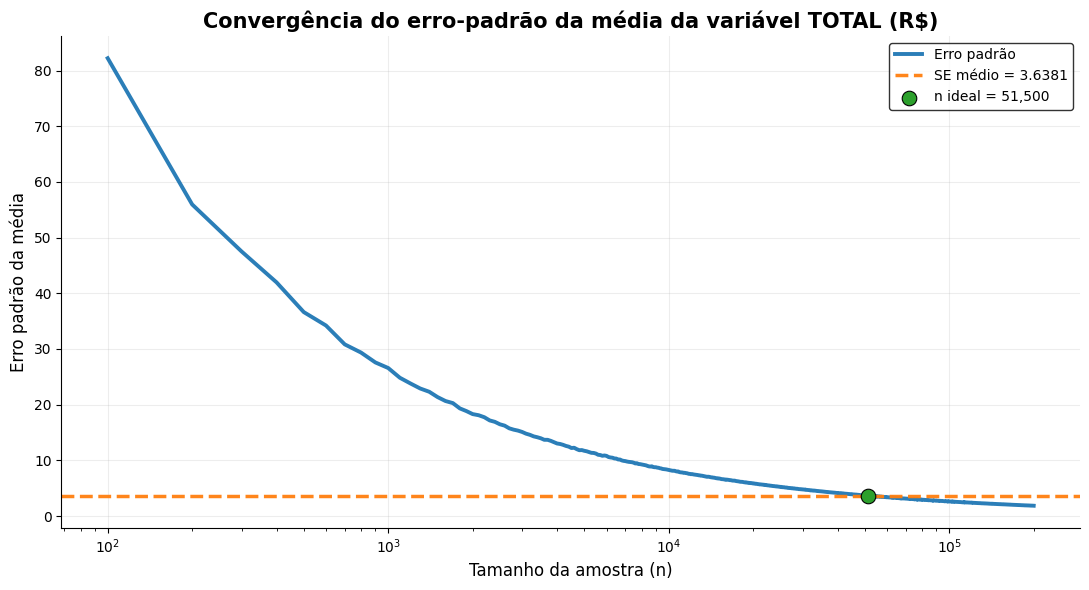

In [ ]:
plt.figure(figsize=(11, 6))
plt.plot(
    RESULTADOS["A1.1"]["tamanhos"],
    RESULTADOS["A1.1"]["erros_padrao"],
    color=PLOT_COLORS["main_line"],
    linewidth=2.8,
    alpha=0.95,
    label="Erro padrão",
)
plt.axhline(
    RESULTADOS["A1.1"]["se_medio"],
    color=PLOT_COLORS["ref_line"],
    linestyle="--",
    linewidth=2.5,
    alpha=0.95,
    label=f'SE médio = {RESULTADOS["A1.1"]["se_medio"]:.4f}',
)
plt.scatter(
    RESULTADOS["A1.1"]["tamanho_ideal"],
    RESULTADOS["A1.1"]["se_ideal"],
    color=PLOT_COLORS["ideal_pt"],
    s=110,
    zorder=6,
    edgecolor="black",
    linewidth=0.8,
    label=f'n ideal = {RESULTADOS["A1.1"]["tamanho_ideal"]:,}',
)
plt.title("Convergência do erro-padrão da média da variável TOTAL (R$)", fontsize=15, fontweight="bold")
plt.xlabel("Tamanho da amostra (n)", fontsize=12)
plt.xscale("log")
plt.ylabel("Erro padrão da média", fontsize=12)
plt.grid(alpha=0.22)
plt.legend(frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()

O gráfico mostrou que o erro-padrão diminui à medida que o tamanho da amostra aumenta, apresentando estabilização progressiva. O notebook adotou como critério o primeiro tamanho em que o erro-padrão atingiu o nível de referência definido.

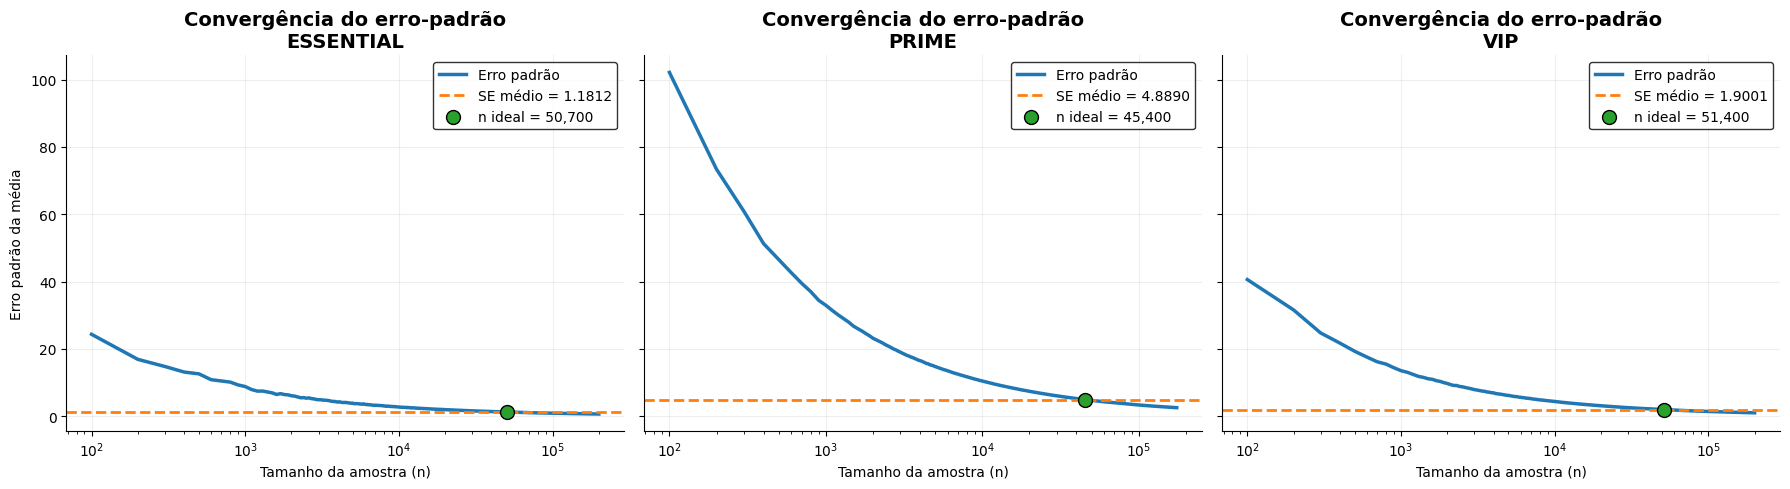

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, r in zip(axes, resultado):
    ax.plot(
        r["tamanhos"],
        r["erros_padrao"],
        color=PLOT_COLORS["main_line"],
        linewidth=2.5,
        label="Erro padrão"
    )

    ax.axhline(
        r["se_medio"],
        color=PLOT_COLORS["ref_line"],
        linestyle="--",
        linewidth=2,
        label=f'SE médio = {r["se_medio"]:.4f}'
    )

    ax.scatter(
        r["tamanho_ideal"],
        r["se_ideal"],
        color=PLOT_COLORS["ideal_pt"],
        s=100,
        edgecolor="black",
        zorder=5,
        label=f'n ideal = {r["tamanho_ideal"]:,}'
    )

    ax.set_title(f'Convergência do erro-padrão\n{r["grupo"]}', fontsize=14, fontweight="bold")
    ax.set_xlabel("Tamanho da amostra (n)")
    ax.set_xscale("log")
    ax.grid(alpha=0.20)
    ax.legend(frameon=True, edgecolor="black")

axes[0].set_ylabel("Erro padrão da média")
plt.tight_layout()
sns.despine()
plt.show()

Além da análise global, foi realizada a determinação do tamanho ideal da amostra para os principais grupos da base (`ESSENTIAL`, `PRIME` e `VIP`). O objetivo foi verificar se a estabilização do erro-padrão da média da variável `TOTAL (R$)` também ocorre de forma consistente dentro de cada segmento, permitindo avaliar se a representatividade estatística da variável `TOTAL (R$)` se sustenta de forma consistente tanto no nível global quanto no nível estratificado.


# Workflow: Detalhamento das Atividades

##Atividade A1: Estratificação amostral da população

###Atividade A1.1: Determinar o TAMANHO IDEAL da amostra

Criar os (4) gráficos do ERRO-PADRÃO-MÉDIO (TARGET: $y$: **TOTAL (R$)**) das seguintes categorias:

*   **ESSENTIAL**
*   **VIP**
*   **PRIME**
*   **GERAL**

Fazer a **ANÁLISE BOOTSTRAP** para determinar:
*   **Intervalo de confiança**.
*   **Erro padrão**.
*   **RESPONDER: Qual é o "Tamanho Ideal" da amostra ?**

Determinação do Tamanho Ideal da Amostra em Populações Infinitas Estratificadas: [Link](https://drive.google.com/file/d/1aLWDSNRrjr03ItMSE_3joXYmdoC09jQm/view?usp=sharing)

Usar a Função - Determinação do Tamanho Ideal da Amostra em Populações Infinitas Estratificadas, por dois(2) procedimentos a saber:

*   Procedimento empírico: Estabilização marginal do erro-padrão: **optimal_sample_size**
*   Procedimento teórico-empírico: Estabilização marginal do erro-padrão estratificado e otimização de Neyman: **optimal_stratified_sample_size**



In [ ]:
# @title
def optimal_stratified_sample_size(
    df,
    value_column,
    strata_column,
    n_min=100,
    n_max=50000,
    step=100,
    stabilization_threshold=0.01,
    consecutive_points=3,
    plot=True
):
    """
    Estimate the optimal sample size for an infinite stratified population
    using Neyman allocation and consecutive marginal stabilization of the
    stratified standard error.
    """

    data = df[[value_column, strata_column]].dropna().copy()

    data[value_column] = pd.to_numeric(
        data[value_column],
        errors="coerce"
    )

    data = data.dropna()

    if data.empty:
        raise ValueError("No valid data available.")

    weights = (
        data[strata_column]
        .value_counts(normalize=True)
        .sort_index()
    )

    stds = (
        data.groupby(strata_column)[value_column]
        .std()
        .sort_index()
    )

    stds = stds.loc[weights.index]

    strata = weights.index.values
    Wh = weights.values
    Sh = stds.values

    if np.any(np.isnan(Sh)):
        raise ValueError("One or more strata have NaN standard deviation.")

    if np.any(Sh == 0):
        print("Warning: one or more strata have zero standard deviation.")

    neyman_weights = Wh * Sh

    if neyman_weights.sum() == 0:
        raise ValueError("Neyman weights sum to zero.")

    sample_sizes = np.arange(
        n_min,
        n_max + step,
        step
    )

    standard_errors = []
    allocations = []

    for n in sample_sizes:

        nh = (
            n * neyman_weights /
            neyman_weights.sum()
        )

        se = np.sqrt(
            np.sum(
                (Wh ** 2) *
                (Sh ** 2) /
                nh
            )
        )

        standard_errors.append(se)
        allocations.append(nh)

    standard_errors = np.array(standard_errors)
    allocations = np.array(allocations)

    marginal_reduction = (
        np.abs(np.diff(standard_errors)) /
        standard_errors[:-1]
    )

    stable_sequence_index = None

    for i in range(
        0,
        len(marginal_reduction) - consecutive_points + 1
    ):

        window = marginal_reduction[
            i:i + consecutive_points
        ]

        if np.all(
            window < stabilization_threshold
        ):
            stable_sequence_index = i
            break

    if stable_sequence_index is None:
        raise ValueError(
            "No stabilization sequence found."
        )

    optimal_index = (
        stable_sequence_index +
        consecutive_points
    )

    optimal_n = sample_sizes[optimal_index]
    optimal_se = standard_errors[optimal_index]
    optimal_allocation = allocations[optimal_index]

    summary = pd.DataFrame({
        "Stratum": strata,
        "Population Weight (Wh)": Wh,
        "Std. Deviation (Sh)": Sh,
        "Neyman Weight (Wh x Sh)": neyman_weights,
        "Allocated Sample (nh)": np.round(
            optimal_allocation
        ).astype(int)
    })

    summary["Allocated Sample (%)"] = (
        summary["Allocated Sample (nh)"] /
        summary["Allocated Sample (nh)"].sum()
    )

    strata_statistics = pd.DataFrame({
        "Stratum": strata,
        "Wh": Wh,
        "Sh": Sh,
        "Wh_x_Sh": neyman_weights
    })

    if plot:

        plt.figure(figsize=(11, 6))

        plt.plot(
            sample_sizes,
            standard_errors,
            linewidth=3,
            label="Stratified standard error"
        )

        plt.scatter(
            optimal_n,
            optimal_se,
            s=120,
            label="Optimal sample size"
        )

        plt.axvline(
            optimal_n,
            linestyle="--"
        )

        plt.text(
            optimal_n,
            optimal_se,
            f"  n = {optimal_n}\n  SE = {optimal_se:.4f}",
            verticalalignment="bottom"
        )

        plt.xlabel("Total Sample Size (n)")
        plt.ylabel("Stratified Standard Error")

        plt.title(
            "Consecutive Marginal Stabilization of the Standard Error"
        )

        plt.grid(True)
        plt.legend()
        plt.show()

    results = {
        "optimal_n": int(optimal_n),
        "optimal_standard_error": float(optimal_se),
        "sample_sizes": sample_sizes,
        "standard_error_curve": standard_errors,
        "marginal_reduction": marginal_reduction,
        "stabilization_threshold": stabilization_threshold,
        "consecutive_points": consecutive_points,
        "strata_statistics": strata_statistics
    }

    return summary, results

In [ ]:
# exemplo de como exibir Relatório: Fazer todos modularizados
AtividadeA1_1()

População disponível (N): 1,120,000
Média de TOTAL (R$): 790.98
Erro-padrão-médio: 3.638091
IC 95% da média: [783.85, 798.11]
Tamanho ideal da amostra: 51,500


A análise estratificada mostrou que os três segmentos apresentam tamanhos amostrais ideais próximos: 50.700 para ESSENTIAL, 45.400 para PRIME e 51.400 para VIP. Isso indica que a estabilidade estatística da estimativa é consistente entre os segmentos. Como o objetivo é trabalhar com uma amostra única representativa da população geral, o valor de 51.500 registros é o mais adequado, pois atende também ao grupo que exige maior tamanho amostral.

In [ ]:
help(AtividadeA1_1)

Help on function AtividadeA1_1 in module __main__:

AtividadeA1_1()



###Atividade A1.2: Analisar os outliers

In [ ]:
serie = table["NOTA DE SATISFAÇÃO (%)"]

resumo = serie.describe().to_frame(name="Valor")
frequencias = serie.value_counts().head(10).to_frame(name="Frequência")
proporcoes = (serie.value_counts(normalize=True).head(10) * 100).to_frame(name="Percentual (%)")

display(resumo)
print(f"Quantidade de valores únicos: {serie.nunique():,}")
display(frequencias)
display(proporcoes.round(3))


,Valor
count,1.120000e+06
mean,6.900389e+01
std,1.460124e+00
min,6.868000e+01
25%,6.868000e+01
50%,6.868000e+01
75%,6.868000e+01
max,9.716200e+01


Quantidade de valores únicos: 208


,Frequência
NOTA DE SATISFAÇÃO (%),
68.680,1038395
69.286,1272
69.084,1233
68.781,1231
68.983,1220
69.488,1208
69.185,1188
68.882,1184
70.195,1184


,Percentual (%)
NOTA DE SATISFAÇÃO (%),
68.680,92.714
69.286,0.114
69.084,0.110
68.781,0.110
68.983,0.109
69.488,0.108
69.185,0.106
68.882,0.106
70.195,0.106


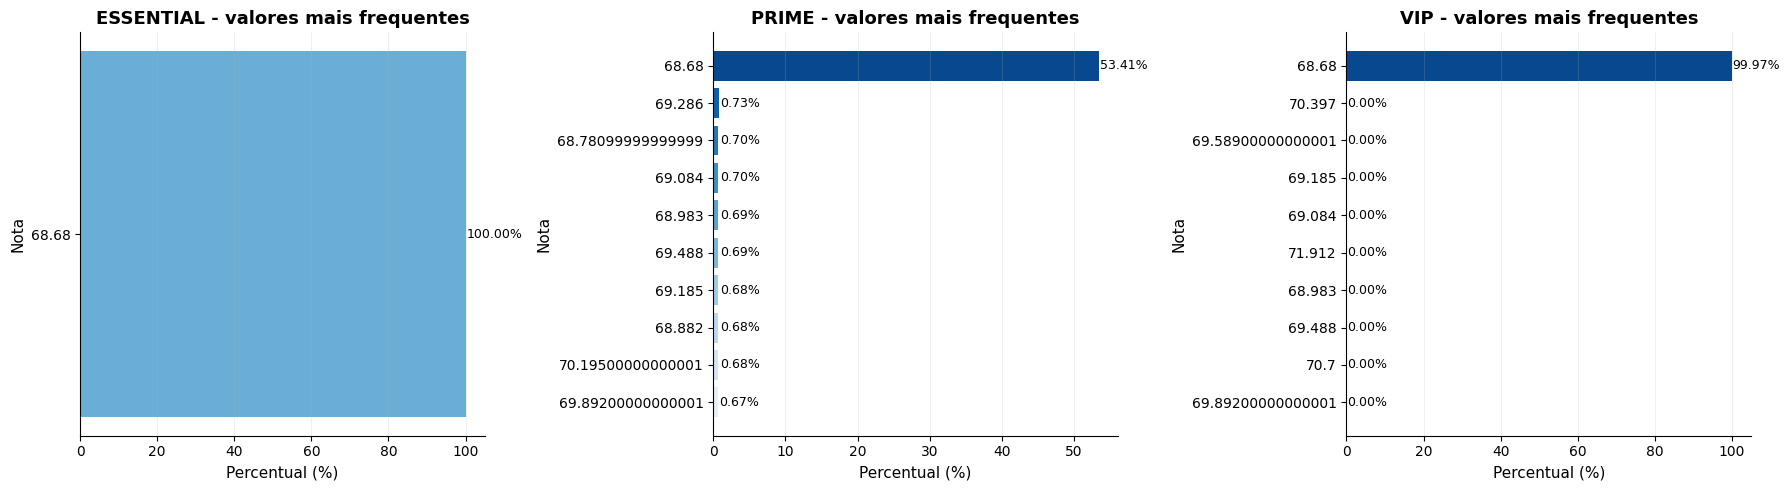

In [ ]:
grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=False)

for ax, grupo in zip(axes, grupos_alvo):
    serie_grupo = table.loc[table["TIPO DA CONTA"] == grupo, "NOTA DE SATISFAÇÃO (%)"].dropna()
    top_valores = (serie_grupo.value_counts(normalize=True).head(10) * 100).sort_values()

    bars = ax.barh(
        top_valores.index.astype(str),
        top_valores.values,
        color=sns.color_palette("Blues", len(top_valores))
    )

    ax.set_title(f"{grupo} - valores mais frequentes", fontsize=13, fontweight="bold")
    ax.set_xlabel("Percentual (%)", fontsize=11)
    ax.set_ylabel("Nota", fontsize=11)
    ax.grid(axis="x", alpha=0.20)

    for bar in bars:
        largura = bar.get_width()
        ax.text(
            largura + 0.2,
            bar.get_y() + bar.get_height() / 2,
            f"{largura:.2f}%",
            va="center",
            fontsize=9
        )

plt.tight_layout()
sns.despine()
plt.show()


In [ ]:
def diagnosticar_variavel_numerica(dados, coluna):
    serie = pd.to_numeric(dados[coluna], errors="coerce")

    negativos = int((serie < 0).sum())
    perc_negativos = float((negativos / len(serie.dropna())) * 100) if len(serie.dropna()) > 0 else 0.0

    serie_valid = serie[serie >= 0].dropna()

    q1 = float(serie_valid.quantile(0.25))
    q3 = float(serie_valid.quantile(0.75))
    iqr = float(q3 - q1)

    li = float(q1 - 1.5 * iqr)
    ls = float(q3 + 1.5 * iqr)

    extremos_altos = int((serie_valid > ls).sum())
    extremos_baixos = int((serie_valid < li).sum())

    return {
        "N válidos": int(len(serie_valid)),
        "Negativos": negativos,
        "% negativos": perc_negativos,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "LI": li,
        "LS": ls,
        "Extremos baixos": extremos_baixos,
        "Extremos altos": extremos_altos,
    }


In [ ]:
def AtividadeA1_2():
    grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]
    variaveis = ["RENDA BRUTO (R$)", "NOTA DE SATISFAÇÃO (%)", "TOTAL (R$)"]

    resumo = []
    table_limpa = table.copy()

    for var in variaveis:
        table_limpa[var] = pd.to_numeric(table_limpa[varvar], errors="coerce")
        table_limpa.loc[table_limpa[var] < 0, var] = np.nan

    for grupo in grupos_alvo:
        df_grupo = table_limpa[table_limpa["TIPO DA CONTA"] == grupo].copy()

        for var in variaveis:
            info = diagnosticar_variavel_numerica(df_grupo, var)

            resumo.append({
                "Grupo": grupo,
                "Variável": var,
                **info
            })

    resumo_df = pd.DataFrame(resumo)

    RESULTADOS["A1.2"] = {
        "resumo": resumo_df,
        "table_limpa": table_limpa,
    }

    print("Análise de outliers e qualidade dos dados concluída.")
    print(f"Grupos analisados: {', '.join(grupos_alvo)}")
    print("Valores negativos foram tratados como problema de qualidade.")
    print("Valores extremos altos foram mantidos para preservar sinal de negócio.")


In [ ]:
AtividadeA1_2()

resultado = RESULTADOS["A1.2"]

resumo_exibicao = resultado["resumo"].copy()
resumo_exibicao[["% negativos", "Q1", "Q3", "IQR", "LI", "LS"]] = (
    resumo_exibicao[["% negativos", "Q1", "Q3", "IQR", "LI", "LS"]].round(2)
)

display(resumo_exibicao)


Análise de outliers e qualidade dos dados concluída.
Grupos analisados: ESSENTIAL, PRIME, VIP
Valores negativos foram tratados como problema de qualidade.
Valores extremos altos foram mantidos para preservar sinal de negócio.


,Grupo,Variável,N válidos,Negativos,% negativos,Q1,Q3,IQR,LI,LS,Extremos baixos,Extremos altos
0,ESSENTIAL,RENDA BRUTO (R$),700015,0,0.0,3196.99,3314.42,117.43,3020.84,3490.57,3395,24228
1,ESSENTIAL,NOTA DE SATISFAÇÃO (%),700015,0,0.0,68.68,68.68,0.00,68.68,68.68,0,0
2,ESSENTIAL,TOTAL (R$),700015,0,0.0,236.05,491.34,255.29,-146.88,874.27,0,14809
3,PRIME,RENDA BRUTO (R$),175002,0,0.0,19101.02,23115.09,4014.07,13079.92,29136.20,14426,223
4,PRIME,NOTA DE SATISFAÇÃO (%),175002,0,0.0,68.68,72.11,3.43,63.53,77.26,0,9741
5,PRIME,TOTAL (R$),175002,0,0.0,1365.96,3063.90,1697.94,-1180.94,5610.81,0,0
6,VIP,RENDA BRUTO (R$),244983,0,0.0,7558.09,7987.58,429.49,6913.86,8631.81,6890,16439
7,VIP,NOTA DE SATISFAÇÃO (%),244983,0,0.0,68.68,68.68,0.00,68.68,68.68,0,79
8,VIP,TOTAL (R$),244983,0,0.0,560.89,1171.64,610.75,-355.24,2087.77,0,4487


Foram analisadas as variáveis:

RENDA BRUTO (R$)
NOTA DE SATISFAÇÃO (%)
TOTAL (R$)

Não foram encontrados valores negativos nas três variáveis. Os valores extremos superiores foram mantidos porque podem representar informações reais relevantes para o negócio.

In [ ]:
resumo_nota_grupo = (
    table.groupby("TIPO DA CONTA")["NOTA DE SATISFAÇÃO (%)"]
    .agg(
        n="count",
        n_unicos="nunique",
        media="mean",
        dp="std",
        minimo="min",
        q1=lambda s: s.quantile(0.25),
        mediana="median",
        q3=lambda s: s.quantile(0.75),
        maximo="max",
    )
    .reset_index()
)

moda_grupo = (
    table.groupby("TIPO DA CONTA")["NOTA DE SATISFAÇÃO (%)"]
    .agg(lambda s: s.value_counts(normalize=True).iloc[0] * 100)
    .reset_index(name="percentual_moda")
)

resumo_nota_grupo = resumo_nota_grupo.merge(moda_grupo, on="TIPO DA CONTA", how="left")
display(resumo_nota_grupo.round(4))


,TIPO DA CONTA,n,n_unicos,media,dp,minimo,q1,mediana,q3,maximo,percentual_moda
0,ESSENTIAL,700015,1,68.6800,0.0000,68.68,68.68,68.68,68.680,68.680,100.0000
1,PRIME,175002,208,70.7520,3.1655,68.68,68.68,68.68,72.114,97.162,53.4142
2,VIP,244983,35,68.6806,0.0399,68.68,68.68,68.68,68.680,75.447,99.9678


ESSENTIAL

Renda: 3,95% de valores extremos
Total: 2,12%
Nota de satisfação: sem outliers pelo critério utilizado

PRIME

Renda: 8,37% de valores extremos
Total: 0%
Nota de satisfação: 5,57% aproximadamente

VIP

Renda: 9,52% de valores extremos
Total: 1,83%
Nota de satisfação: pequena quantidade de valores extremos.

In [ ]:
for grupo in ["ESSENTIAL", "PRIME", "VIP"]:
    print(f"\nGrupo: {grupo}")
    display(
        (table.loc[table["TIPO DA CONTA"] == grupo, "NOTA DE SATISFAÇÃO (%)"]
         .value_counts(normalize=True)
         .head(10)
         .mul(100)
         .round(4)
         .to_frame("Percentual (%)"))
    )



Grupo: ESSENTIAL


,Percentual (%)
NOTA DE SATISFAÇÃO (%),
68.68,100.0



Grupo: PRIME


,Percentual (%)
NOTA DE SATISFAÇÃO (%),
68.680,53.4142
69.286,0.7257
68.781,0.7023
69.084,0.7017
68.983,0.6948
69.488,0.6880
68.882,0.6760
69.185,0.6760
70.195,0.6754



Grupo: VIP


,Percentual (%)
NOTA DE SATISFAÇÃO (%),
68.680,99.9678
70.397,0.0029
69.589,0.0024
69.185,0.0020
71.912,0.0020
69.084,0.0020
69.488,0.0016
68.983,0.0016
70.700,0.0012


In [ ]:
coerencia = (
    table.groupby(["TIPO DA CONTA", "OPINIÃO DO CLIENTE"])["NOTA DE SATISFAÇÃO (%)"]
    .agg(["count", "mean", "median", "nunique"])
    .reset_index()
    .sort_values(["TIPO DA CONTA", "count"], ascending=[True, False])
)

display(coerencia.head(30))


,TIPO DA CONTA,OPINIÃO DO CLIENTE,count,mean,median,nunique
2,ESSENTIAL,Entrega foi boa e rápida na UVVine,108174,68.680000,68.68,1
5,ESSENTIAL,Fiquei satisfeito com o serviço da UVVine,107959,68.680000,68.68,1
8,ESSENTIAL,Funcionou bem e me atendeu no prazo certo a UV...,107952,68.680000,68.68,1
9,ESSENTIAL,Gostei do atendimento prestado pela UVVine,107340,68.680000,68.68,1
20,ESSENTIAL,"Serviço eficiente, recomendo o clube: UVVine",107338,68.680000,68.68,1
11,ESSENTIAL,Nada digno de nota com a UVVine,21196,68.680000,68.68,1
7,ESSENTIAL,Foi indiferente minha experiência com a UVVine,21120,68.680000,68.68,1
13,ESSENTIAL,Não tenho muito a dizer sobre a UVVine,21077,68.680000,68.68,1
17,ESSENTIAL,Sem opinião formada sobre a UVVine,20962,68.680000,68.68,1
1,ESSENTIAL,"Compro exponenciamente, opinião neutra sobre U...",20923,68.680000,68.68,1


In [ ]:
colunas_numericas = ["RENDA BRUTO (R$)", "NOTA DE SATISFAÇÃO (%)", "TOTAL (R$)"]

negativos_df = pd.DataFrame([
    {
        "Variável": col,
        "Qtd negativos": int((pd.to_numeric(table[col], errors="coerce") < 0).sum()),
        "% negativos": float(((pd.to_numeric(table[col], errors="coerce") < 0).sum() / len(table)) * 100)
    }
    for col in colunas_numericas
])

display(negativos_df.round(4))


,Variável,Qtd negativos,% negativos
0,RENDA BRUTO (R$),0,0.0
1,NOTA DE SATISFAÇÃO (%),0,0.0
2,TOTAL (R$),0,0.0


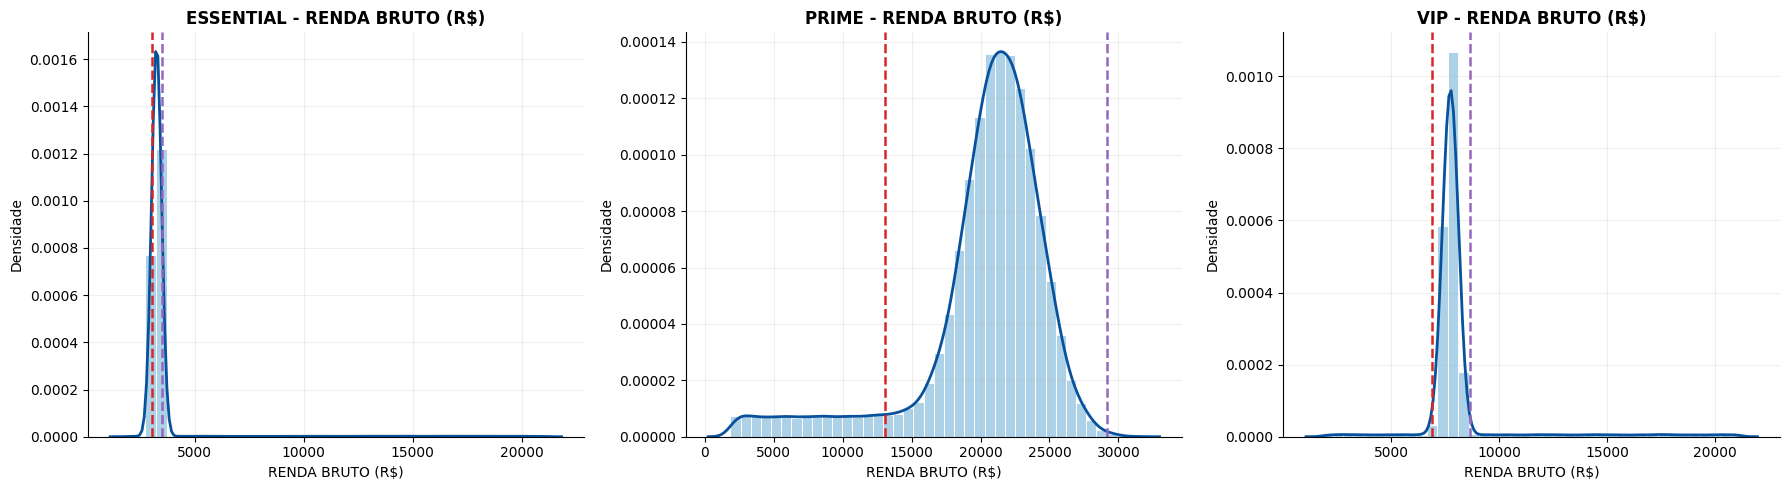

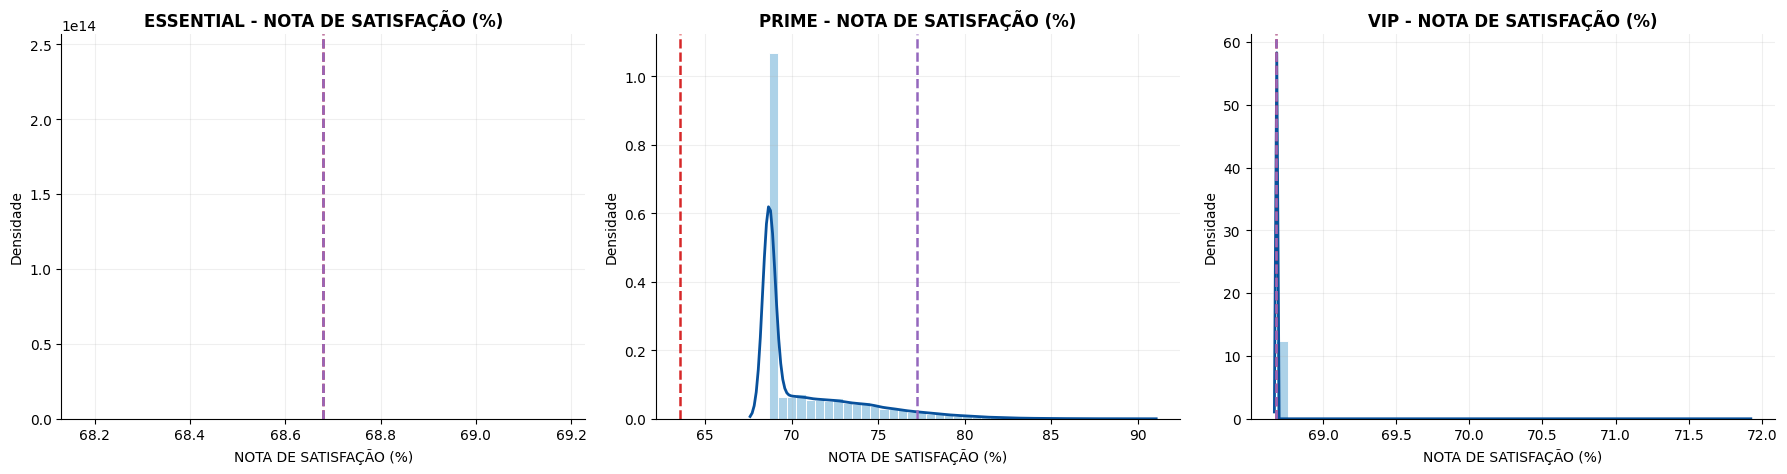

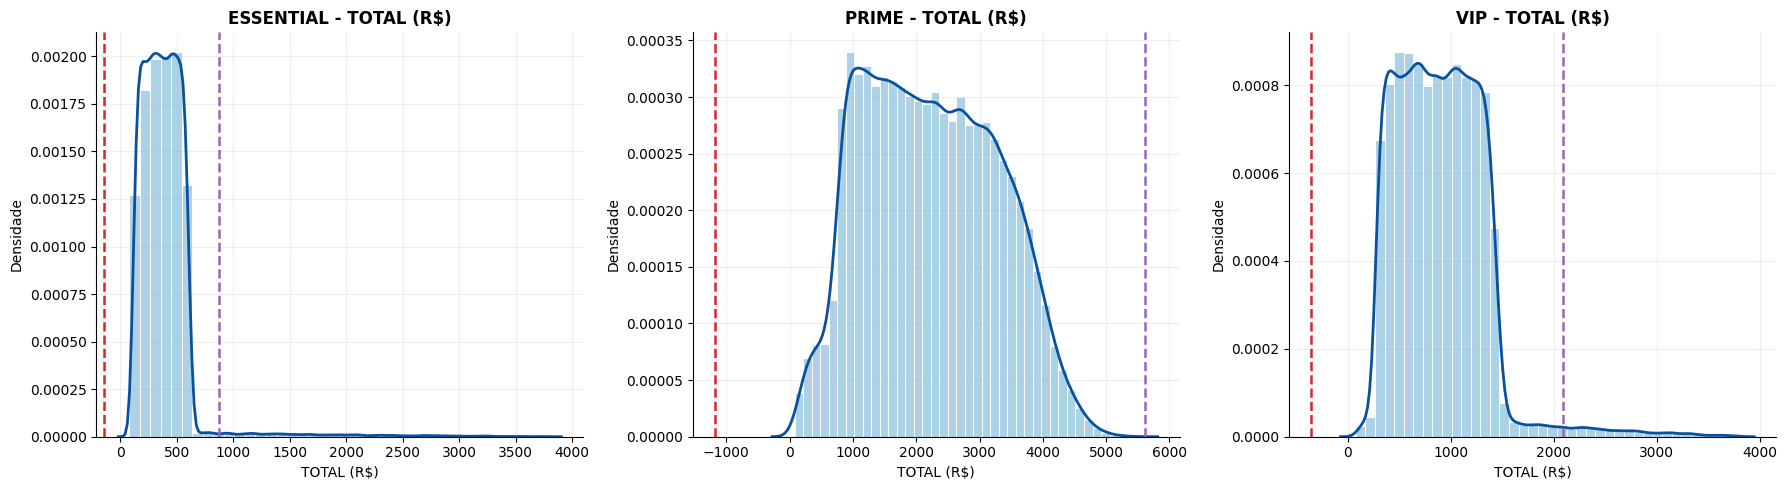

In [ ]:
variaveis = ["RENDA BRUTO (R$)", "NOTA DE SATISFAÇÃO (%)", "TOTAL (R$)"]
grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]

for var in variaveis:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

    for ax, grupo in zip(axes, grupos_alvo):
        df_grupo = resultado["table_limpa"][resultado["table_limpa"]["TIPO DA CONTA"] == grupo].copy()
        serie_plot = df_grupo[var].dropna()

        if len(serie_plot) > 50000:
            serie_plot = serie_plot.sample(50000, random_state=42)

        info = (
            resultado["resumo"]
            .query("Grupo == @grupo and Variável == @var")
            .iloc[0]
        )

        sns.histplot(
            serie_plot,
            bins=40,
            stat="density",
            color="#6baed6",
            edgecolor="white",
            alpha=0.55,
            ax=ax
        )

        sns.kdeplot(
            serie_plot,
            color="#08519c",
            linewidth=2.0,
            ax=ax
        )

        ax.axvline(info["LI"], color="#d62728", linestyle="--", linewidth=1.8, label="LI")
        ax.axvline(info["LS"], color="#9467bd", linestyle="--", linewidth=1.8, label="LS")
        ax.set_title(f"{grupo} - {var}", fontsize=12, fontweight="bold")
        ax.set_xlabel(var, fontsize=10)
        ax.set_ylabel("Densidade", fontsize=10)
        ax.grid(alpha=0.20)

    plt.tight_layout()
    sns.despine()
    plt.show()


A análise de outliers mostrou que não existem valores negativos nas principais variáveis financeiras e de satisfação, indicando boa consistência básica dos dados. Entretanto, foram identificados valores extremos superiores, principalmente na variável RENDA BRUTO (R$), com maior concentração no grupo VIP e no grupo PRIME. Esses valores não foram removidos, pois podem representar clientes com características financeiras diferenciadas e, portanto, possuem potencial relevância para a análise de negócio. Dessa forma, optou-se por preservar essas informações.

###Atividade A1.3: Testes de Hipóteses ([Link](https://colab.research.google.com/drive/1_YGamH-qOWSNaCKG5kVlLiZPuXv5lT34?usp=sharing))

In [ ]:
from scipy.stats import shapiro

def AtividadeA1_3(alpha=0.05, z_95=1.96, B=2000, n_rodadas_validas=20, max_tentativas=200, random_state=42):
    grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]

    if "A1.1_grupos" not in RESULTADOS:
        raise ValueError("Execute a Atividade A1.1 por grupos antes desta etapa.")

    base_ref = RESULTADOS.get("A1.2", {}).get("table_limpa", table).copy()

    mapa_n_ideal = {
        item["grupo"]: int(item["tamanho_ideal"])
        for item in RESULTADOS["A1.1_grupos"]
    }

    rng = np.random.default_rng(random_state)
    resultados_grupos = []

    for grupo in grupos_alvo:
        df_grupo = base_ref[base_ref["TIPO DA CONTA"] == grupo].copy()
        y_full = pd.to_numeric(df_grupo["TOTAL (R$)"], errors="coerce").dropna()

        N = len(y_full)
        n_ideal = mapa_n_ideal.get(grupo)

        if n_ideal is None or N == 0:
            continue

        mu_pop = float(y_full.mean())
        sd_pop = float(y_full.std(ddof=1))
        se_ref = float(sd_pop / np.sqrt(n_ideal))

        ic_ref_inf = float(mu_pop - z_95 * se_ref)
        ic_ref_sup = float(mu_pop + z_95 * se_ref)

        n_norm = min(5000, N)
        y_norm = y_full.sample(n=n_norm, random_state=random_state) if N > n_norm else y_full.copy()
        sh_stat, sh_p = shapiro(y_norm)
        decisao_normalidade = "Rejeita normalidade" if sh_p <= alpha else "Não rejeita normalidade"

        rodadas_validas = []
        tentativas_log = []
        tentativas = 0

        while len(rodadas_validas) < n_rodadas_validas and tentativas < max_tentativas:
            tentativas += 1

            seed_amostra = int(rng.integers(0, 1_000_000_000))
            amostra = y_full.sample(n=n_ideal, replace=False, random_state=seed_amostra)

            seed_split = int(rng.integers(0, 1_000_000_000))
            amostra_emb = amostra.sample(frac=1, random_state=seed_split)

            n_train = int(n_ideal * 0.60)
            n_val = int(n_ideal * 0.20)
            n_test = n_ideal - n_train - n_val

            train = amostra_emb.iloc[:n_train]
            validation = amostra_emb.iloc[n_train:n_train + n_val]
            test = amostra_emb.iloc[n_train + n_val:n_train + n_val + n_test]

            media_amostra = float(amostra.mean())
            media_train = float(train.mean())
            media_val = float(validation.mean())
            media_test = float(test.mean())

            dentro_train = ic_ref_inf <= media_train <= ic_ref_sup
            dentro_val = ic_ref_inf <= media_val <= ic_ref_sup
            dentro_test = ic_ref_inf <= media_test <= ic_ref_sup

            passou_ic = dentro_train and dentro_val and dentro_test

            tentativas_log.append({
                "tentativa": tentativas,
                "media_train": media_train,
                "media_validation": media_val,
                "media_test": media_test,
                "status_train": "Dentro do IC" if dentro_train else "Fora do IC",
                "status_validation": "Dentro do IC" if dentro_val else "Fora do IC",
                "status_test": "Dentro do IC" if dentro_test else "Fora do IC",
                "aceita": passou_ic,
            })

            if not passou_ic:
                continue

            valores = amostra.values
            n = len(valores)
            boot_means = np.empty(B, dtype=float)

            for b in range(B):
                idx = rng.integers(0, n, size=n)
                boot_means[b] = valores[idx].mean()

            boot_diff = boot_means - mu_pop
            ci_boot_inf = float(np.percentile(boot_diff, 2.5))
            ci_boot_sup = float(np.percentile(boot_diff, 97.5))
            p_boot = float(min(1.0, 2 * min((boot_diff <= 0).mean(), (boot_diff >= 0).mean())))

            rodadas_validas.append({
                "rodada": len(rodadas_validas) + 1,
                "media_amostra": media_amostra,
                "media_train": media_train,
                "media_validation": media_val,
                "media_test": media_test,
                "diff_obs": float(media_amostra - mu_pop),
                "ci_boot_diff_inf": ci_boot_inf,
                "ci_boot_diff_sup": ci_boot_sup,
                "p_boot": p_boot,
                "inclui_zero": bool(ci_boot_inf <= 0 <= ci_boot_sup),
                "boot_diff": boot_diff,
            })

        df_rodadas = pd.DataFrame([
            {k: v for k, v in r.items() if k != "boot_diff"}
            for r in rodadas_validas
        ])

        taxa_aceite = float(len(rodadas_validas) / tentativas) if tentativas > 0 else 0.0

        resultados_grupos.append({
            "grupo": grupo,
            "N": int(N),
            "n_ideal": int(n_ideal),
            "media_populacao": mu_pop,
            "dp_populacao": sd_pop,
            "se_referencia": se_ref,
            "ic_referencia": (ic_ref_inf, ic_ref_sup),
            "normalidade": {
                "n_amostra": int(len(y_norm)),
                "shapiro_stat": float(sh_stat),
                "shapiro_p": float(sh_p),
                "decisao": decisao_normalidade,
                "amostra": y_norm,
            },
            "validacao": {
                "n_rodadas_validas": int(len(rodadas_validas)),
                "max_rodadas_planejadas": int(n_rodadas_validas),
                "tentativas": int(tentativas),
                "taxa_aceite": taxa_aceite,
                "rodadas": rodadas_validas,
                "tabela_rodadas": df_rodadas,
                "tentativas_log": pd.DataFrame(tentativas_log),
            }
        })

    RESULTADOS["A1.3"] = {
        "alpha": float(alpha),
        "z_95": float(z_95),
        "B": int(B),
        "n_rodadas_validas": int(n_rodadas_validas),
        "max_tentativas": int(max_tentativas),
        "grupos": resultados_grupos,
    }

    print("Análise de hipóteses estratificada concluída.")
    for item in resultados_grupos:
        print(
            f"{item['grupo']}: "
            f"{item['validacao']['n_rodadas_validas']}/{n_rodadas_validas} rodadas válidas "
            f"(taxa de aceite = {item['validacao']['taxa_aceite']:.2%})"
        )


In [ ]:
AtividadeA1_3()
resultado = RESULTADOS["A1.3"]

Análise de hipóteses estratificada concluída.
ESSENTIAL: 20/20 rodadas válidas (taxa de aceite = 47.62%)
PRIME: 20/20 rodadas válidas (taxa de aceite = 38.46%)
VIP: 20/20 rodadas válidas (taxa de aceite = 33.33%)


In [ ]:
resumo_a13 = pd.DataFrame([
    {
        "Grupo": item["grupo"],
        "N": item["N"],
        "n ideal": item["n_ideal"],
        "Shapiro W": item["normalidade"]["shapiro_stat"],
        "Shapiro p-valor": item["normalidade"]["shapiro_p"],
        "Decisão normalidade": item["normalidade"]["decisao"],
        "Rodadas válidas": item["validacao"]["n_rodadas_validas"],
        "Tentativas": item["validacao"]["tentativas"],
        "Taxa de aceite (%)": item["validacao"]["taxa_aceite"] * 100,
        "IC ref. inferior": item["ic_referencia"][0],
        "IC ref. superior": item["ic_referencia"][1],
    }
    for item in resultado["grupos"]
])

display(resumo_a13.round(4))

,Grupo,N,n ideal,Shapiro W,Shapiro p-valor,Decisão normalidade,Rodadas válidas,Tentativas,Taxa de aceite (%),IC ref. inferior,IC ref. superior
0,ESSENTIAL,700015,50700,0.6095,0.0,Rejeita normalidade,20,42,47.6190,389.9248,394.6096
1,PRIME,175002,45400,0.9788,0.0,Rejeita normalidade,20,52,38.4615,2227.9937,2247.1446
2,VIP,244983,51400,0.9087,0.0,Rejeita normalidade,20,60,33.3333,893.1795,900.6525


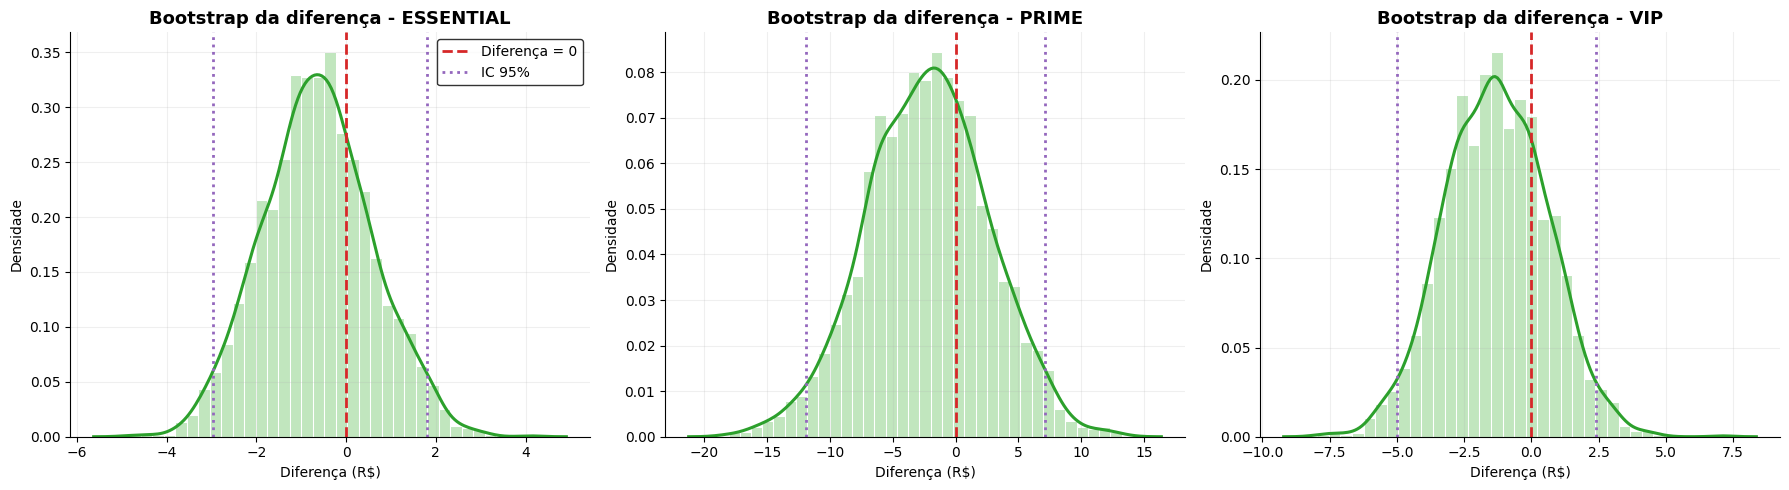

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, item in zip(axes, resultado["grupos"]):
    if item["validacao"]["n_rodadas_validas"] == 0:
        ax.set_title(f"{item['grupo']} - sem rodadas válidas")
        ax.axis("off")
        continue

    rodada = item["validacao"]["rodadas"][0]
    boot_diff = rodada["boot_diff"]
    ci_inf = rodada["ci_boot_diff_inf"]
    ci_sup = rodada["ci_boot_diff_sup"]

    sns.histplot(
        boot_diff,
        bins=35,
        stat="density",
        color="#a1d99b",
        edgecolor="white",
        alpha=0.65,
        ax=ax
    )

    sns.kdeplot(
        boot_diff,
        color="#2ca02c",
        linewidth=2.2,
        ax=ax
    )

    ax.axvline(0, color="#d62728", linestyle="--", linewidth=2, label="Diferença = 0")
    ax.axvline(ci_inf, color="#9467bd", linestyle=":", linewidth=2, label="IC 95%")
    ax.axvline(ci_sup, color="#9467bd", linestyle=":", linewidth=2)
    ax.set_title(f"Bootstrap da diferença - {item['grupo']}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Diferença (R$)")
    ax.set_ylabel("Densidade")
    ax.grid(alpha=0.20)

axes[0].legend(frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()

In [ ]:
for item in resultado["grupos"]:
    print(f"\nGrupo: {item['grupo']}")
    display(item["validacao"]["tabela_rodadas"].round(4))


Grupo: ESSENTIAL


,rodada,media_amostra,media_train,media_validation,media_test,diff_obs,ci_boot_diff_inf,ci_boot_diff_sup,p_boot,inclui_zero
0,1,391.5935,390.2066,392.8039,394.5437,-0.6737,-2.9661,1.8149,0.591,True
1,2,393.7224,394.1175,392.2916,393.9681,1.4552,-0.9596,3.7771,0.216,True
2,3,391.4727,391.7125,390.1829,392.0431,-0.7945,-3.1004,1.5713,0.542,True
3,4,392.4180,393.1999,391.1721,391.3183,0.1508,-2.2009,2.4920,0.863,True
4,5,391.6366,391.6751,392.1571,391.0008,-0.6306,-2.9362,1.7510,0.557,True
5,6,391.0952,390.6492,391.4499,392.0786,-1.1720,-3.4378,1.1243,0.306,True
6,7,391.2836,390.8420,393.5545,390.3376,-0.9836,-3.4004,1.4071,0.420,True
7,8,391.9714,391.5153,392.9580,392.3527,-0.2959,-2.5599,2.0182,0.840,True
8,9,392.1680,392.1573,394.0702,390.2982,-0.0992,-2.4758,2.2079,0.898,True
9,10,390.8251,390.2959,391.3780,391.8595,-1.4421,-3.7702,1.0230,0.246,True



Grupo: PRIME


,rodada,media_amostra,media_train,media_validation,media_test,diff_obs,ci_boot_diff_inf,ci_boot_diff_sup,p_boot,inclui_zero
0,1,2235.0638,2231.0478,2245.9802,2236.1955,-2.5054,-11.8894,7.0839,0.644,True
1,2,2233.4229,2233.9617,2235.0371,2230.1923,-4.1462,-13.2645,5.3297,0.393,True
2,3,2230.1052,2230.1691,2231.4541,2228.5648,-7.4639,-17.1989,2.4821,0.123,True
3,4,2238.4405,2239.4928,2229.8955,2243.8284,0.8713,-8.8628,10.4483,0.830,True
4,5,2235.4488,2237.6361,2235.0160,2229.3194,-2.1204,-12.0249,7.7887,0.670,True
5,6,2235.0258,2235.1425,2237.4209,2232.2803,-2.5434,-11.6816,6.6805,0.628,True
6,7,2241.1698,2243.9606,2236.2303,2237.7366,3.6006,-5.6325,13.2133,0.443,True
7,8,2240.2449,2242.9504,2236.6676,2235.7059,2.6758,-6.9289,11.7327,0.601,True
8,9,2232.5906,2230.0924,2241.4013,2231.2746,-4.9786,-14.4279,4.7123,0.294,True
9,10,2238.5405,2238.8639,2236.7131,2239.3974,0.9713,-8.7057,10.9879,0.849,True



Grupo: VIP


,rodada,media_amostra,media_train,media_validation,media_test,diff_obs,ci_boot_diff_inf,ci_boot_diff_sup,p_boot,inclui_zero
0,1,895.6567,894.7252,894.6992,899.4087,-1.2593,-5.0044,2.3905,0.502,True
1,2,897.3979,896.6581,900.5210,896.4943,0.4819,-3.1371,3.9576,0.814,True
2,3,898.7187,899.0635,897.1429,899.2601,1.8027,-2.1060,5.6031,0.354,True
3,4,898.4545,897.6560,898.9870,900.3174,1.5385,-2.0918,5.2509,0.409,True
4,5,897.9757,897.3274,898.6490,899.2474,1.0597,-2.5551,4.8298,0.554,True
5,6,897.7462,897.4796,900.2486,896.0435,0.8302,-2.7252,4.6314,0.664,True
6,7,897.8901,897.7060,897.5077,898.8248,0.9741,-2.7480,4.8505,0.580,True
7,8,898.2824,898.8139,897.4501,897.5204,1.3664,-2.4790,5.0315,0.497,True
8,9,897.8679,897.0362,899.5899,898.6411,0.9519,-2.7787,4.5825,0.622,True
9,10,896.9465,895.8115,897.9035,899.3947,0.0305,-3.8043,3.7643,0.992,True


#### A1.3.1: Teste de Normalidade

Nesta ETAPA, você deve fazer o **TESTE DE HIPÓTESE DE NORMALIDADE: Anderson-Darling' Test (AD test)** sobre:

*   SAMPLE 1:
*   SAMPLE 2:

In [ ]:
def teste_shapiro_amostra(serie, n_amostra=5000, alpha=0.05, random_state=42):
    serie = pd.to_numeric(serie, errors="coerce").dropna()

    if len(serie) == 0:
        return np.nan, np.nan, "Sem dados", serie

    n_use = min(n_amostra, len(serie))
    amostra = serie.sample(n=n_use, random_state=random_state) if len(serie) > n_use else serie.copy()

    w, p = shapiro(amostra)
    decisao = "Rejeita normalidade" if p < alpha else "Não rejeita normalidade"

    return float(w), float(p), decisao, amostra


def plot_normalidade_grupo(amostra, grupo):
    amostra = pd.to_numeric(amostra, errors="coerce").dropna()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    q_inf = amostra.quantile(0.005)
    q_sup = amostra.quantile(0.995)
    amostra_plot = amostra.clip(lower=q_inf, upper=q_sup)

    sns.histplot(
        amostra_plot,
        bins=35,
        stat="density",
        color="#9ecae1",
        edgecolor="white",
        alpha=0.60,
        ax=axes[0],
    )
    sns.kdeplot(
        amostra_plot,
        color="#08519c",
        linewidth=2.2,
        ax=axes[0],
    )

    axes[0].set_title(f"{grupo} - Distribuição de TOTAL (R$)", fontsize=13, fontweight="bold")
    axes[0].set_xlabel("TOTAL (R$)")
    axes[0].set_ylabel("Densidade")
    axes[0].grid(alpha=0.20)

    stats.probplot(amostra, dist="norm", plot=axes[1])
    axes[1].set_title(f"{grupo} - QQ-plot de TOTAL (R$)", fontsize=13, fontweight="bold")
    axes[1].grid(alpha=0.20)

    plt.tight_layout()
    sns.despine()
    plt.show()


In [ ]:
def AtividadeA1_3_1():
    if "A1.3" not in RESULTADOS:
        raise ValueError("Execute a Atividade A1.3 antes desta etapa.")

    resultados = []

    for item in RESULTADOS["A1.3"]["grupos"]:
        grupo = item["grupo"]
        amostra = pd.to_numeric(item["normalidade"]["amostra"], errors="coerce").dropna()
        tabela_rodadas = item["validacao"]["tabela_rodadas"].copy()

        erro_train = (tabela_rodadas["media_train"] - item["media_populacao"]).abs()
        erro_validation = (tabela_rodadas["media_validation"] - item["media_populacao"]).abs()
        erro_test = (tabela_rodadas["media_test"] - item["media_populacao"]).abs()

        resultados.append({
            "Grupo": grupo,
            "N população": item["N"],
            "n amostra": item["normalidade"]["n_amostra"],
            "Shapiro W": item["normalidade"]["shapiro_stat"],
            "Shapiro p-valor": item["normalidade"]["shapiro_p"],
            "Decisão normalidade": item["normalidade"]["decisao"],
            "Média amostra": float(amostra.mean()),
            "DP amostra": float(amostra.std(ddof=1)),
            "Assimetria": float(amostra.skew()),
            "Curtose": float(amostra.kurtosis()),
            "Erro médio TRAIN": float(erro_train.mean()),
            "Erro médio VALIDATION": float(erro_validation.mean()),
            "Erro médio TEST": float(erro_test.mean()),
            "Amostra": amostra,
            "Erros": pd.DataFrame({
                "Partição": ["TRAIN", "VALIDATION", "TEST"],
                "Erro médio": [erro_train.mean(), erro_validation.mean(), erro_test.mean()]
            })
        })

    df_resultados = pd.DataFrame(resultados)

    RESULTADOS["A1.3.1"] = {
        "tabela": df_resultados.drop(columns=["Amostra", "Erros"]),
        "amostras": {
            row["Grupo"]: row["Amostra"]
            for _, row in df_resultados.iterrows()
        },
        "erros_medios": {
            row["Grupo"]: row["Erros"]
            for _, row in df_resultados.iterrows()
        },
    }

    print("Teste de normalidade por grupos concluído.")
    print("Variável analisada: TOTAL (R$)")
    print(f"Grupos analisados: {len(df_resultados)}")


In [ ]:
def AtividadeA1_3_1():
    if "A1.3" not in RESULTADOS:
        raise ValueError("Execute a Atividade A1.3 antes desta etapa.")

    resultados = []

    for item in RESULTADOS["A1.3"]["grupos"]:
        grupo = item["grupo"]
        amostra = pd.to_numeric(item["normalidade"]["amostra"], errors="coerce").dropna()
        tabela_rodadas = item["validacao"]["tabela_rodadas"].copy()

        erro_train = (tabela_rodadas["media_train"] - item["media_populacao"]).abs()
        erro_validation = (tabela_rodadas["media_validation"] - item["media_populacao"]).abs()
        erro_test = (tabela_rodadas["media_test"] - item["media_populacao"]).abs()

        resultados.append({
            "Grupo": grupo,
            "N população": item["N"],
            "n amostra": item["normalidade"]["n_amostra"],
            "Shapiro W": item["normalidade"]["shapiro_stat"],
            "Shapiro p-valor": item["normalidade"]["shapiro_p"],
            "Decisão normalidade": item["normalidade"]["decisao"],
            "Média amostra": float(amostra.mean()),
            "DP amostra": float(amostra.std(ddof=1)),
            "Assimetria": float(amostra.skew()),
            "Curtose": float(amostra.kurtosis()),
            "Erro médio TRAIN": float(erro_train.mean()),
            "Erro médio VALIDATION": float(erro_validation.mean()),
            "Erro médio TEST": float(erro_test.mean()),
            "Amostra": amostra,
            "Erros": pd.DataFrame({
                "Partição": ["TRAIN", "VALIDATION", "TEST"],
                "Erro médio": [erro_train.mean(), erro_validation.mean(), erro_test.mean()]
            })
        })

    df_resultados = pd.DataFrame(resultados)

    RESULTADOS["A1.3.1"] = {
        "tabela": df_resultados.drop(columns=["Amostra", "Erros"]),
        "amostras": {
            row["Grupo"]: row["Amostra"]
            for _, row in df_resultados.iterrows()
        },
        "erros_medios": {
            row["Grupo"]: row["Erros"]
            for _, row in df_resultados.iterrows()
        },
    }

    print("Teste de normalidade por grupos concluído.")
    print("Variável analisada: TOTAL (R$)")
    print(f"Grupos analisados: {len(df_resultados)}")


In [ ]:
AtividadeA1_3_1()

resultado = RESULTADOS["A1.3.1"]

tabela_normalidade = resultado["tabela"].copy()
tabela_normalidade[[
    "Shapiro W",
    "Shapiro p-valor",
    "Média amostra",
    "DP amostra",
    "Assimetria",
    "Curtose",
    "Erro médio TRAIN",
    "Erro médio VALIDATION",
    "Erro médio TEST"
]] = tabela_normalidade[[
    "Shapiro W",
    "Shapiro p-valor",
    "Média amostra",
    "DP amostra",
    "Assimetria",
    "Curtose",
    "Erro médio TRAIN",
    "Erro médio VALIDATION",
    "Erro médio TEST"
]].round(4)

display(tabela_normalidade)


Teste de normalidade por grupos concluído.
Variável analisada: TOTAL (R$)
Grupos analisados: 3


,Grupo,N população,n amostra,Shapiro W,Shapiro p-valor,Decisão normalidade,Média amostra,DP amostra,Assimetria,Curtose,Erro médio TRAIN,Erro médio VALIDATION,Erro médio TEST
0,ESSENTIAL,700015,5000,0.6095,0.0,Rejeita normalidade,394.4028,262.6344,5.0992,40.3144,1.0790,0.9989,1.2718
1,PRIME,175002,5000,0.9788,0.0,Rejeita normalidade,2249.6373,1043.7087,0.1385,-0.9084,3.7923,4.0911,4.1597
2,VIP,244983,5000,0.9087,0.0,Rejeita normalidade,891.2378,423.2141,1.3739,4.9271,0.8963,1.6193,2.0575


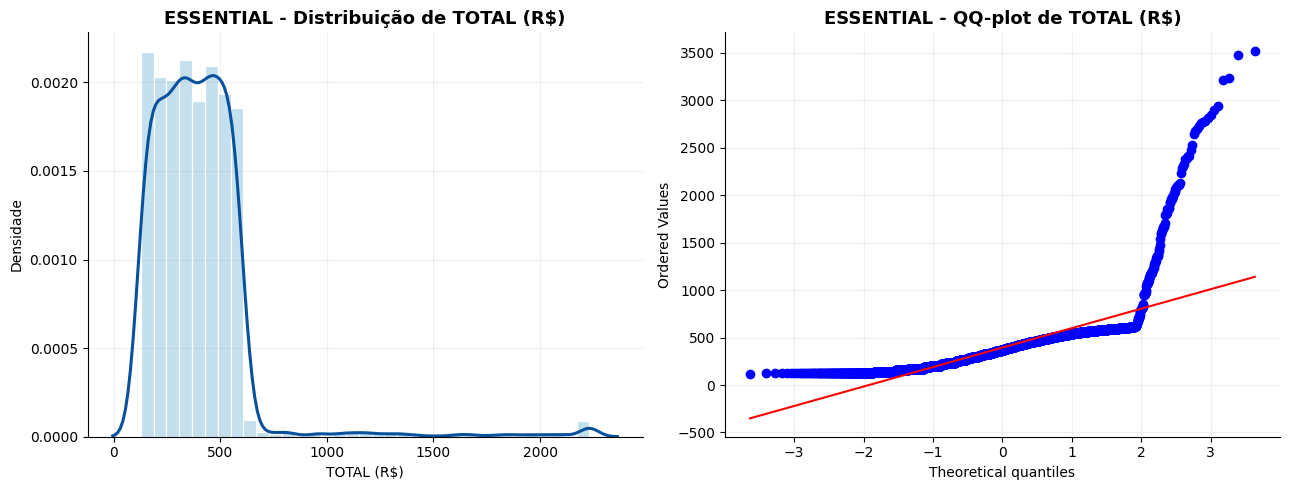

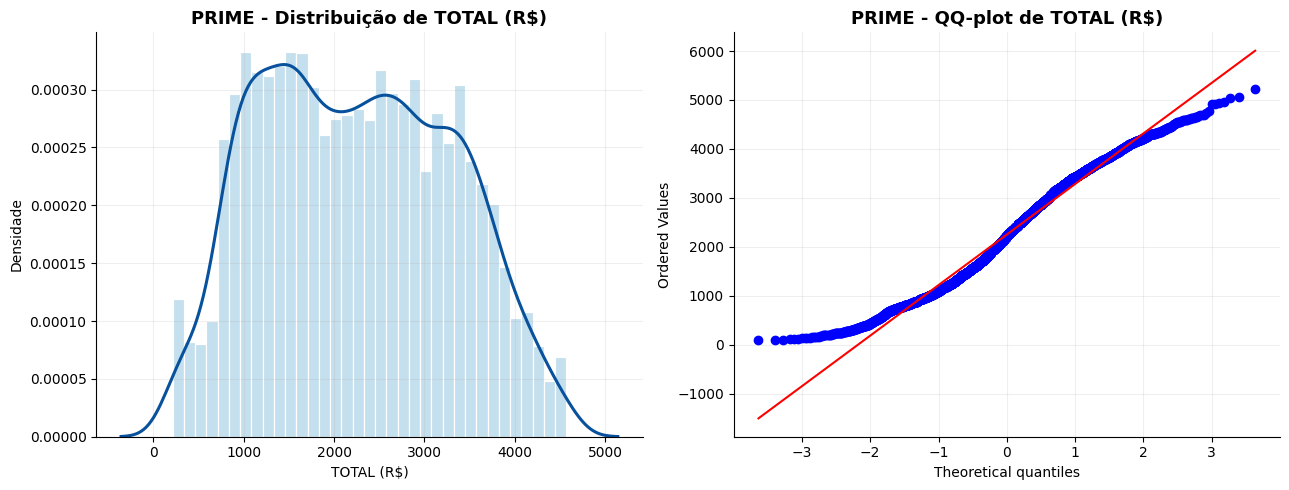

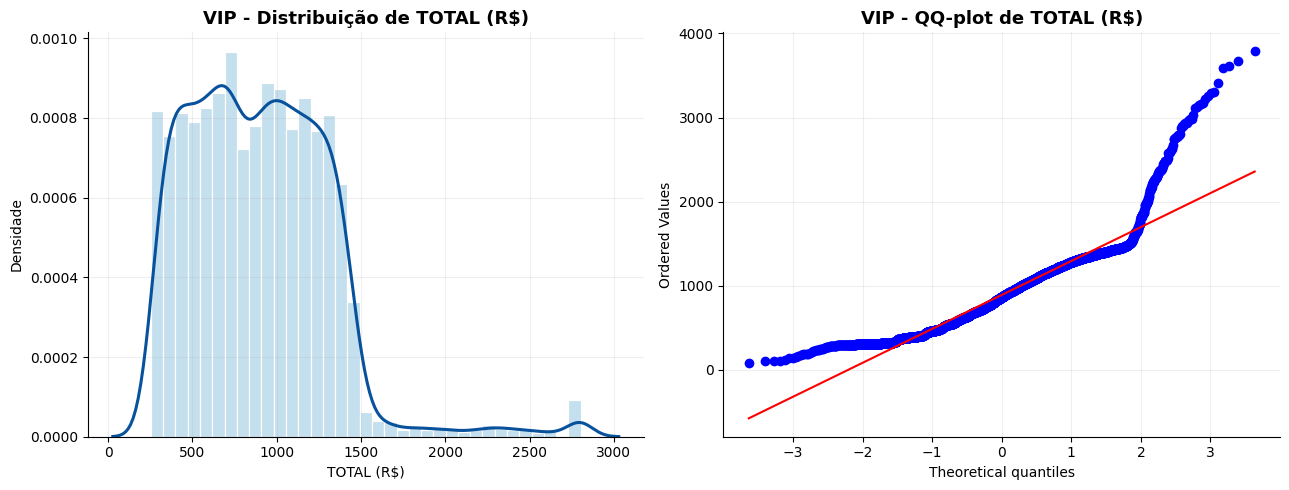

In [ ]:
for grupo, amostra in resultado["amostras"].items():
    plot_normalidade_grupo(amostra, grupo)



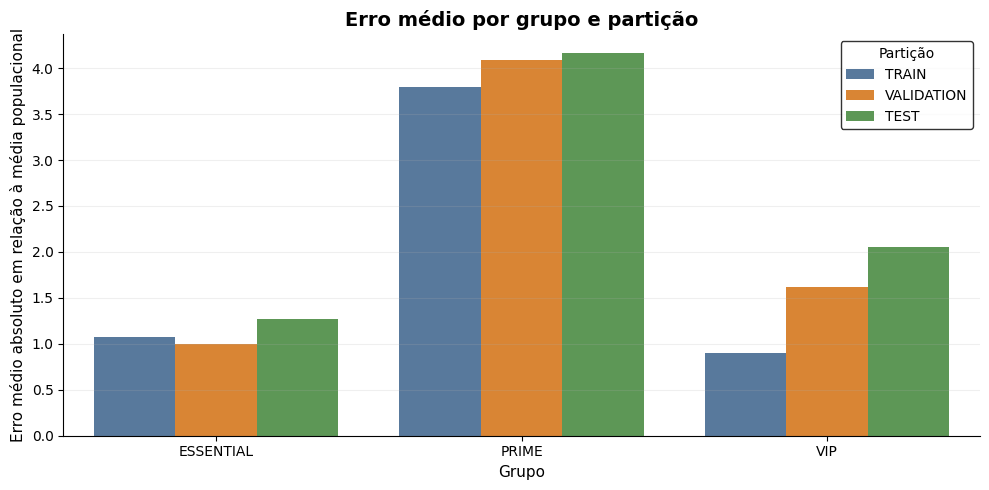

In [ ]:
dados_erro = []

for grupo, df_erro in resultado["erros_medios"].items():
    temp = df_erro.copy()
    temp["Grupo"] = grupo
    dados_erro.append(temp)

dados_erro = pd.concat(dados_erro, ignore_index=True)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=dados_erro,
    x="Grupo",
    y="Erro médio",
    hue="Partição",
    palette=["#4C78A8", "#F58518", "#54A24B"]
)

plt.title("Erro médio por grupo e partição", fontsize=14, fontweight="bold")
plt.xlabel("Grupo", fontsize=11)
plt.ylabel("Erro médio absoluto em relação à média populacional", fontsize=11)
plt.grid(axis="y", alpha=0.20)
plt.legend(title="Partição", frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()


In [ ]:
auditoria_discretizacao = []

for grupo in ["ESSENTIAL", "PRIME", "VIP"]:
    df_grupo = RESULTADOS.get("A1.2", {}).get("table_limpa", table).copy()
    df_grupo = df_grupo[df_grupo["TIPO DA CONTA"] == grupo]

    for var in ["RENDA BRUTO (R$)", "TOTAL (R$)"]:
        serie = pd.to_numeric(df_grupo[var], errors="coerce").dropna()

        freq = serie.value_counts()
        perc_moda = float((freq.iloc[0] / len(serie)) * 100)
        ratio_unicos = float((serie.nunique() / len(serie)) * 100)

        auditoria_discretizacao.append({
            "Grupo": grupo,
            "Variável": var,
            "N": int(len(serie)),
            "Valores únicos": int(serie.nunique()),
            "% únicos": ratio_unicos,
            "Moda": float(freq.index[0]),
            "% moda": perc_moda,
            "Top 5 %": float((freq.iloc[:5].sum() / len(serie)) * 100)
        })

auditoria_discretizacao = pd.DataFrame(auditoria_discretizacao)
display(auditoria_discretizacao.round(4))


,Grupo,Variável,N,Valores únicos,% únicos,Moda,% moda,Top 5 %
0,ESSENTIAL,RENDA BRUTO (R$),700015,70824,10.1175,3226.31,0.0083,0.0384
1,ESSENTIAL,TOTAL (R$),700015,65942,9.4201,131.65,0.0101,0.0491
2,PRIME,RENDA BRUTO (R$),175002,158815,90.7504,17053.53,0.0029,0.0143
3,PRIME,TOTAL (R$),175002,139818,79.8951,1377.19,0.0040,0.0177
4,VIP,RENDA BRUTO (R$),244983,136576,55.7492,7744.66,0.0049,0.0229
5,VIP,TOTAL (R$),244983,108693,44.3676,309.01,0.0057,0.0278


In [ ]:
percentis_normalidade = []

for grupo in ["ESSENTIAL", "PRIME", "VIP"]:
    df_grupo = RESULTADOS.get("A1.2", {}).get("table_limpa", table).copy()
    df_grupo = df_grupo[df_grupo["TIPO DA CONTA"] == grupo]

    for var in ["RENDA BRUTO (R$)", "TOTAL (R$)"]:
        serie = pd.to_numeric(df_grupo[var], errors="coerce").dropna()

        percentis_normalidade.append({
            "Grupo": grupo,
            "Variável": var,
            "P1": float(serie.quantile(0.01)),
            "P5": float(serie.quantile(0.05)),
            "P25": float(serie.quantile(0.25)),
            "P50": float(serie.quantile(0.50)),
            "P75": float(serie.quantile(0.75)),
            "P95": float(serie.quantile(0.95)),
            "P99": float(serie.quantile(0.99)),
        })

percentis_normalidade = pd.DataFrame(percentis_normalidade)
display(percentis_normalidade.round(2))


,Grupo,Variável,P1,P5,P25,P50,P75,P95,P99
0,ESSENTIAL,RENDA BRUTO (R$),3051.70,3113.77,3196.99,3254.86,3314.42,3426.60,15796.67
1,ESSENTIAL,TOTAL (R$),128.63,134.54,236.05,365.06,491.34,592.98,1699.51
2,PRIME,RENDA BRUTO (R$),3196.59,8667.88,19101.02,21226.48,23115.09,25619.86,27376.01
3,PRIME,TOTAL (R$),289.65,733.11,1365.96,2182.39,3063.90,3961.52,4434.84
4,VIP,RENDA BRUTO (R$),3718.36,7197.80,7558.09,7768.08,7987.58,11746.07,19339.22
5,VIP,TOTAL (R$),292.29,317.66,560.89,866.40,1171.64,1436.70,2523.41


O teste de Shapiro-Wilk foi aplicado sobre a variável TOTAL (R$) utilizando amostras de 5.000 registros de cada grupo.

Resultados:

Grupo	Shapiro W	p-valor	Resultado

ESSENTIAL	0,6095	0,0000	Rejeita normalidade

PRIME	0,9788	0,0000	Rejeita normalidade

VIP	0,9087	0,0000	Rejeita normalidade

O teste de normalidade rejeitou a hipótese de distribuição normal para os três grupos. Portanto, a variável TOTAL (R$) não apresenta comportamento normal nos segmentos ESSENTIAL, PRIME e VIP. Esse resultado reforça a importância da utilização de métodos de reamostragem, como o Bootstrap, para obter estimativas mais robustas dos intervalos de confiança.

#### A1.3.2: Teste de Independência

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Testes de Independência: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

In [ ]:
def interpretar_cramers_v(v):
    if np.isnan(v):
        return "N/A"
    if v < 0.05:
        return "Efeito desprezível"
    if v < 0.10:
        return "Efeito fraco"
    if v < 0.30:
        return "Efeito moderado"
    return "Efeito forte"


def preparar_tabela_particoes(tentativas_log):
    df = tentativas_log.copy()

    df_long = df.melt(
        id_vars=["tentativa", "aceita"],
        value_vars=["status_train", "status_validation", "status_test"],
        var_name="Partição",
        value_name="Status IC"
    )

    mapa_particao = {
        "status_train": "TRAIN",
        "status_validation": "VALIDATION",
        "status_test": "TEST"
    }

    df_long["Partição"] = df_long["Partição"].map(mapa_particao)

    contingencia = pd.crosstab(df_long["Partição"], df_long["Status IC"])
    return df_long, contingencia



In [ ]:
from scipy.stats import chi2_contingency

def AtividadeA1_3_2():
    if "A1.3" not in RESULTADOS:
        raise ValueError("Execute a Atividade A1.3 antes desta etapa.")

    resultados = []

    for item in RESULTADOS["A1.3"]["grupos"]:
        grupo = item["grupo"]
        tentativas_log = item["validacao"]["tentativas_log"].copy()

        df_long, cont = preparar_tabela_particoes(tentativas_log)
        n_validos = int(cont.values.sum())

        chi2, p_val, dof, expected = chi2_contingency(cont.values, correction=False)
        decisao = "Rejeita H0" if p_val < 0.05 else "Não rejeita H0"

        r, c = cont.shape
        k = min(r - 1, c - 1)
        cramers_v = np.sqrt((chi2 / n_validos) / k) if (k > 0 and n_validos > 0) else np.nan
        interpretacao_v = interpretar_cramers_v(cramers_v)

        expected_df = pd.DataFrame(expected, index=cont.index, columns=cont.columns)
        qtd_expected_lt5 = int((expected_df < 5).sum().sum())
        total_celulas = int(expected_df.size)
        perc_expected_lt5 = (qtd_expected_lt5 / total_celulas) * 100 if total_celulas > 0 else np.nan

        residuos = (cont - expected_df) / np.sqrt(expected_df)
        residuos = residuos.replace([np.inf, -np.inf], np.nan)

        top_residuos = (
            residuos.abs()
            .stack()
            .sort_values(ascending=False)
            .head(10)
            .reset_index()
        )
        top_residuos.columns = ["Partição", "Status IC", "|Resíduo padronizado|"]

        percentuais = cont.div(cont.sum(axis=1), axis=0) * 100

        resultados.append({
            "Grupo": grupo,
            "n_validos": n_validos,
            "chi2": float(chi2),
            "p_value": float(p_val),
            "dof": int(dof),
            "decisao": decisao,
            "cramers_v": float(cramers_v) if not np.isnan(cramers_v) else None,
            "interpretacao_cramers_v": interpretacao_v,
            "qtd_expected_lt5": int(qtd_expected_lt5),
            "perc_expected_lt5": float(perc_expected_lt5) if np.isfinite(perc_expected_lt5) else None,
            "contingencia": cont,
            "esperadas": expected_df,
            "residuos_padronizados": residuos,
            "top_residuos": top_residuos,
            "percentuais": percentuais,
        })

    RESULTADOS["A1.3.2"] = {
        "resultados_por_grupo": resultados
    }

    print("Teste de independência por grupos concluído.")
    print(f"Grupos analisados: {len(resultados)}")


In [ ]:
AtividadeA1_3_2()

resultado = RESULTADOS["A1.3.2"]


Teste de independência por grupos concluído.
Grupos analisados: 3


In [ ]:
resumo_independencia = pd.DataFrame([
    {
        "Grupo": item["Grupo"],
        "N válidos": item["n_validos"],
        "Qui-quadrado": item["chi2"],
        "gl": item["dof"],
        "p-valor": item["p_value"],
        "Decisão": item["decisao"],
        "Cramér's V": item["cramers_v"],
        "Interpretação": item["interpretacao_cramers_v"],
        "% esperado < 5": item["perc_expected_lt5"],
    }
    for item in resultado["resultados_por_grupo"]
])

resumo_independencia[["Qui-quadrado", "p-valor", "Cramér's V", "% esperado < 5"]] = (
    resumo_independencia[["Qui-quadrado", "p-valor", "Cramér's V", "% esperado < 5"]].round(4)
)

display(resumo_independencia)


,Grupo,N válidos,Qui-quadrado,gl,p-valor,Decisão,Cramér's V,Interpretação,% esperado < 5
0,ESSENTIAL,126,3.4125,2,0.1815,Não rejeita H0,0.1646,Efeito moderado,0.0
1,PRIME,156,4.6218,2,0.0992,Não rejeita H0,0.1721,Efeito moderado,0.0
2,VIP,180,10.2633,2,0.0059,Rejeita H0,0.2388,Efeito moderado,0.0


In [ ]:
for item in resultado["resultados_por_grupo"]:
    print(f"\nGrupo: {item['Grupo']}")
    display(item["contingencia"])
    display(item["top_residuos"])



Grupo: ESSENTIAL


Status IC,Dentro do IC,Fora do IC
Partição,,
TEST,31,11
TRAIN,36,6
VALIDATION,29,13


,Partição,Status IC,|Resíduo padronizado|
0,TRAIN,Fora do IC,1.264911
1,VALIDATION,Fora do IC,0.948683
2,TRAIN,Dentro do IC,0.707107
3,VALIDATION,Dentro do IC,0.530330
4,TEST,Fora do IC,0.316228
5,TEST,Dentro do IC,0.176777



Grupo: PRIME


Status IC,Dentro do IC,Fora do IC
Partição,,
TEST,35,17
TRAIN,43,9
VALIDATION,34,18


,Partição,Status IC,|Resíduo padronizado|
0,TRAIN,Fora do IC,1.479660
1,TRAIN,Dentro do IC,0.927426
2,VALIDATION,Fora do IC,0.870388
3,TEST,Fora do IC,0.609272
4,VALIDATION,Dentro do IC,0.545545
5,TEST,Dentro do IC,0.381881



Grupo: VIP


Status IC,Dentro do IC,Fora do IC
Partição,,
TEST,43,17
TRAIN,49,11
VALIDATION,33,27


,Partição,Status IC,|Resíduo padronizado|
0,VALIDATION,Fora do IC,2.024097
1,TRAIN,Fora do IC,1.712698
2,VALIDATION,Dentro do IC,1.342634
3,TRAIN,Dentro do IC,1.136075
4,TEST,Fora do IC,0.311400
5,TEST,Dentro do IC,0.206559


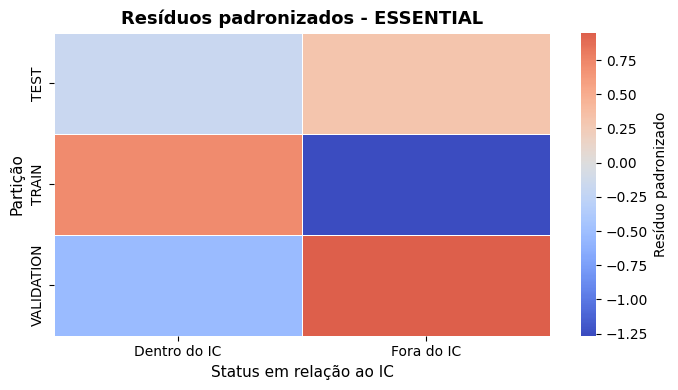

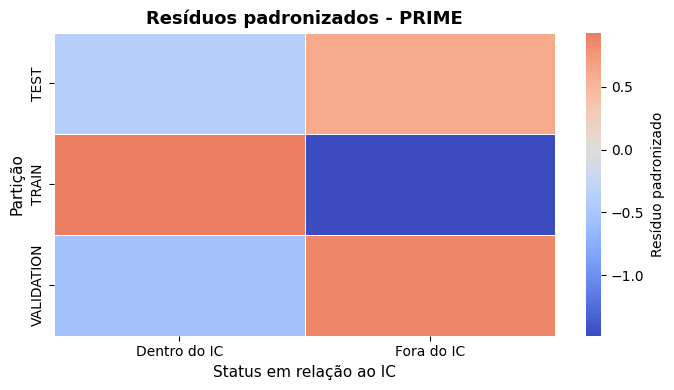

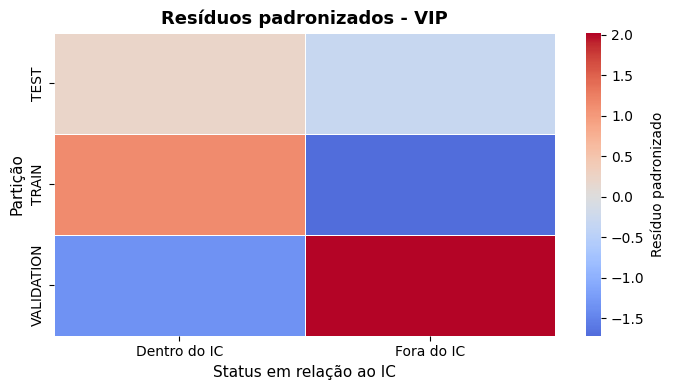

In [ ]:
for item in resultado["resultados_por_grupo"]:
    plt.figure(figsize=(7, 4))

    sns.heatmap(
        item["residuos_padronizados"],
        cmap="coolwarm",
        center=0,
        linewidths=0.6,
        linecolor="white",
        cbar_kws={"label": "Resíduo padronizado"},
    )

    plt.title(
        f"Resíduos padronizados - {item['Grupo']}",
        fontsize=13,
        fontweight="bold",
    )
    plt.xlabel("Status em relação ao IC", fontsize=11)
    plt.ylabel("Partição", fontsize=11)

    plt.tight_layout()
    sns.despine(left=True, bottom=True)
    plt.show()


In [ ]:
for item in resultado["resultados_por_grupo"]:
    print(f"\nGrupo: {item['Grupo']} - percentuais por partição")
    display(item["percentuais"].round(2))



Grupo: ESSENTIAL - percentuais por partição


Status IC,Dentro do IC,Fora do IC
Partição,,
TEST,73.81,26.19
TRAIN,85.71,14.29
VALIDATION,69.05,30.95



Grupo: PRIME - percentuais por partição


Status IC,Dentro do IC,Fora do IC
Partição,,
TEST,67.31,32.69
TRAIN,82.69,17.31
VALIDATION,65.38,34.62



Grupo: VIP - percentuais por partição


Status IC,Dentro do IC,Fora do IC
Partição,,
TEST,71.67,28.33
TRAIN,81.67,18.33
VALIDATION,55.00,45.00


Foi realizado o teste de independência entre as partições e o status do intervalo de confiança.

Grupo	p-valor	Decisão	Cramér's V

ESSENTIAL	0,1815	Não rejeita H0	0,1646

PRIME	0,0992	Não rejeita H0	0,1721

VIP	0,0059	Rejeita H0	0,2388

Para os grupos ESSENTIAL e PRIME, não foram encontradas evidências estatísticas suficientes para rejeitar a hipótese de independência entre as partições e o status do intervalo de confiança. Já no grupo VIP, a hipótese de independência foi rejeitada, indicando uma associação estatisticamente significativa. Apesar disso, o valor de Cramér's V indica um efeito moderado, não sendo uma associação de grande magnitude.

**RESPONDER: SAMPLE 1 e SAMPLE 2 são INDEPENDENTES ???**

CONCLUIR / RESPONDER AQUI:
*   ???
*   ???

#### A1.3.3: Teste de Distribuição

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Teste de Mesma Distribuição: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

In [ ]:
def calcular_iqr(serie):
    return float(serie.quantile(0.75) - serie.quantile(0.25))


def preparar_dados_levene(dados, coluna_valor, coluna_grupo):
    df = dados[[coluna_valor, coluna_grupo]].copy()

    df = df.dropna(subset=[coluna_valor, coluna_grupo])
    df[coluna_grupo] = df[coluna_grupo].astype(str).str.strip()
    df = df[df[coluna_grupo] != ""]

    df[coluna_valor] = pd.to_numeric(df[coluna_valor], errors="coerce")
    df = df.dropna(subset=[coluna_valor])
    df = df[df[coluna_valor] >= 0]

    return df



In [ ]:
from scipy.stats import levene

def AtividadeA1_3_3():
    if "A1.3" not in RESULTADOS:
        raise ValueError("Execute a Atividade A1.3 antes desta etapa.")

    resultados = []

    for item in RESULTADOS["A1.3"]["grupos"]:
        grupo = item["grupo"]
        df = item["validacao"]["tabela_rodadas"].copy()

        train = df["media_train"].values
        validation = df["media_validation"].values
        test = df["media_test"].values

        estatistica, p_valor = levene(train, validation, test, center="median")
        decisao = "Rejeita H0" if p_valor < 0.05 else "Não rejeita H0"

        resumo = pd.DataFrame({
            "Partição": ["TRAIN", "VALIDATION", "TEST"],
            "n": [len(train), len(validation), len(test)],
            "media": [np.mean(train), np.mean(validation), np.mean(test)],
            "dp": [np.std(train, ddof=1), np.std(validation, ddof=1), np.std(test, ddof=1)],
            "mediana": [np.median(train), np.median(validation), np.median(test)],
            "q1": [np.quantile(train, 0.25), np.quantile(validation, 0.25), np.quantile(test, 0.25)],
            "q3": [np.quantile(train, 0.75), np.quantile(validation, 0.75), np.quantile(test, 0.75)],
        })
        resumo["iqr"] = resumo["q3"] - resumo["q1"]

        resultados.append({
            "Grupo": grupo,
            "Estatística de Levene": float(estatistica),
            "p-valor": float(p_valor),
            "Decisão": decisao,
            "Resumo": resumo,
            "Dados": df,
        })

    RESULTADOS["A1.3.3"] = {
        "resultados_por_grupo": resultados
    }

    print("Teste de distribuição por grupos concluído.")
    print(f"Grupos analisados: {len(resultados)}")


In [ ]:
AtividadeA1_3_3()
resultado = RESULTADOS["A1.3.3"]

Teste de distribuição por grupos concluído.
Grupos analisados: 3


In [ ]:
resumo_levene = pd.DataFrame([
    {
        "Grupo": item["Grupo"],
        "Estatística de Levene": item["Estatística de Levene"],
        "p-valor": item["p-valor"],
        "Decisão": item["Decisão"],
    }
    for item in resultado["resultados_por_grupo"]
])

display(resumo_levene.round(4))

,Grupo,Estatística de Levene,p-valor,Decisão
0,ESSENTIAL,0.9904,0.3777,Não rejeita H0
1,PRIME,0.0778,0.9252,Não rejeita H0
2,VIP,2.5294,0.0886,Não rejeita H0


In [ ]:
for item in resultado["resultados_por_grupo"]:
    print(f"\nGrupo: {item['Grupo']}")
    display(item["Resumo"].round(4))



Grupo: ESSENTIAL


,Partição,n,media,dp,mediana,q1,q3,iqr
0,TRAIN,20,392.0185,1.2611,391.7184,391.0595,392.9098,1.8504
1,VALIDATION,20,391.8735,1.1879,392.0113,391.0916,392.8028,1.7112
2,TEST,20,392.4258,1.4950,392.1386,391.2389,393.9829,2.7440



Grupo: PRIME


,Partição,n,media,dp,mediana,q1,q3,iqr
0,TRAIN,20,2236.7512,4.5185,2237.8079,2232.9064,2239.5074,6.6010
1,VALIDATION,20,2237.7733,4.9449,2236.6903,2234.5891,2241.5855,6.9963
2,TEST,20,2236.3590,5.0367,2236.7282,2232.0289,2239.7298,7.7010



Grupo: VIP


,Partição,n,media,dp,mediana,q1,q3,iqr
0,TRAIN,20,897.0066,1.1844,896.9564,896.5291,897.6685,1.1395
1,VALIDATION,20,898.1050,1.6268,897.9935,897.2816,899.4493,2.1677
2,TEST,20,897.9831,2.0854,898.7330,896.3816,899.4207,3.0391


/tmp/ipykernel_1263/320070765.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


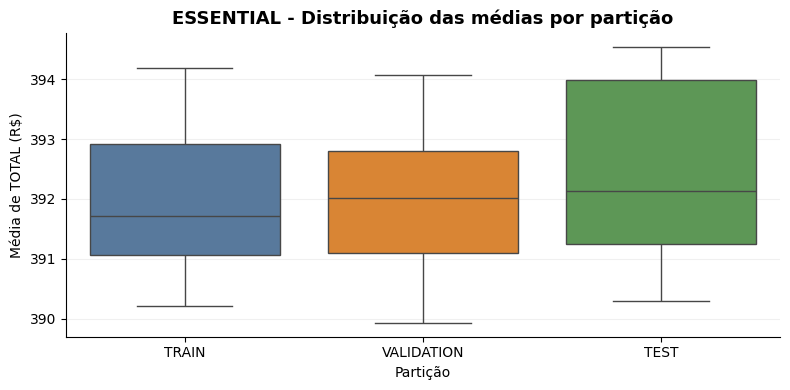

/tmp/ipykernel_1263/320070765.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


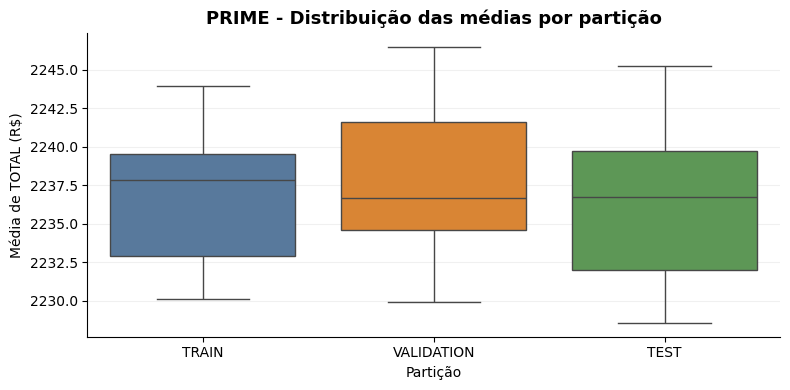

/tmp/ipykernel_1263/320070765.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


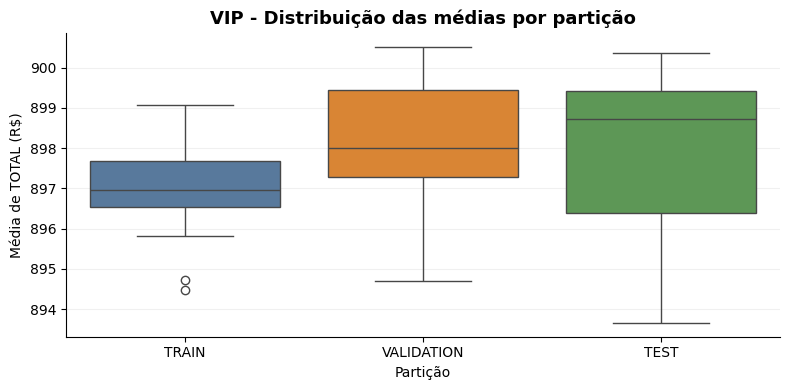

In [ ]:
for item in resultado["resultados_por_grupo"]:
    df_plot = item["Dados"][["media_train", "media_validation", "media_test"]].copy()
    df_plot.columns = ["TRAIN", "VALIDATION", "TEST"]

    df_long = df_plot.melt(var_name="Partição", value_name="Média")

    plt.figure(figsize=(8, 4))
    sns.boxplot(
        data=df_long,
        x="Partição",
        y="Média",
        palette=["#4C78A8", "#F58518", "#54A24B"]
    )
    plt.title(f"{item['Grupo']} - Distribuição das médias por partição", fontsize=13, fontweight="bold")
    plt.xlabel("Partição")
    plt.ylabel("Média de TOTAL (R$)")
    plt.grid(axis="y", alpha=0.18)
    plt.tight_layout()
    sns.despine()
    plt.show()


Foi utilizado o teste de Levene para verificar se a variabilidade das três partições — TRAIN, VALIDATION e TEST — era diferente.

Grupo	Estatística	p-valor	Decisão

ESSENTIAL	0,9904	0,3777	Não rejeita H0

PRIME	0,0778	0,9252	Não rejeita H0

VIP	2,5294	0,0886	Não rejeita H0

O teste de Levene não apresentou diferenças estatisticamente significativas na variabilidade entre TRAIN, VALIDATION e TEST em nenhum dos três grupos. Portanto, as partições apresentam dispersões estatisticamente compatíveis, indicando que o processo de divisão das amostras manteve uma distribuição de variabilidade consistente entre os conjuntos.

**RESPONDER: SAMPLE 1 e SAMPLE 2 tem a MESMA DISTRIBUIÇÃO DOS DADOS ???**

CONCLUIR / RESPONDER AQUI:
*   ???
*   ???

#### A1.3.4: Teste das Médias Amostrais

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Teste das Médias Amostrais: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

In [ ]:
def corrigir_holm(p_values):
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)
    ordem = np.argsort(p_values)
    ajustados = np.empty(m, dtype=float)

    anterior = 0.0
    for rank, idx in enumerate(ordem):
        valor = min(1.0, (m - rank) * p_values[idx])
        valor = max(valor, anterior)
        ajustados[idx] = valor
        anterior = valor

    return ajustados



In [ ]:
from scipy.stats import friedmanchisquare, wilcoxon

def AtividadeA1_3_4():
    if "A1.3" not in RESULTADOS:
        raise ValueError("Execute a Atividade A1.3 antes desta etapa.")

    resultados = []

    for item in RESULTADOS["A1.3"]["grupos"]:
        grupo = item["grupo"]
        df = item["validacao"]["tabela_rodadas"].copy()

        train = df["media_train"].values
        validation = df["media_validation"].values
        test = df["media_test"].values

        estatistica, p_valor = friedmanchisquare(train, validation, test)
        decisao = "Rejeita H0" if p_valor < 0.05 else "Não rejeita H0"

        pares = [
            ("TRAIN", "VALIDATION", train, validation),
            ("TRAIN", "TEST", train, test),
            ("VALIDATION", "TEST", validation, test),
        ]

        resultados_pares = []
        p_brutos = []

        for nome_a, nome_b, a, b in pares:
            try:
                stat_w, p_w = wilcoxon(a, b)
            except ValueError:
                stat_w, p_w = 0.0, 1.0

            resultados_pares.append([nome_a, nome_b, float(stat_w), float(p_w)])
            p_brutos.append(float(p_w))

        posthoc = pd.DataFrame(
            resultados_pares,
            columns=["grupo_1", "grupo_2", "estatistica", "p_value"]
        )
        posthoc["p_holm"] = corrigir_holm(posthoc["p_value"].values)
        posthoc["diferença_significativa"] = posthoc["p_holm"] < 0.05

        resumo = pd.DataFrame({
            "Partição": ["TRAIN", "VALIDATION", "TEST"],
            "media": [np.mean(train), np.mean(validation), np.mean(test)],
            "dp": [np.std(train, ddof=1), np.std(validation, ddof=1), np.std(test, ddof=1)],
            "mediana": [np.median(train), np.median(validation), np.median(test)],
            "q1": [np.quantile(train, 0.25), np.quantile(validation, 0.25), np.quantile(test, 0.25)],
            "q3": [np.quantile(train, 0.75), np.quantile(validation, 0.75), np.quantile(test, 0.75)],
        })
        resumo["iqr"] = resumo["q3"] - resumo["q1"]

        resultados.append({
            "Grupo": grupo,
            "Estatística de Friedman": float(estatistica),
            "p-valor": float(p_valor),
            "Decisão": decisao,
            "Resumo": resumo,
            "Posthoc": posthoc,
        })

    RESULTADOS["A1.3.4"] = {
        "resultados_por_grupo": resultados
    }

    print("Teste das médias amostrais por grupos concluído.")
    print(f"Grupos analisados: {len(resultados)}")


In [ ]:
AtividadeA1_3_4()
resultado = RESULTADOS["A1.3.4"]

Teste das médias amostrais por grupos concluído.
Grupos analisados: 3


In [ ]:
resumo_friedman = pd.DataFrame([
    {
        "Grupo": item["Grupo"],
        "Estatística de Friedman": item["Estatística de Friedman"],
        "p-valor": item["p-valor"],
        "Decisão": item["Decisão"],
    }
    for item in resultado["resultados_por_grupo"]
])

display(resumo_friedman.round(4))

,Grupo,Estatística de Friedman,p-valor,Decisão
0,ESSENTIAL,0.7,0.7047,Não rejeita H0
1,PRIME,0.4,0.8187,Não rejeita H0
2,VIP,3.1,0.2122,Não rejeita H0


In [ ]:
for item in resultado["resultados_por_grupo"]:
    print(f"\nGrupo: {item['Grupo']}")
    display(item["Resumo"].round(4))
    display(item["Posthoc"].sort_values("p_holm").round(4))


Grupo: ESSENTIAL


,Partição,media,dp,mediana,q1,q3,iqr
0,TRAIN,392.0185,1.2611,391.7184,391.0595,392.9098,1.8504
1,VALIDATION,391.8735,1.1879,392.0113,391.0916,392.8028,1.7112
2,TEST,392.4258,1.4950,392.1386,391.2389,393.9829,2.7440


,grupo_1,grupo_2,estatistica,p_value,p_holm,diferença_significativa
2,VALIDATION,TEST,70.0,0.2024,0.6073,False
0,TRAIN,VALIDATION,99.0,0.8408,0.8609,False
1,TRAIN,TEST,83.0,0.4304,0.8609,False



Grupo: PRIME


,Partição,media,dp,mediana,q1,q3,iqr
0,TRAIN,2236.7512,4.5185,2237.8079,2232.9064,2239.5074,6.6010
1,VALIDATION,2237.7733,4.9449,2236.6903,2234.5891,2241.5855,6.9963
2,TEST,2236.3590,5.0367,2236.7282,2232.0289,2239.7298,7.7010


,grupo_1,grupo_2,estatistica,p_value,p_holm,diferença_significativa
2,VALIDATION,TEST,74.0,0.2611,0.7833,False
0,TRAIN,VALIDATION,96.0,0.7562,1.0000,False
1,TRAIN,TEST,93.0,0.6742,1.0000,False



Grupo: VIP


,Partição,media,dp,mediana,q1,q3,iqr
0,TRAIN,897.0066,1.1844,896.9564,896.5291,897.6685,1.1395
1,VALIDATION,898.1050,1.6268,897.9935,897.2816,899.4493,2.1677
2,TEST,897.9831,2.0854,898.7330,896.3816,899.4207,3.0391


,grupo_1,grupo_2,estatistica,p_value,p_holm,diferença_significativa
0,TRAIN,VALIDATION,42.0,0.0172,0.0515,False
1,TRAIN,TEST,57.0,0.0759,0.1517,False
2,VALIDATION,TEST,99.0,0.8408,0.8408,False


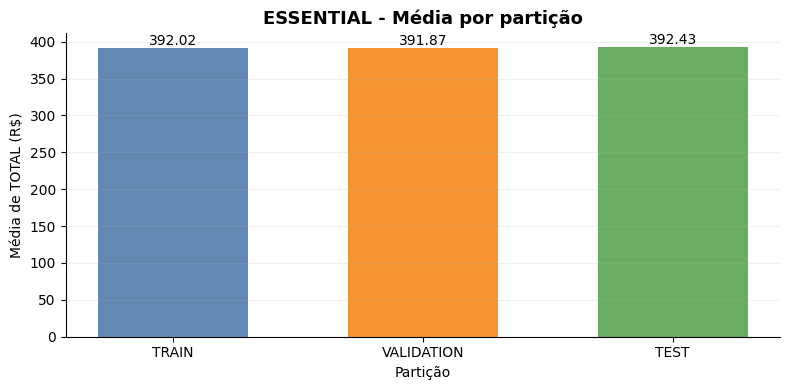

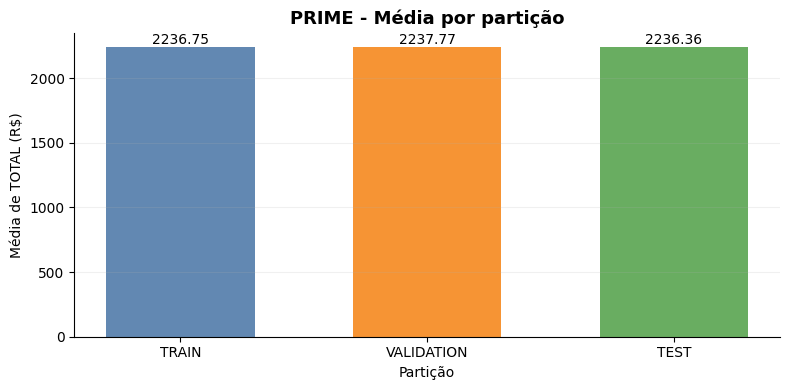

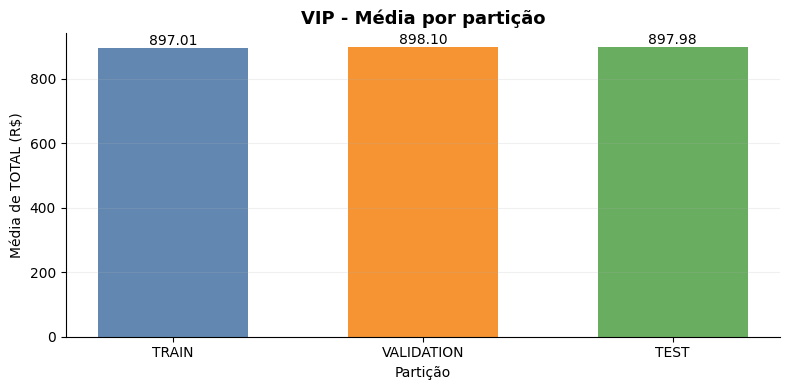

In [ ]:
for item in resultado["resultados_por_grupo"]:
    resumo_plot = item["Resumo"].copy()

    plt.figure(figsize=(8, 4))
    bars = plt.bar(
        resumo_plot["Partição"],
        resumo_plot["media"],
        color=["#4C78A8", "#F58518", "#54A24B"],
        alpha=0.88,
        width=0.6,
    )

    for bar, valor in zip(bars, resumo_plot["media"]):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            valor,
            f"{valor:.2f}",
            ha="center",
            va="bottom",
            fontsize=10,
        )

    plt.title(f"{item['Grupo']} - Média por partição", fontsize=13, fontweight="bold")
    plt.xlabel("Partição")
    plt.ylabel("Média de TOTAL (R$)")
    plt.grid(axis="y", alpha=0.18)
    plt.tight_layout()
    sns.despine()
    plt.show()


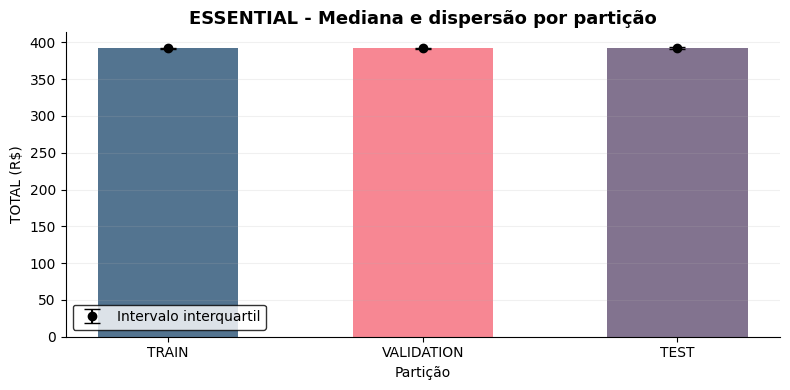

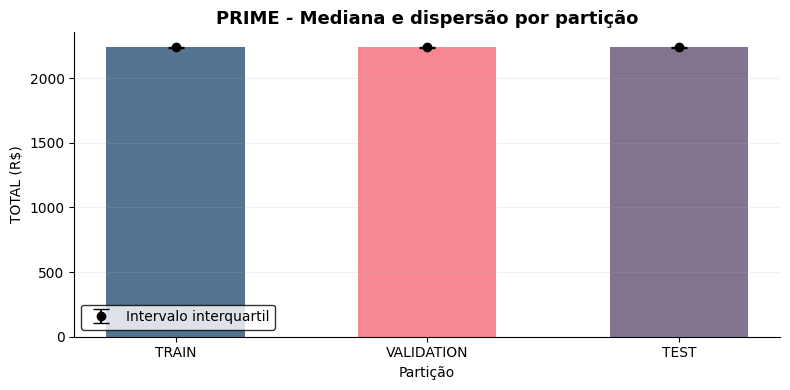

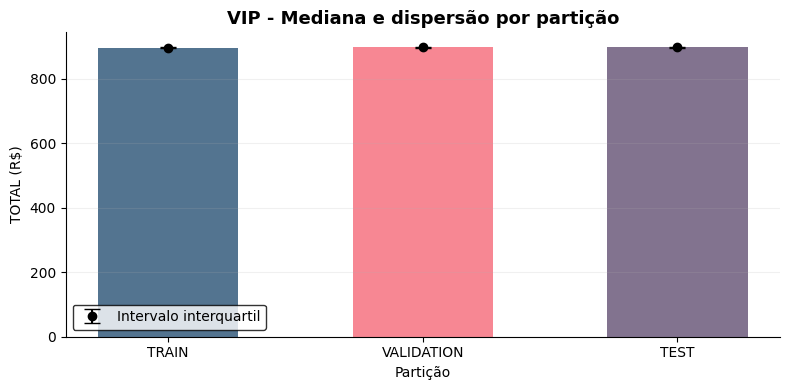

In [ ]:
for item in resultado["resultados_por_grupo"]:
    resumo_plot = item["Resumo"].copy()

    x = np.arange(len(resumo_plot))

    plt.figure(figsize=(8, 4))
    plt.bar(
        x,
        resumo_plot["mediana"],
        color=["#355C7D", "#F67280", "#6C5B7B"],
        alpha=0.85,
        width=0.55,
    )

    plt.errorbar(
        x,
        resumo_plot["mediana"],
        yerr=[resumo_plot["mediana"] - resumo_plot["q1"], resumo_plot["q3"] - resumo_plot["mediana"]],
        fmt="o",
        color="black",
        capsize=6,
        linewidth=1.5,
        label="Intervalo interquartil"
    )

    plt.xticks(x, resumo_plot["Partição"])
    plt.title(f"{item['Grupo']} - Mediana e dispersão por partição", fontsize=13, fontweight="bold")
    plt.xlabel("Partição")
    plt.ylabel("TOTAL (R$)")
    plt.grid(axis="y", alpha=0.18)
    plt.legend(frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()


Foi aplicado o teste de Friedman para verificar se existiam diferenças significativas entre as médias das partições.

Grupo	Estatística	p-valor	Decisão

ESSENTIAL	0,7	0,7047	Não rejeita H0

PRIME	0,4	0,8187	Não rejeita H0

VIP	3,1	0,2122	Não rejeita H0

As médias também ficaram muito próximas entre TRAIN, VALIDATION e TEST. Por exemplo, no ESSENTIAL foram 392,02; 391,87 e 392,43, respectivamente. No PRIME foram 2.236,75; 2.237,77 e 2.236,36

O teste de Friedman não identificou diferenças estatisticamente significativas entre as partições TRAIN, VALIDATION e TEST nos grupos ESSENTIAL, PRIME e VIP. Dessa forma, as médias das partições podem ser consideradas estatisticamente compatíveis, indicando que a divisão dos dados não introduziu diferenças relevantes nas estimativas de TOTAL (R$).

**RESPONDER: SAMPLE 1 e SAMPLE 2 tem as MESMAS MÉDIAS AMOSTRAIS ???**

CONCLUIR / RESPONDER AQUI:
*   ???
*   ???

##Atividade A2 ([Link](https://colab.research.google.com/drive/1w-72bl_qBnGIR8y9zcGYNcpar9b2JdwA?usp=sharing)): Estatística descritiva

###Atividade A2.1: Analisar as variáveis Quantitativas

In [ ]:
def calcular_resumo_quantitativo(serie, nome_variavel, grupo):
    serie = pd.to_numeric(serie, errors="coerce").dropna()

    if len(serie) == 0:
        return None

    media = float(serie.mean())
    mediana = float(serie.median())
    dp = float(serie.std(ddof=1)) if len(serie) > 1 else 0.0
    minimo = float(serie.min())
    maximo = float(serie.max())

    q1 = float(serie.quantile(0.25))
    q3 = float(serie.quantile(0.75))
    iqr = float(q3 - q1)

    p1 = float(serie.quantile(0.01))
    p5 = float(serie.quantile(0.05))
    p95 = float(serie.quantile(0.95))
    p99 = float(serie.quantile(0.99))

    assimetria = float(serie.skew()) if len(serie) > 2 else np.nan
    curtose = float(serie.kurtosis()) if len(serie) > 3 else np.nan
    cv = float(dp / media) if media != 0 else np.nan

    lim_inf = float(q1 - 1.5 * iqr)
    lim_sup = float(q3 + 1.5 * iqr)
    outliers_qtd = int(((serie < lim_inf) | (serie > lim_sup)).sum())
    outliers_perc = float((outliers_qtd / len(serie)) * 100)

    return {
        "grupo": grupo,
        "variavel": nome_variavel,
        "n": int(len(serie)),
        "media": media,
        "mediana": mediana,
        "dp": dp,
        "min": minimo,
        "max": maximo,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "p1": p1,
        "p5": p5,
        "p95": p95,
        "p99": p99,
        "assimetria": assimetria,
        "curtose": curtose,
        "coef_var": cv,
        "lim_inf_iqr": lim_inf,
        "lim_sup_iqr": lim_sup,
        "outliers_qtd": outliers_qtd,
        "outliers_%": outliers_perc,
    }


In [ ]:
def AtividadeA2_1():
    grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]
    variaveis = ["RENDA BRUTO (R$)", "TOTAL (R$)"]

    base_ref = RESULTADOS.get("A1.2", {}).get("table_limpa", table).copy()
    resultados = []

    for grupo in grupos_alvo:
        df_grupo = base_ref[base_ref["TIPO DA CONTA"] == grupo].copy()

        for coluna in variaveis:
            resumo = calcular_resumo_quantitativo(df_grupo[coluna], coluna, grupo)
            if resumo is not None:
                resultados.append(resumo)

    tabela_resumo = pd.DataFrame(resultados)

    RESULTADOS["A2.1"] = {
        "n_registros": int(len(base_ref)),
        "qtd_variaveis": int(len(variaveis)),
        "grupos": grupos_alvo,
        "tabela_resumo": tabela_resumo,
    }

    print("Análise das variáveis quantitativas por grupos concluída.")
    print(f"Grupos analisados: {len(grupos_alvo)}")
    print(f"Variáveis analisadas por grupo: {len(variaveis)}")


In [ ]:
AtividadeA2_1()
resultado = RESULTADOS["A2.1"]
tabela_quant = resultado["tabela_resumo"].copy()


Análise das variáveis quantitativas por grupos concluída.
Grupos analisados: 3
Variáveis analisadas por grupo: 2


In [ ]:
colunas_visuais = [
    "grupo", "variavel", "n", "media", "mediana", "dp", "q1", "q3",
    "iqr", "assimetria", "curtose", "coef_var", "outliers_%"
]

tabela_exibicao = tabela_quant[colunas_visuais].copy()
tabela_exibicao[[
    "media", "mediana", "dp", "q1", "q3", "iqr",
    "assimetria", "curtose", "coef_var", "outliers_%"
]] = tabela_exibicao[[
    "media", "mediana", "dp", "q1", "q3", "iqr",
    "assimetria", "curtose", "coef_var", "outliers_%"
]].round(4)

display(tabela_exibicao)


,grupo,variavel,n,media,mediana,dp,q1,q3,iqr,assimetria,curtose,coef_var,outliers_%
0,ESSENTIAL,RENDA BRUTO (R$),700015,3546.0144,3254.860,1861.5121,3196.9900,3314.42,117.4300,6.9019,49.2612,0.5250,3.9461
1,ESSENTIAL,TOTAL (R$),700015,392.2672,365.060,269.0959,236.0500,491.34,255.2900,5.2929,42.5895,0.6860,2.1155
2,PRIME,RENDA BRUTO (R$),175002,20295.2439,21226.480,4731.9207,19101.0200,23115.09,4014.0700,-1.7540,3.5498,0.2332,8.3708
3,PRIME,TOTAL (R$),175002,2237.5692,2182.385,1040.9496,1365.9625,3063.90,1697.9375,0.1728,-0.8830,0.4652,0.0000
4,VIP,RENDA BRUTO (R$),244983,8137.5592,7768.080,2140.8817,7558.0900,7987.58,429.4900,3.7096,16.7555,0.2631,9.5227
5,VIP,TOTAL (R$),244983,896.9160,866.400,432.2032,560.8900,1171.64,610.7500,1.4228,5.0710,0.4819,1.8316


In [ ]:
for grupo in ["ESSENTIAL", "PRIME", "VIP"]:
    print(f"\nGrupo: {grupo}")

    df_grupo = tabela_quant[tabela_quant["grupo"] == grupo].copy()

    maior_cv = df_grupo.sort_values("coef_var", ascending=False).head(3)
    maior_outliers = df_grupo.sort_values("outliers_%", ascending=False).head(3)
    maior_assimetria = df_grupo.reindex(
        df_grupo["assimetria"].abs().sort_values(ascending=False).index
    ).head(3)

    display(maior_cv[["variavel", "coef_var"]].round(4))
    display(maior_outliers[["variavel", "outliers_%"]].round(4))
    display(maior_assimetria[["variavel", "assimetria"]].round(4))



Grupo: ESSENTIAL


,variavel,coef_var
1,TOTAL (R$),0.686
0,RENDA BRUTO (R$),0.525


,variavel,outliers_%
0,RENDA BRUTO (R$),3.9461
1,TOTAL (R$),2.1155


,variavel,assimetria
0,RENDA BRUTO (R$),6.9019
1,TOTAL (R$),5.2929



Grupo: PRIME


...

,variavel,assimetria
2,RENDA BRUTO (R$),-1.7540
3,TOTAL (R$),0.1728



Grupo: VIP


,variavel,coef_var
5,TOTAL (R$),0.4819
4,RENDA BRUTO (R$),0.2631


,variavel,outliers_%
4,RENDA BRUTO (R$),9.5227
5,TOTAL (R$),1.8316


,variavel,assimetria
4,RENDA BRUTO (R$),3.7096
5,TOTAL (R$),1.4228


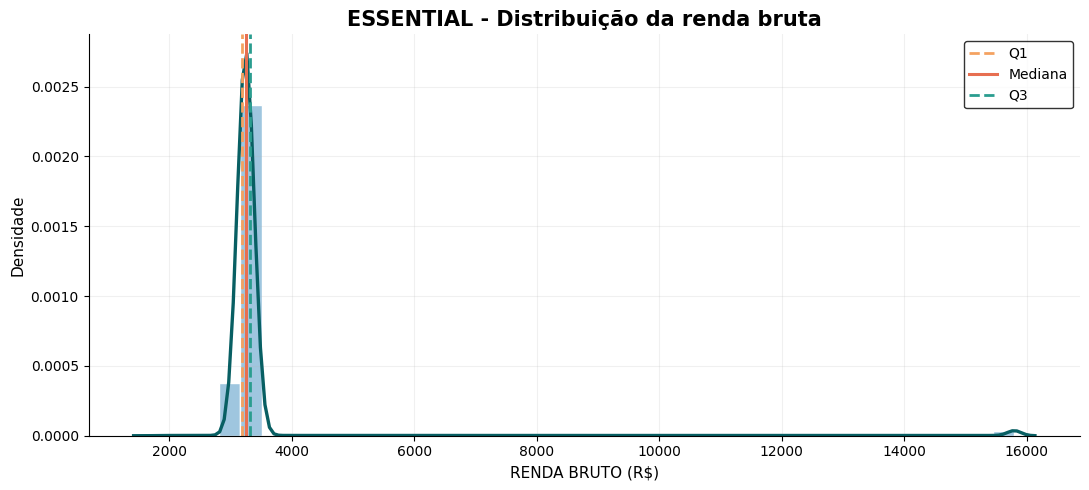

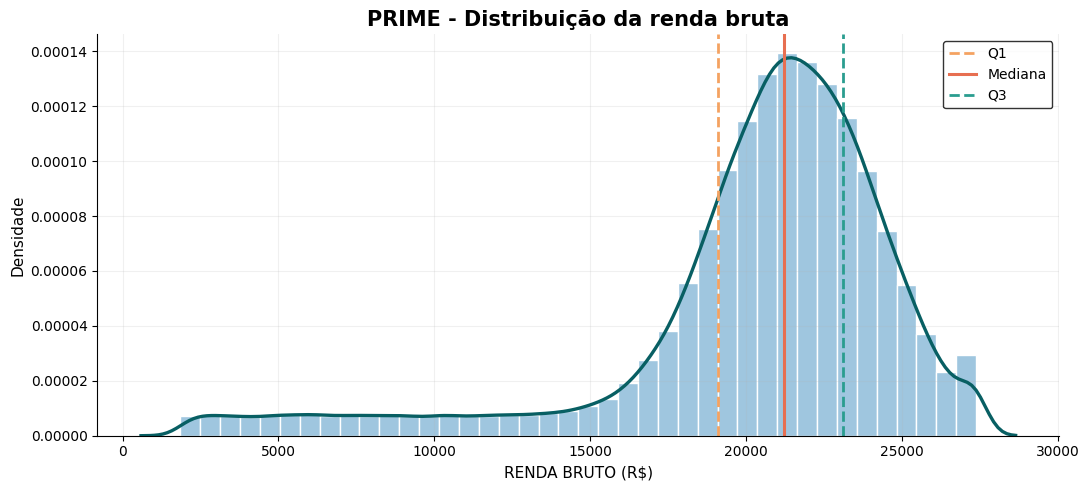

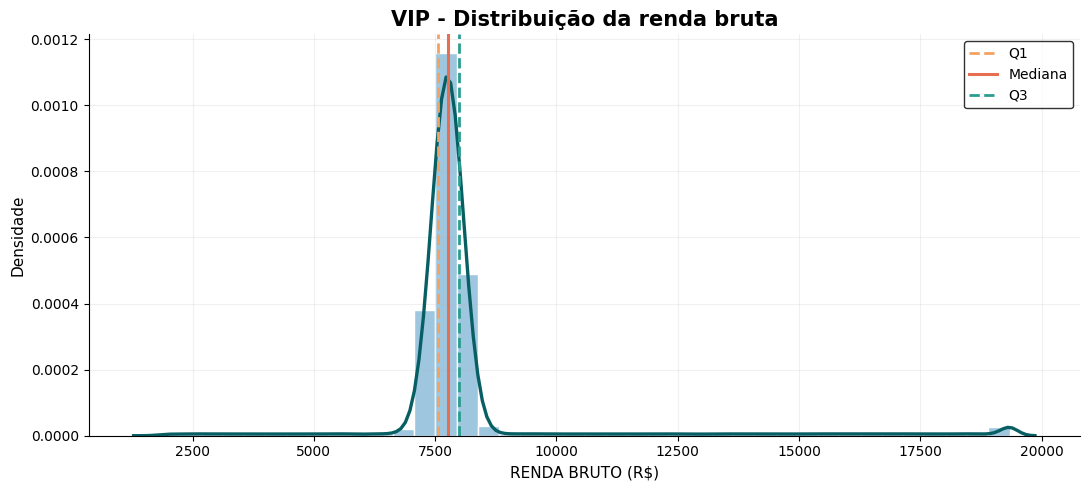

In [ ]:
for grupo in ["ESSENTIAL", "PRIME", "VIP"]:
    serie = RESULTADOS["A1.2"]["table_limpa"].loc[
        RESULTADOS["A1.2"]["table_limpa"]["TIPO DA CONTA"] == grupo,
        "RENDA BRUTO (R$)"
    ].dropna()

    cap = serie.quantile(0.99)
    serie_plot = serie.clip(upper=cap)

    q1 = serie.quantile(0.25)
    mediana = serie.median()
    q3 = serie.quantile(0.75)

    plt.figure(figsize=(11, 5))

    sns.histplot(
        serie_plot,
        bins=40,
        stat="density",
        color="#7FB3D5",
        edgecolor="white",
        alpha=0.75,
    )

    sns.kdeplot(
        serie_plot,
        color="#085F63",
        linewidth=2.4,
    )

    plt.axvline(q1, color="#F4A261", linestyle="--", linewidth=2, label="Q1")
    plt.axvline(mediana, color="#E76F51", linestyle="-", linewidth=2.2, label="Mediana")
    plt.axvline(q3, color="#2A9D8F", linestyle="--", linewidth=2, label="Q3")

    plt.title(f"{grupo} - Distribuição da renda bruta", fontsize=15, fontweight="bold")
    plt.xlabel("RENDA BRUTO (R$)", fontsize=11)
    plt.ylabel("Densidade", fontsize=11)
    plt.grid(alpha=0.18)
    plt.legend(frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()


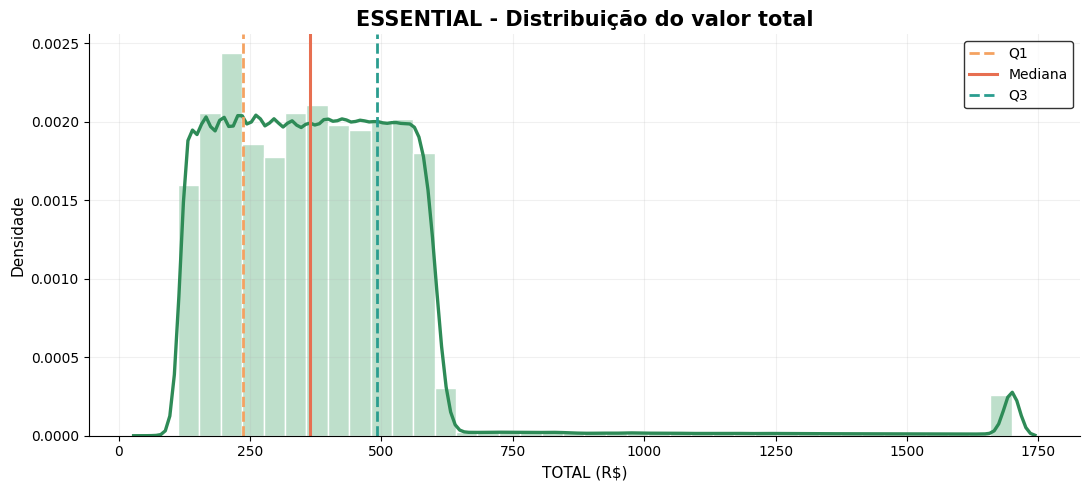

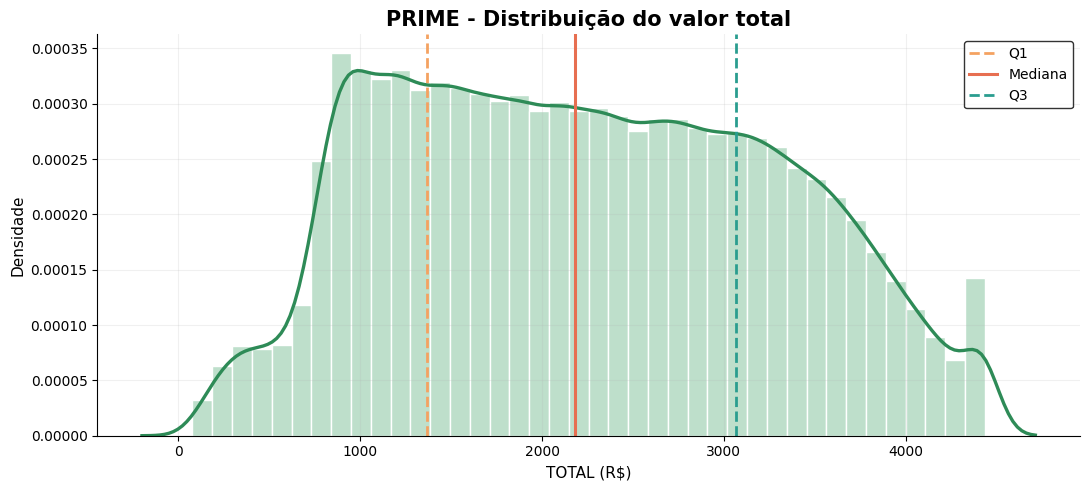

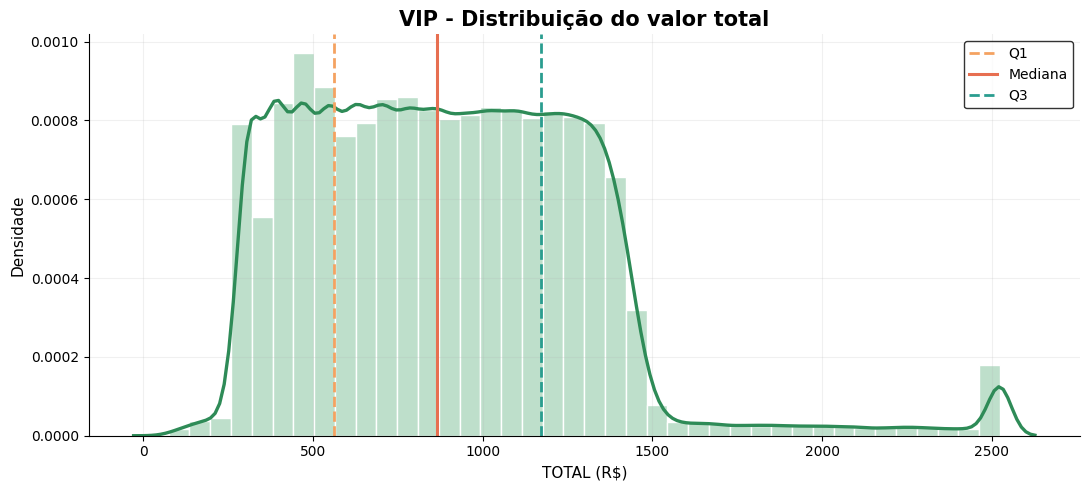

In [ ]:
for grupo in ["ESSENTIAL", "PRIME", "VIP"]:
    serie = RESULTADOS["A1.2"]["table_limpa"].loc[
        RESULTADOS["A1.2"]["table_limpa"]["TIPO DA CONTA"] == grupo,
        "TOTAL (R$)"
    ].dropna()

    cap = serie.quantile(0.99)
    serie_plot = serie.clip(upper=cap)

    q1 = serie.quantile(0.25)
    mediana = serie.median()
    q3 = serie.quantile(0.75)

    plt.figure(figsize=(11, 5))

    sns.histplot(
        serie_plot,
        bins=40,
        stat="density",
        color="#A8D5BA",
        edgecolor="white",
        alpha=0.75,
    )

    sns.kdeplot(
        serie_plot,
        color="#2E8B57",
        linewidth=2.4,
    )

    plt.axvline(q1, color="#F4A261", linestyle="--", linewidth=2, label="Q1")
    plt.axvline(mediana, color="#E76F51", linestyle="-", linewidth=2.2, label="Mediana")
    plt.axvline(q3, color="#2A9D8F", linestyle="--", linewidth=2, label="Q3")

    plt.title(f"{grupo} - Distribuição do valor total", fontsize=15, fontweight="bold")
    plt.xlabel("TOTAL (R$)", fontsize=11)
    plt.ylabel("Densidade", fontsize=11)
    plt.grid(alpha=0.18)
    plt.legend(frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()


In [ ]:
percentis_quant = tabela_quant[[
    "grupo", "variavel", "p1", "p5", "q1", "mediana", "q3", "p95", "p99"
]].copy()

display(percentis_quant.round(2))


,grupo,variavel,p1,p5,q1,mediana,q3,p95,p99
0,ESSENTIAL,RENDA BRUTO (R$),3051.70,3113.77,3196.99,3254.86,3314.42,3426.60,15796.67
1,ESSENTIAL,TOTAL (R$),128.63,134.54,236.05,365.06,491.34,592.98,1699.51
2,PRIME,RENDA BRUTO (R$),3196.59,8667.88,19101.02,21226.48,23115.09,25619.86,27376.01
3,PRIME,TOTAL (R$),289.65,733.11,1365.96,2182.39,3063.90,3961.52,4434.84
4,VIP,RENDA BRUTO (R$),3718.36,7197.80,7558.09,7768.08,7987.58,11746.07,19339.22
5,VIP,TOTAL (R$),292.29,317.66,560.89,866.40,1171.64,1436.70,2523.41


Foram analisadas RENDA BRUTO (R$) e TOTAL (R$) nos três grupos.

ESSENTIAL

Renda média: R$ 3.546,01
Mediana: R$ 3.254,86
CV: 52,50%
Assimetria: 6,90
Outliers: 3,95%
TOTAL médio: R$ 392,27
Mediana: R$ 365,06
CV: 68,60%
Assimetria: 5,29
Outliers: 2,12%

PRIME

Renda média: R$ 20.295,24
Mediana: R$ 21.226,48
CV: 23,32%
Assimetria: -1,75
Outliers: 8,37%
TOTAL médio: R$ 2.237,57
Mediana: R$ 2.182,39
CV: 46,52%
Assimetria: 0,17
Outliers: 0%

VIP

Renda média: R$ 8.137,56
Mediana: R$ 7.768,08
CV: 26,31%
Assimetria: 3,71
Outliers: 9,52%
TOTAL médio: R$ 896,92
Mediana: R$ 866,40
CV: 48,19%
Assimetria: 1,42
Outliers: 1,83%.

A análise descritiva evidencia diferenças importantes entre os segmentos da UVVine. O grupo PRIME apresenta o maior valor médio de TOTAL (R$ 2.237,57), enquanto o grupo ESSENTIAL apresenta o menor valor médio (R$ 392,27). O grupo VIP apresenta comportamento intermediário, com média de R$ 896,92.

Observa-se também elevada variabilidade na variável TOTAL, especialmente no grupo ESSENTIAL, cujo coeficiente de variação é de 68,60%. Além disso, a diferença entre média e mediana e os elevados níveis de assimetria indicam que a distribuição financeira possui valores extremos e não é simétrica. Esses resultados são coerentes com a rejeição da normalidade observada anteriormente.

###Atividade A2.2: Analisar as variáveis Qualitativas

In [ ]:
def resumir_variavel_qualitativa(serie, n_total, top_n=10):
    serie = serie.astype("string").str.strip()

    missing_mask = serie.isna() | (serie == "") | (serie.str.lower() == "nan")
    missing_qtd = int(missing_mask.sum())
    missing_pct = float((missing_qtd / n_total) * 100) if n_total > 0 else 0.0

    serie_valid = serie[~missing_mask]
    n_validos = int(len(serie_valid))

    if n_validos == 0:
        return {
            "resumo": {
                "n_total": int(n_total),
                "n_validos": 0,
                "missing_qtd": missing_qtd,
                "missing_%": missing_pct,
                "categorias_unicas": 0,
                "moda": None,
                "moda_qtd": 0,
                "moda_%_validos": 0.0,
                "top1_%_validos": 0.0,
                "top3_%_validos": 0.0,
                "top5_%_validos": 0.0,
                "diversidade": "sem dados",
            },
            "top_table": pd.DataFrame(columns=["categoria", "freq_abs", "freq_%"])
        }

    freq_abs = serie_valid.value_counts()
    freq_rel = (freq_abs / n_validos) * 100

    moda = str(freq_abs.index[0])
    moda_qtd = int(freq_abs.iloc[0])
    moda_pct = float(freq_rel.iloc[0])

    top1 = float(freq_rel.iloc[:1].sum())
    top3 = float(freq_rel.iloc[:3].sum())
    top5 = float(freq_rel.iloc[:5].sum())

    if top1 >= 70:
        diversidade = "alta concentração"
    elif top1 >= 40:
        diversidade = "concentração moderada"
    else:
        diversidade = "distribuição mais equilibrada"

    top_table = pd.DataFrame({
        "categoria": freq_abs.index[:top_n].astype(str),
        "freq_abs": freq_abs.values[:top_n],
        "freq_%": freq_rel.values[:top_n],
    })

    return {
        "resumo": {
            "n_total": int(n_total),
            "n_validos": n_validos,
            "missing_qtd": missing_qtd,
            "missing_%": missing_pct,
            "categorias_unicas": int(serie_valid.nunique()),
            "moda": moda,
            "moda_qtd": moda_qtd,
            "moda_%_validos": moda_pct,
            "top1_%_validos": top1,
            "top3_%_validos": top3,
            "top5_%_validos": top5,
            "diversidade": diversidade,
        },
        "top_table": top_table
    }


In [ ]:
def AtividadeA2_2():
    grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]
    base_ref = RESULTADOS.get("A1.2", {}).get("table_limpa", table).copy()

    resultados = {}
    linhas_resumo = []

    for grupo in grupos_alvo:
        df_grupo = base_ref[base_ref["TIPO DA CONTA"] == grupo].copy()
        n_total = int(len(df_grupo))

        cat_df = df_grupo.select_dtypes(include=["object", "category", "bool"]).copy()

        heuristicas = []
        for coluna in df_grupo.columns:
            if coluna in cat_df.columns:
                continue
            if coluna == "TIPO DA CONTA":
                continue

            if pd.api.types.is_integer_dtype(df_grupo[coluna]) or pd.api.types.is_float_dtype(df_grupo[coluna]):
                serie_tmp = df_grupo[coluna].dropna()
                if len(serie_tmp) == 0:
                    continue

                nunique = int(serie_tmp.nunique())
                if 1 < nunique <= 12:
                    heuristicas.append(coluna)

        for coluna in heuristicas:
            cat_df[coluna] = df_grupo[coluna].astype("Int64").astype("string")

        if "TIPO DA CONTA" in cat_df.columns:
            cat_df = cat_df.drop(columns=["TIPO DA CONTA"])

        resultados[grupo] = {
            "variaveis": list(cat_df.columns),
            "variaveis_heuristicas": heuristicas,
            "resumo_por_variavel": {},
        }

        for coluna in cat_df.columns:
            saida = resumir_variavel_qualitativa(cat_df[coluna], n_total=n_total, top_n=10)

            resultados[grupo]["resumo_por_variavel"][coluna] = {
                "resumo": saida["resumo"],
                "top_categorias": saida["top_table"],
            }

            linhas_resumo.append({
                "grupo": grupo,
                "variável": coluna,
                **saida["resumo"],
            })

    tabela_resumo = pd.DataFrame(linhas_resumo)

    RESULTADOS["A2.2"] = {
        "grupos": grupos_alvo,
        "resumo_por_grupo": resultados,
        "tabela_resumo": tabela_resumo,
    }

    print("Análise das variáveis qualitativas por grupos concluída.")
    print(f"Grupos analisados: {len(grupos_alvo)}")


In [ ]:
AtividadeA2_2()

resultado = RESULTADOS["A2.2"]
tabela_qualitativas = resultado["tabela_resumo"].copy()


Análise das variáveis qualitativas por grupos concluída.
Grupos analisados: 3


In [ ]:
colunas_visuais = [
    "grupo",
    "variável",
    "missing_%",
    "categorias_unicas",
    "moda",
    "moda_%_validos",
    "top1_%_validos",
    "top3_%_validos",
    "top5_%_validos",
    "diversidade",
]

tabela_exibicao = tabela_qualitativas[colunas_visuais].copy()
tabela_exibicao[[
    "missing_%",
    "moda_%_validos",
    "top1_%_validos",
    "top3_%_validos",
    "top5_%_validos"
]] = tabela_exibicao[[
    "missing_%",
    "moda_%_validos",
    "top1_%_validos",
    "top3_%_validos",
    "top5_%_validos"
]].round(2)

display(tabela_exibicao)


,grupo,variável,missing_%,categorias_unicas,moda,moda_%_validos,top1_%_validos,top3_%_validos,top5_%_validos,diversidade
0,ESSENTIAL,REGIÃO,0.0,5,SUDESTE,67.04,67.04,92.02,100.00,concentração moderada
1,ESSENTIAL,SEXO,0.0,2,MASCULINO,87.07,87.07,100.00,100.00,alta concentração
2,ESSENTIAL,ESTADO CIVIL,0.0,3,CASADO,55.00,55.00,100.00,100.00,concentração moderada
3,ESSENTIAL,OPINIÃO DO CLIENTE,0.0,25,Entrega foi boa e rápida na UVVine,15.45,15.45,46.30,76.96,distribuição mais equilibrada
4,ESSENTIAL,DEPENDENTES,0.0,5,1,53.07,53.07,90.01,100.00,concentração moderada
5,PRIME,REGIÃO,0.0,5,SUDESTE,66.70,66.70,91.89,100.00,concentração moderada
6,PRIME,SEXO,0.0,2,MASCULINO,87.07,87.07,100.00,100.00,alta concentração
7,PRIME,ESTADO CIVIL,0.0,3,CASADO,54.80,54.80,100.00,100.00,concentração moderada
8,PRIME,OPINIÃO DO CLIENTE,0.0,25,Gostei do atendimento prestado pela UVVine,15.59,15.59,46.44,77.21,distribuição mais equilibrada
9,PRIME,DEPENDENTES,0.0,5,1,52.95,52.95,89.93,100.00,concentração moderada


In [ ]:
for grupo in resultado["grupos"]:
    print(f"\nGrupo: {grupo}")

    resumo_grupo = tabela_qualitativas[tabela_qualitativas["grupo"] == grupo].copy()
    display(
        resumo_grupo[[
            "variável",
            "missing_%",
            "categorias_unicas",
            "moda",
            "moda_%_validos",
            "top1_%_validos",
            "top3_%_validos",
            "top5_%_validos",
            "diversidade",
        ]].round(2)
    )



Grupo: ESSENTIAL


,variável,missing_%,categorias_unicas,moda,moda_%_validos,top1_%_validos,top3_%_validos,top5_%_validos,diversidade
0,REGIÃO,0.0,5,SUDESTE,67.04,67.04,92.02,100.00,concentração moderada
1,SEXO,0.0,2,MASCULINO,87.07,87.07,100.00,100.00,alta concentração
2,ESTADO CIVIL,0.0,3,CASADO,55.00,55.00,100.00,100.00,concentração moderada
3,OPINIÃO DO CLIENTE,0.0,25,Entrega foi boa e rápida na UVVine,15.45,15.45,46.30,76.96,distribuição mais equilibrada
4,DEPENDENTES,0.0,5,1,53.07,53.07,90.01,100.00,concentração moderada



Grupo: PRIME


,variável,missing_%,categorias_unicas,moda,moda_%_validos,top1_%_validos,top3_%_validos,top5_%_validos,diversidade
5,REGIÃO,0.0,5,SUDESTE,66.70,66.70,91.89,100.00,concentração moderada
6,SEXO,0.0,2,MASCULINO,87.07,87.07,100.00,100.00,alta concentração
7,ESTADO CIVIL,0.0,3,CASADO,54.80,54.80,100.00,100.00,concentração moderada
8,OPINIÃO DO CLIENTE,0.0,25,Gostei do atendimento prestado pela UVVine,15.59,15.59,46.44,77.21,distribuição mais equilibrada
9,DEPENDENTES,0.0,5,1,52.95,52.95,89.93,100.00,concentração moderada



Grupo: VIP


,variável,missing_%,categorias_unicas,moda,moda_%_validos,top1_%_validos,top3_%_validos,top5_%_validos,diversidade
10,REGIÃO,0.0,5,SUDESTE,67.13,67.13,92.08,100.00,concentração moderada
11,SEXO,0.0,2,MASCULINO,86.93,86.93,100.00,100.00,alta concentração
12,ESTADO CIVIL,0.0,3,CASADO,54.92,54.92,100.00,100.00,concentração moderada
13,OPINIÃO DO CLIENTE,0.0,25,"Serviço eficiente, recomendo o clube: UVVine",15.49,15.49,46.30,76.95,distribuição mais equilibrada
14,DEPENDENTES,0.0,5,1,53.16,53.16,90.03,100.00,concentração moderada


In [ ]:
def plot_top_categorias_grupo(resultado_a22, grupo, variavel, top_n=8, figsize=(10, 5)):
    top_table = resultado_a22["resumo_por_grupo"][grupo]["resumo_por_variavel"][variavel]["top_categorias"].copy().head(top_n)

    if variavel == "OPINIÃO DO CLIENTE":
        top_table["categoria_plot"] = top_table["categoria"].str.slice(0, 42) + "..."
        y = top_table["categoria_plot"]
        palette_name = "crest"
    else:
        y = top_table["categoria"].astype(str)
        palette_name = "Blues"

    plt.figure(figsize=figsize)

    bars = plt.barh(
        y,
        top_table["freq_%"],
        color=sns.color_palette(palette_name, len(top_table)),
        edgecolor="white",
        linewidth=0.8,
    )

    for bar, valor in zip(bars, top_table["freq_%"]):
        plt.text(
            bar.get_width() + 0.25,
            bar.get_y() + bar.get_height() / 2,
            f"{valor:.2f}%",
            va="center",
            fontsize=10,
        )

    plt.title(f"{grupo} - Distribuição das categorias de {variavel}", fontsize=14, fontweight="bold")
    plt.xlabel("Percentual (%)", fontsize=11)
    plt.ylabel("Categoria", fontsize=11)
    plt.grid(axis="x", alpha=0.18)
    plt.tight_layout()
    sns.despine()
    plt.show()


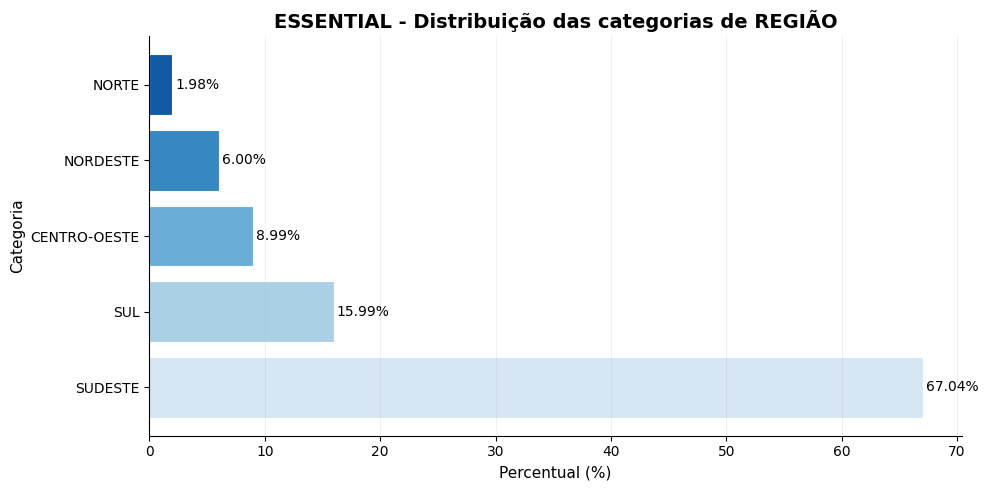

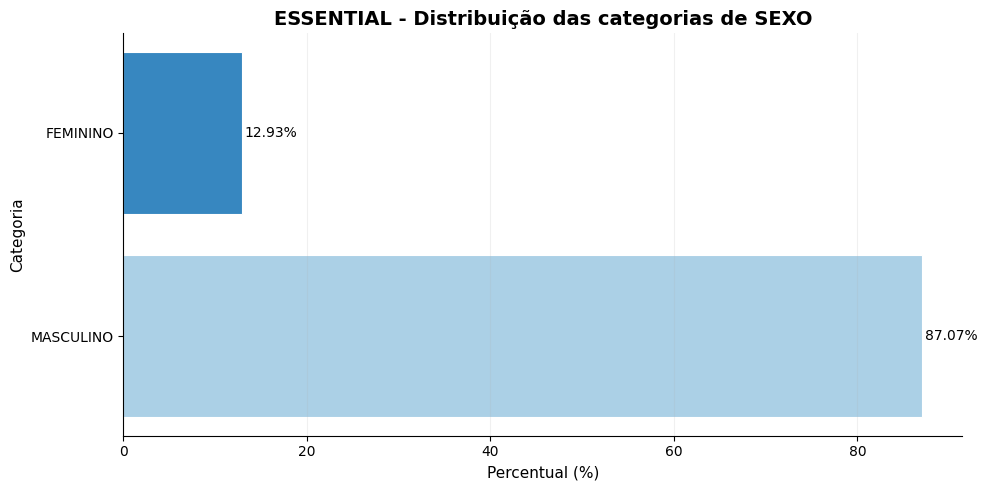

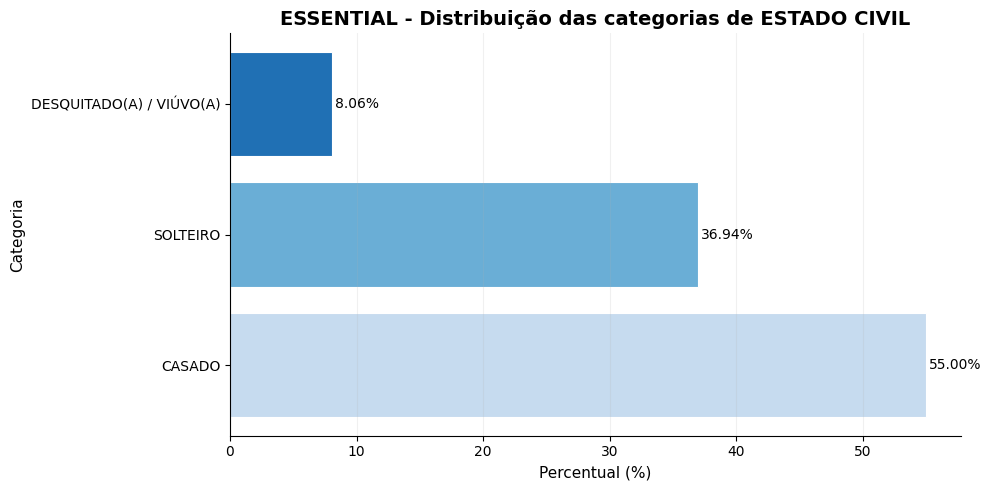

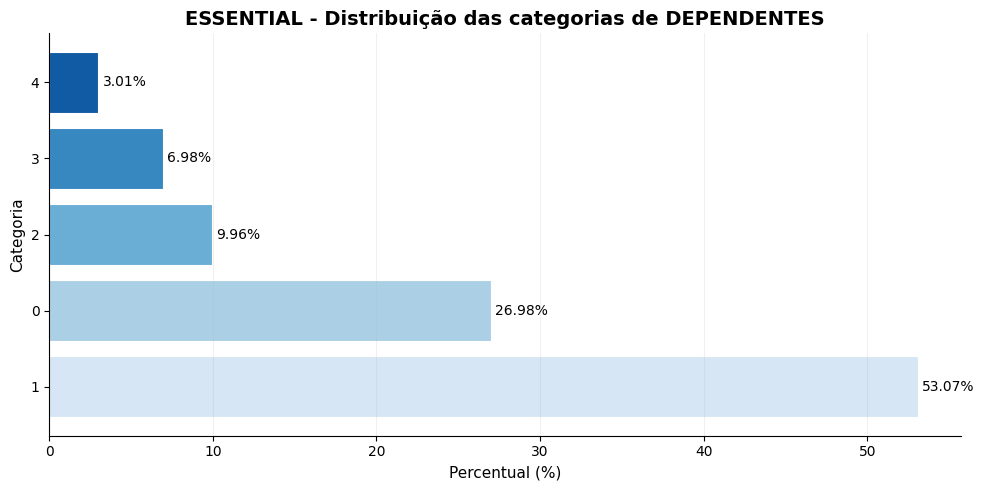

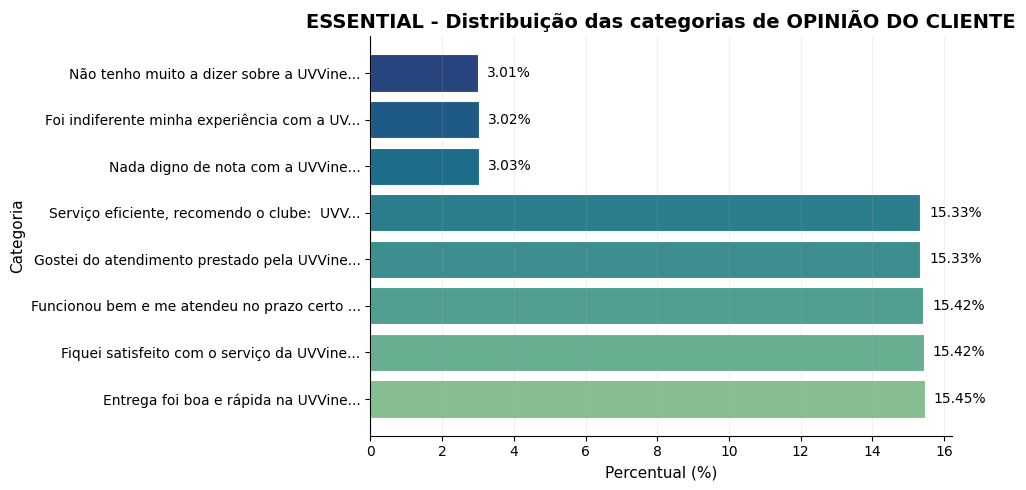

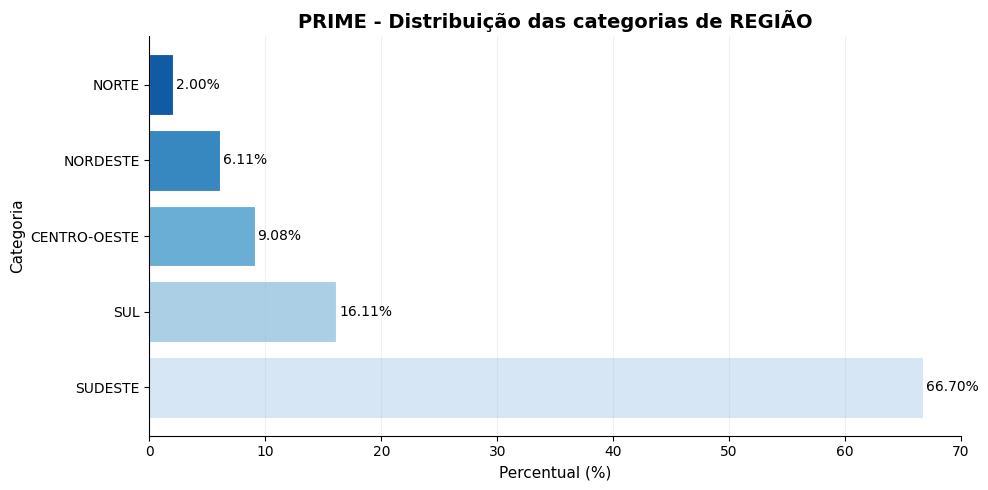

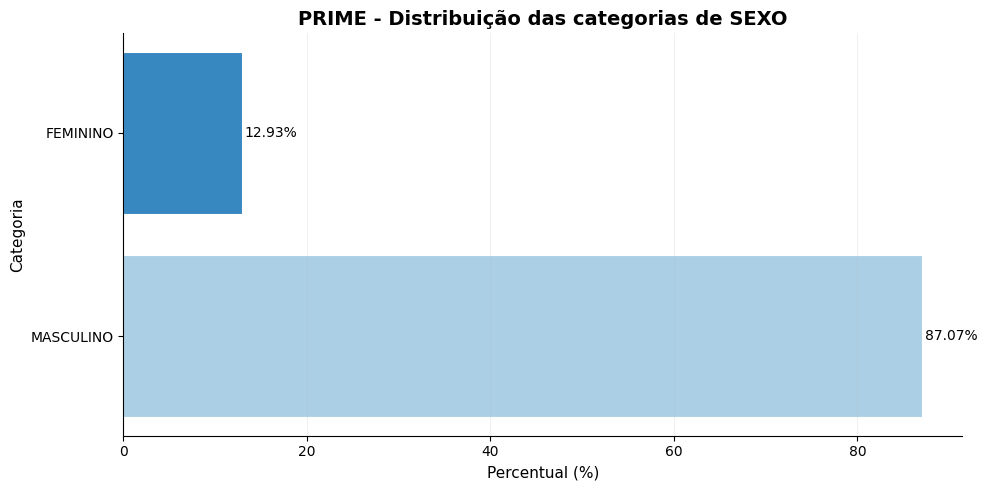

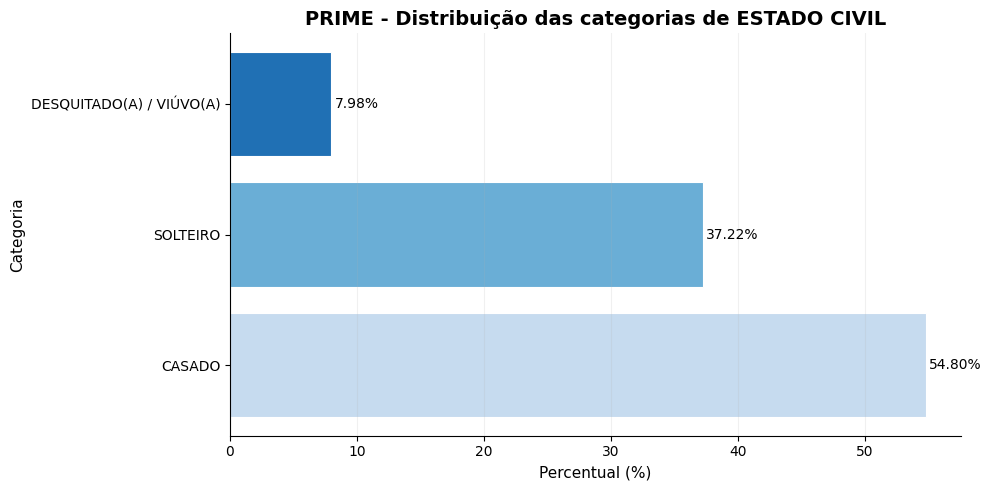

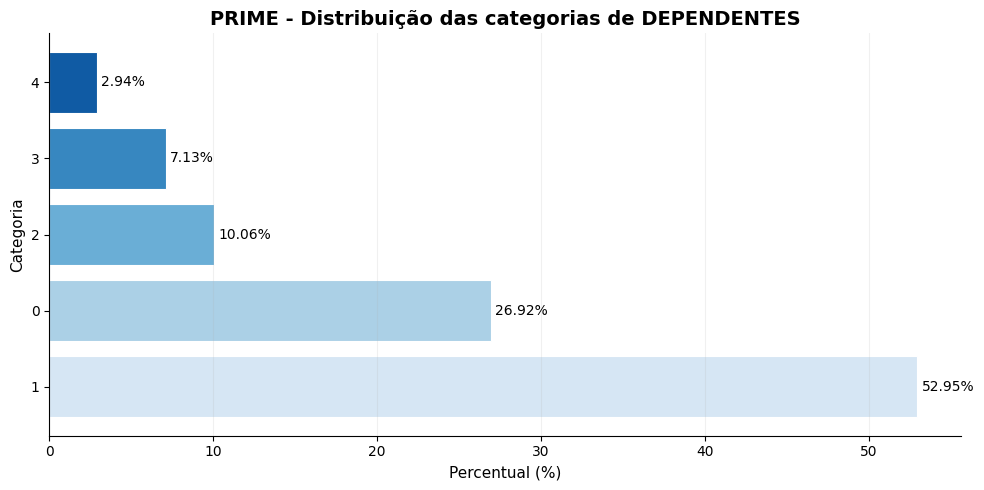

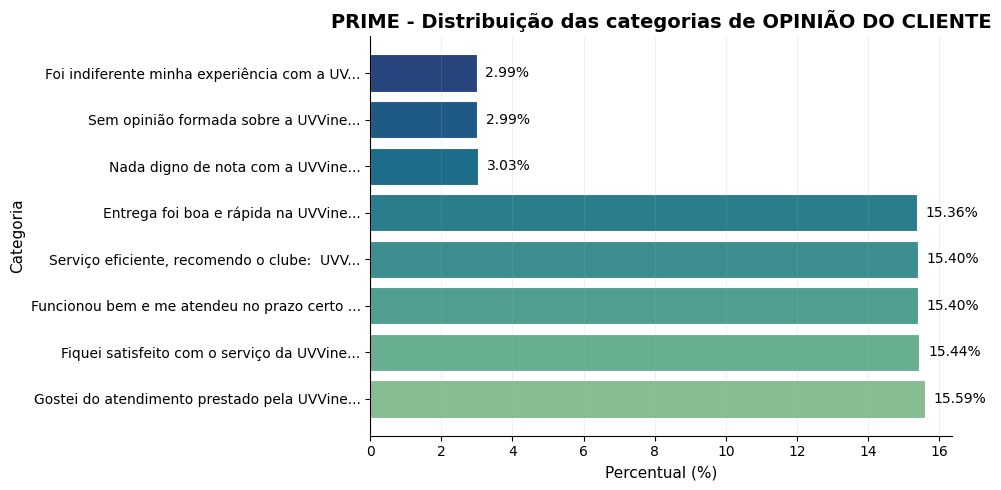

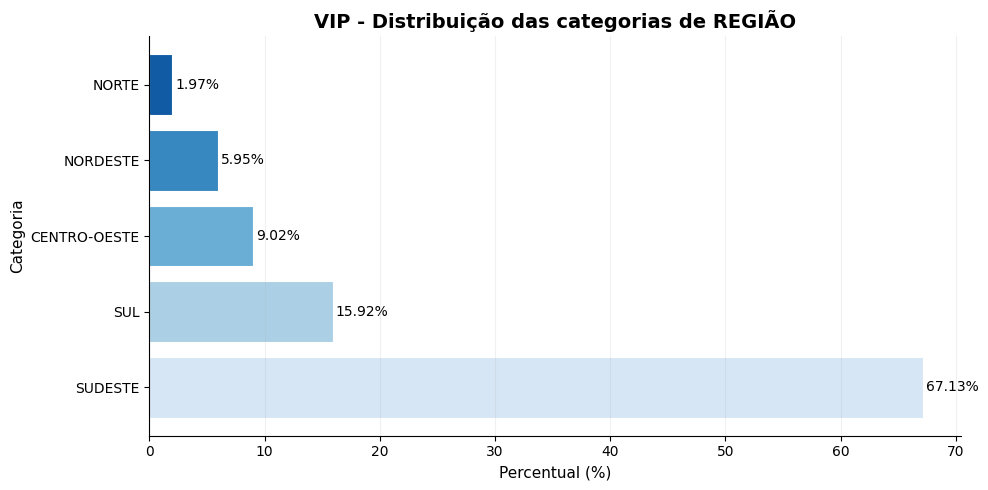

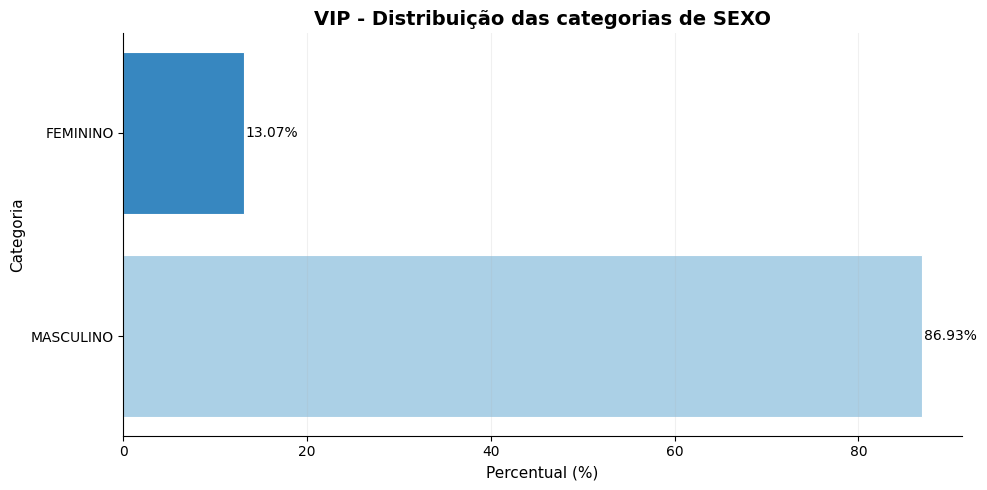

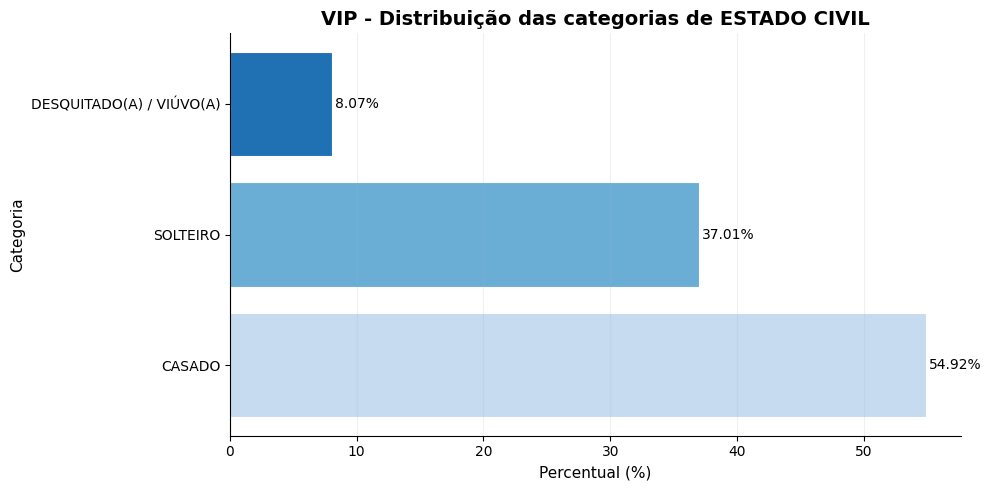

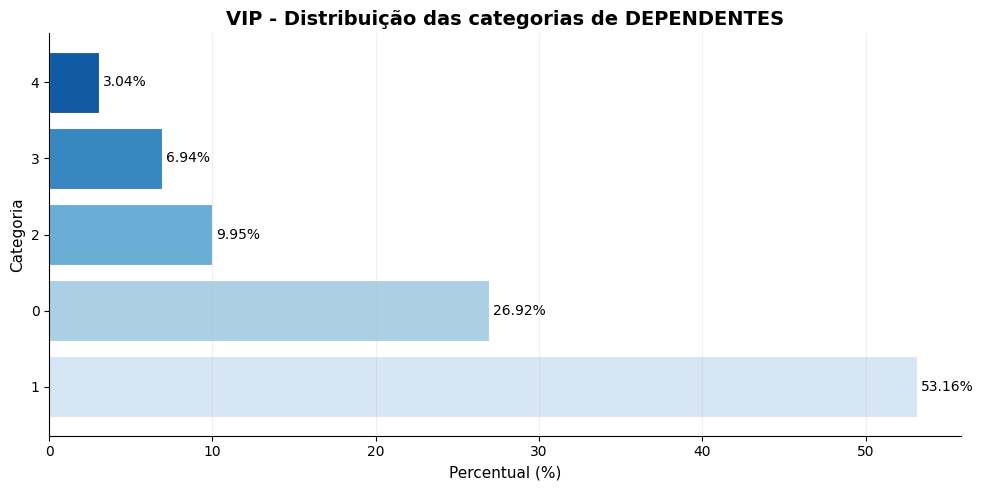

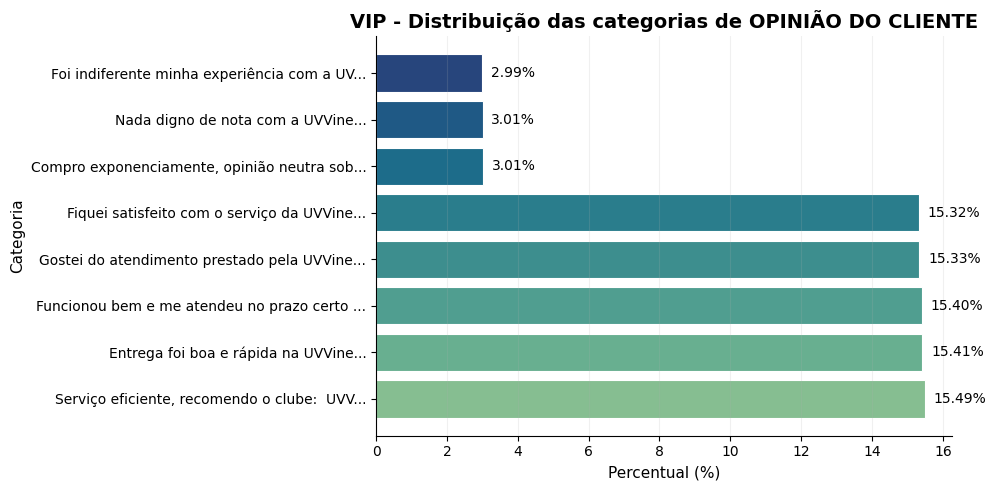

In [ ]:
variaveis_plot = ["REGIÃO", "SEXO", "ESTADO CIVIL", "DEPENDENTES", "OPINIÃO DO CLIENTE"]

for grupo in resultado["grupos"]:
    for variavel in variaveis_plot:
        if variavel in resultado["resumo_por_grupo"][grupo]["resumo_por_variavel"]:
            plot_top_categorias_grupo(resultado, grupo, variavel, top_n=8, figsize=(10, 5))



Foram analisadas:

REGIÃO

SEXO

ESTADO CIVIL

OPINIÃO DO CLIENTE

DEPENDENTES


Não foram encontrados valores ausentes nessas variáveis.


Os principais resultados foram:


---

**Região**

O Sudeste é a região predominante:

ESSENTIAL: 67,04%

PRIME: 66,70%

VIP: 67,13%

---

**Sexo**

O masculino é predominante:

ESSENTIAL: 87,07%

PRIME: 87,07%

VIP: 86,93%

---

**Estado** **civil**


A categoria predominante é CASADO:

ESSENTIAL: 55,00%

PRIME: 54,80%

VIP: 54,92%



---


**Dependentes**

A categoria 1 dependente é a mais frequente:

ESSENTIAL: 53,07%

PRIME: 52,95%

VIP: 53,16%

Opinião do cliente

A variável possui 25 categorias e apresenta distribuição mais equilibrada, sem uma única opinião dominando a base. As categorias mais frequentes representam aproximadamente 15% cada

A análise das variáveis qualitativas mostra um perfil relativamente consistente entre os três segmentos. Em todos eles, há predominância de clientes da região Sudeste, do sexo masculino, casados e com 1 dependente. As proporções são bastante semelhantes entre ESSENTIAL, PRIME e VIP, indicando que essas características demográficas apresentam pouca variação entre os segmentos.

Já a variável OPINIÃO DO CLIENTE apresenta maior diversidade, com 25 categorias e distribuição mais equilibrada. Esse comportamento demonstra que as opiniões dos clientes são mais heterogêneas e podem ser utilizadas posteriormente para análises mais aprofundadas de satisfação e comportamento.

##Atividade A3: Resultado da Pesquisa de Satisfação

Fazer o resultado da Pesquisa de satisfação do cliente em porcentagem (%):
* Geral
* Por Sexo

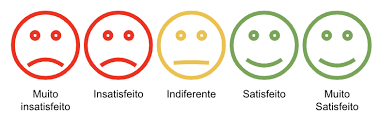

###Atividade A3.1: Discretizar a Variável Qualitativa (OPINIÃO DO CLIENTE)

In [ ]:
def classificar_satisfacao_5_niveis(texto):
    if pd.isna(texto):
        return np.nan

    t = str(texto).strip().upper()

    muito_satisfeito = [
        "EXCELENTE", "ÓTIMO", "OTIMO", "PERFEITO", "IMPECÁVEL", "IMPECAVEL",
        "SUPEROU", "ADOREI", "AMEI", "MUITO SATISFEITO", "MUITO BOA",
        "SERVIÇO EFICIENTE", "RECOMENDO", "ENTREGA FOI BOA E RÁPIDA",
        "ENTREGA FOI BOA E RAPIDA", "FUNCIONOU BEM", "FIQUEI SATISFEITO"
    ]

    satisfeito = [
        "GOSTEI", "SATISFEITO", "BOM", "BOA", "ATENDEU", "PRAZO CERTO",
        "ATENDIMENTO PRESTADO", "SERVIÇO BOM", "SERVICO BOM"
    ]

    indiferente = [
        "INDIFERENTE", "NEUTRO", "NEUTRA", "RAZOÁVEL", "RAZOAVEL",
        "NORMAL", "COMUM", "NADA DIGNO DE NOTA", "NÃO TENHO MUITO A DIZER",
        "NAO TENHO MUITO A DIZER"
    ]

    insatisfeito = [
        "RUIM", "INSATISFEITO", "DEMORADO", "NÃO GOSTEI", "NAO GOSTEI",
        "PROBLEMA", "DEIXOU A DESEJAR", "PODERIA SER MELHOR"
    ]

    muito_insatisfeito = [
        "PÉSSIMO", "PESSIMO", "HORRÍVEL", "HORRIVEL", "MUITO INSATISFEITO",
        "NUNCA MAIS", "TERRÍVEL", "TERRIVEL"
    ]

    if any(chave in t for chave in muito_insatisfeito):
        return "Muito insatisfeito"
    if any(chave in t for chave in insatisfeito):
        return "Insatisfeito"
    if any(chave in t for chave in indiferente):
        return "Indiferente"
    if any(chave in t for chave in muito_satisfeito):
        return "Muito satisfeito"
    if any(chave in t for chave in satisfeito):
        return "Satisfeito"

    return "Indiferente"


def bootstrap_proporcao_categoria(categorias, categoria_alvo, B=3000, seed=42):
    rng = np.random.default_rng(seed)
    valores = (categorias == categoria_alvo).astype(float).values
    n = len(valores)

    boot = np.empty(B, dtype=float)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        boot[b] = valores[idx].mean() * 100

    ic_inf = float(np.percentile(boot, 2.5))
    ic_sup = float(np.percentile(boot, 97.5))

    return boot, ic_inf, ic_sup


In [ ]:
def AtividadeA3_1(B=3000, seed=42):
    grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]
    ordem_categorias = [
        "Muito insatisfeito",
        "Insatisfeito",
        "Indiferente",
        "Satisfeito",
        "Muito satisfeito"
    ]

    base_ref = RESULTADOS.get("A1.2", {}).get("table_limpa", table).copy()
    resultados_geral = []
    resultados_sexo = []
    bootstrap_resultados = {}

    for grupo in grupos_alvo:
        df_grupo = base_ref[base_ref["TIPO DA CONTA"] == grupo].copy()

        bootstrap_resultados[grupo] = {
            "geral": {},
            "por_sexo": {}
        }

        # -------------------------
        # Geral dentro do grupo
        # -------------------------
        opiniao = df_grupo["OPINIÃO DO CLIENTE"].dropna().copy()
        categorias = opiniao.apply(classificar_satisfacao_5_niveis)
        n_validos = int(len(categorias))

        freq_abs = categorias.value_counts().reindex(ordem_categorias, fill_value=0)
        freq_pct = (freq_abs / n_validos) * 100 if n_validos > 0 else 0

        for cat in ordem_categorias:
            boot, ic_inf, ic_sup = bootstrap_proporcao_categoria(
                categorias,
                categoria_alvo=cat,
                B=B,
                seed=seed
            )

            bootstrap_resultados[grupo]["geral"][cat] = {
                "bootstrap_%": boot,
                "ic95_%": (ic_inf, ic_sup),
            }

            resultados_geral.append({
                "Grupo": grupo,
                "Categoria": cat,
                "N válidos": n_validos,
                "Freq. absoluta": int(freq_abs[cat]),
                "Freq. (%)": float(freq_pct[cat]),
                "IC 95% inferior": ic_inf,
                "IC 95% superior": ic_sup,
            })

        # -------------------------
        # Por sexo dentro do grupo
        # -------------------------
        df_sexo = df_grupo[["SEXO", "OPINIÃO DO CLIENTE"]].dropna().copy()
        df_sexo["SEXO"] = df_sexo["SEXO"].astype(str).str.strip()

        for sexo in sorted(df_sexo["SEXO"].unique()):
            df_sub = df_sexo[df_sexo["SEXO"] == sexo].copy()
            categorias_sexo = df_sub["OPINIÃO DO CLIENTE"].apply(classificar_satisfacao_5_niveis)
            n_validos_sexo = int(len(categorias_sexo))

            freq_abs_sexo = categorias_sexo.value_counts().reindex(ordem_categorias, fill_value=0)
            freq_pct_sexo = (freq_abs_sexo / n_validos_sexo) * 100 if n_validos_sexo > 0 else 0

            bootstrap_resultados[grupo]["por_sexo"][sexo] = {}

            for cat in ordem_categorias:
                boot, ic_inf, ic_sup = bootstrap_proporcao_categoria(
                    categorias_sexo,
                    categoria_alvo=cat,
                    B=B,
                    seed=seed
                )

                bootstrap_resultados[grupo]["por_sexo"][sexo][cat] = {
                    "bootstrap_%": boot,
                    "ic95_%": (ic_inf, ic_sup),
                }

                resultados_sexo.append({
                    "Grupo": grupo,
                    "Sexo": sexo,
                    "Categoria": cat,
                    "N válidos": n_validos_sexo,
                    "Freq. absoluta": int(freq_abs_sexo[cat]),
                    "Freq. (%)": float(freq_pct_sexo[cat]),
                    "IC 95% inferior": ic_inf,
                    "IC 95% superior": ic_sup,
                })

    tabela_resultados = pd.DataFrame(resultados_geral)
    tabela_resultados_sexo = pd.DataFrame(resultados_sexo)

    RESULTADOS["A3.1"] = {
        "grupos": grupos_alvo,
        "ordem_categorias": ordem_categorias,
        "tabela_resultados": tabela_resultados,
        "tabela_resultados_sexo": tabela_resultados_sexo,
        "bootstrap": bootstrap_resultados,
    }

    print("Resultado da pesquisa de satisfação por grupos calculado.")
    print(f"Grupos analisados: {len(grupos_alvo)}")
    print(f"Categorias de satisfação: {len(ordem_categorias)}")
    print("Também foi calculada a distribuição por sexo dentro de cada grupo.")


In [ ]:
AtividadeA3_1()

resultado = RESULTADOS["A3.1"]
tabela_satisfacao = resultado["tabela_resultados"].copy()
tabela_satisfacao_sexo = resultado["tabela_resultados_sexo"].copy()

Resultado da pesquisa de satisfação por grupos calculado.
Grupos analisados: 3
Categorias de satisfação: 5
Também foi calculada a distribuição por sexo dentro de cada grupo.


In [ ]:
tabela_satisfacao[["Freq. (%)", "IC 95% inferior", "IC 95% superior"]] = (
    tabela_satisfacao[["Freq. (%)", "IC 95% inferior", "IC 95% superior"]].round(2)
)

display(tabela_satisfacao)


,Grupo,Categoria,N válidos,Freq. absoluta,Freq. (%),IC 95% inferior,IC 95% superior
0,ESSENTIAL,Muito insatisfeito,700015,0,0.00,0.00,0.00
1,ESSENTIAL,Insatisfeito,700015,4195,0.60,0.58,0.62
2,ESSENTIAL,Indiferente,700015,130239,18.61,18.51,18.70
3,ESSENTIAL,Satisfeito,700015,112996,16.14,16.06,16.23
4,ESSENTIAL,Muito satisfeito,700015,452585,64.65,64.54,64.77
5,PRIME,Muito insatisfeito,175002,0,0.00,0.00,0.00
6,PRIME,Insatisfeito,175002,1048,0.60,0.56,0.64
7,PRIME,Indiferente,175002,32407,18.52,18.33,18.69
8,PRIME,Satisfeito,175002,28636,16.36,16.19,16.54
9,PRIME,Muito satisfeito,175002,112911,64.52,64.29,64.75


In [ ]:
for grupo in resultado["grupos"]:
    print(f"\nGrupo: {grupo}")
    display(
        tabela_satisfacao[tabela_satisfacao["Grupo"] == grupo][[
            "Categoria", "N válidos", "Freq. absoluta", "Freq. (%)",
            "IC 95% inferior", "IC 95% superior"
        ]]
    )



Grupo: ESSENTIAL


,Categoria,N válidos,Freq. absoluta,Freq. (%),IC 95% inferior,IC 95% superior
0,Muito insatisfeito,700015,0,0.00,0.00,0.00
1,Insatisfeito,700015,4195,0.60,0.58,0.62
2,Indiferente,700015,130239,18.61,18.51,18.70
3,Satisfeito,700015,112996,16.14,16.06,16.23
4,Muito satisfeito,700015,452585,64.65,64.54,64.77



Grupo: PRIME


,Categoria,N válidos,Freq. absoluta,Freq. (%),IC 95% inferior,IC 95% superior
5,Muito insatisfeito,175002,0,0.00,0.00,0.00
6,Insatisfeito,175002,1048,0.60,0.56,0.64
7,Indiferente,175002,32407,18.52,18.33,18.69
8,Satisfeito,175002,28636,16.36,16.19,16.54
9,Muito satisfeito,175002,112911,64.52,64.29,64.75



Grupo: VIP


,Categoria,N válidos,Freq. absoluta,Freq. (%),IC 95% inferior,IC 95% superior
10,Muito insatisfeito,244983,0,0.00,0.00,0.00
11,Insatisfeito,244983,1491,0.61,0.58,0.64
12,Indiferente,244983,45602,18.61,18.46,18.77
13,Satisfeito,244983,39568,16.15,16.01,16.30
14,Muito satisfeito,244983,158322,64.63,64.43,64.81


In [ ]:
tabela_satisfacao_sexo[["Freq. (%)", "IC 95% inferior", "IC 95% superior"]] = (
    tabela_satisfacao_sexo[["Freq. (%)", "IC 95% inferior", "IC 95% superior"]].round(2)
)

for grupo in resultado["grupos"]:
    print(f"\nGrupo: {grupo} - por sexo")
    display(
        tabela_satisfacao_sexo[tabela_satisfacao_sexo["Grupo"] == grupo][[
            "Sexo", "Categoria", "N válidos", "Freq. absoluta", "Freq. (%)",
            "IC 95% inferior", "IC 95% superior"
        ]]
    )



Grupo: ESSENTIAL - por sexo


,Sexo,Categoria,N válidos,Freq. absoluta,Freq. (%),IC 95% inferior,IC 95% superior
0,FEMININO,Muito insatisfeito,90528,0,0.00,0.00,0.00
1,FEMININO,Insatisfeito,90528,550,0.61,0.56,0.66
2,FEMININO,Indiferente,90528,16898,18.67,18.41,18.92
3,FEMININO,Satisfeito,90528,14659,16.19,15.95,16.43
4,FEMININO,Muito satisfeito,90528,58421,64.53,64.22,64.84
5,MASCULINO,Muito insatisfeito,609487,0,0.00,0.00,0.00
6,MASCULINO,Insatisfeito,609487,3645,0.60,0.58,0.62
7,MASCULINO,Indiferente,609487,113341,18.60,18.50,18.69
8,MASCULINO,Satisfeito,609487,98337,16.13,16.04,16.23
9,MASCULINO,Muito satisfeito,609487,394164,64.67,64.55,64.79



Grupo: PRIME - por sexo


,Sexo,Categoria,N válidos,Freq. absoluta,Freq. (%),IC 95% inferior,IC 95% superior
10,FEMININO,Muito insatisfeito,22624,0,0.00,0.00,0.00
11,FEMININO,Insatisfeito,22624,138,0.61,0.52,0.71
12,FEMININO,Indiferente,22624,4212,18.62,18.11,19.13
13,FEMININO,Satisfeito,22624,3719,16.44,15.95,16.92
14,FEMININO,Muito satisfeito,22624,14555,64.33,63.70,64.95
15,MASCULINO,Muito insatisfeito,152378,0,0.00,0.00,0.00
16,MASCULINO,Insatisfeito,152378,910,0.60,0.56,0.64
17,MASCULINO,Indiferente,152378,28195,18.50,18.31,18.69
18,MASCULINO,Satisfeito,152378,24917,16.35,16.16,16.54
19,MASCULINO,Muito satisfeito,152378,98356,64.55,64.32,64.79



Grupo: VIP - por sexo


,Sexo,Categoria,N válidos,Freq. absoluta,Freq. (%),IC 95% inferior,IC 95% superior
20,FEMININO,Muito insatisfeito,32028,0,0.00,0.00,0.00
21,FEMININO,Insatisfeito,32028,203,0.63,0.55,0.72
22,FEMININO,Indiferente,32028,6127,19.13,18.70,19.56
23,FEMININO,Satisfeito,32028,5063,15.81,15.42,16.22
24,FEMININO,Muito satisfeito,32028,20635,64.43,63.90,64.96
25,MASCULINO,Muito insatisfeito,212955,0,0.00,0.00,0.00
26,MASCULINO,Insatisfeito,212955,1288,0.60,0.57,0.64
27,MASCULINO,Indiferente,212955,39475,18.54,18.37,18.70
28,MASCULINO,Satisfeito,212955,34505,16.20,16.05,16.36
29,MASCULINO,Muito satisfeito,212955,137687,64.66,64.45,64.85


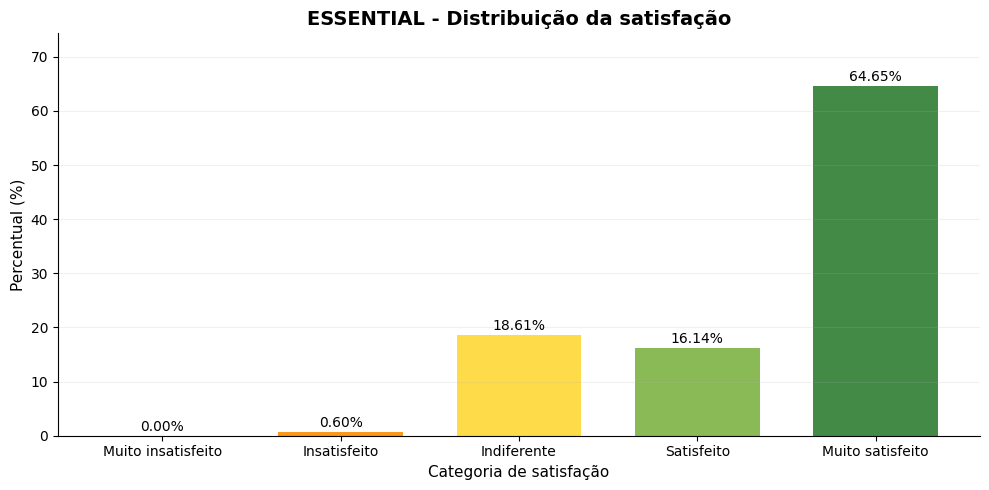

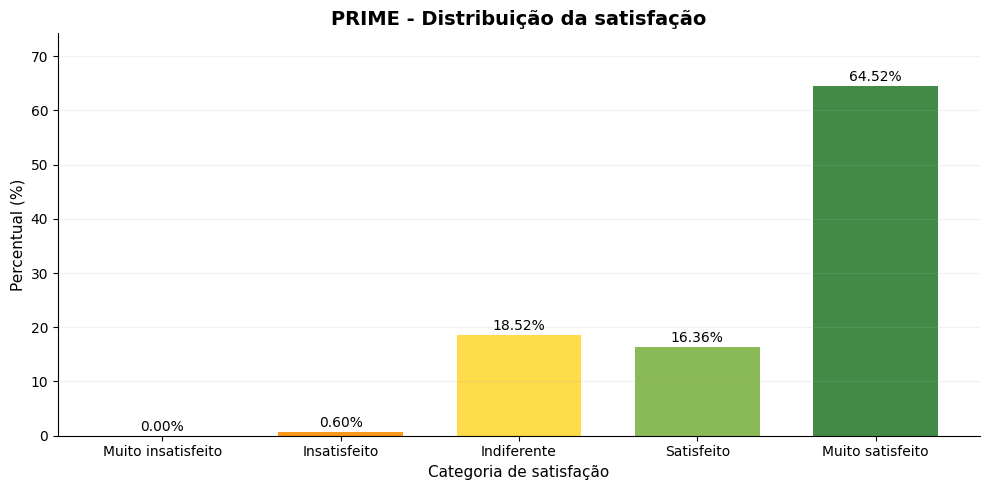

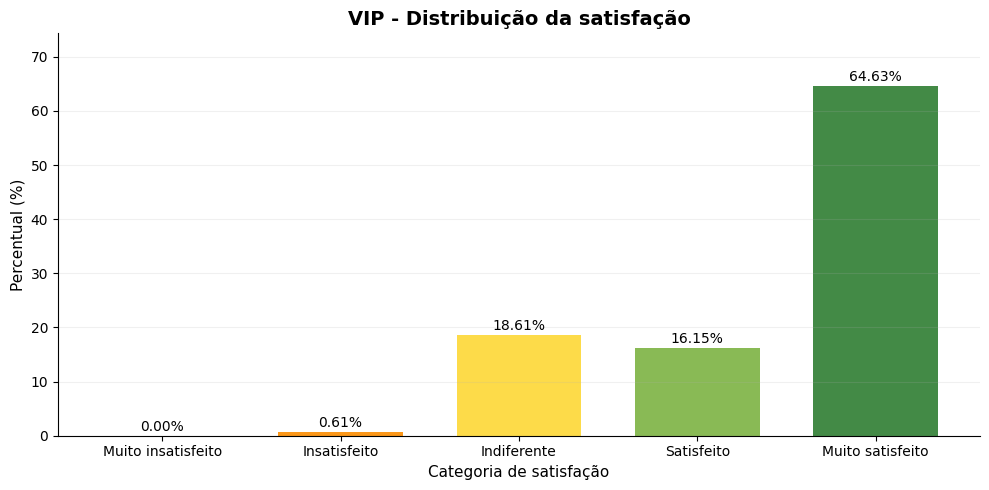

In [ ]:
cores_satisfacao = {
    "Muito insatisfeito": "#E53935",
    "Insatisfeito": "#FB8C00",
    "Indiferente": "#FDD835",
    "Satisfeito": "#7CB342",
    "Muito satisfeito": "#2E7D32",
}

for grupo in resultado["grupos"]:
    df_plot = tabela_satisfacao[tabela_satisfacao["Grupo"] == grupo].copy()

    plt.figure(figsize=(10, 5))

    bars = plt.bar(
        df_plot["Categoria"],
        df_plot["Freq. (%)"],
        color=[cores_satisfacao[c] for c in df_plot["Categoria"]],
        alpha=0.9,
        width=0.7,
    )

    for bar, valor in zip(bars, df_plot["Freq. (%)"]):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            valor + 0.4,
            f"{valor:.2f}%",
            ha="center",
            va="bottom",
            fontsize=10,
        )

    plt.title(f"{grupo} - Distribuição da satisfação", fontsize=14, fontweight="bold")
    plt.xlabel("Categoria de satisfação", fontsize=11)
    plt.ylabel("Percentual (%)", fontsize=11)
    plt.ylim(0, max(df_plot["Freq. (%)"]) * 1.15 if len(df_plot) > 0 else 100)
    plt.grid(axis="y", alpha=0.18)
    plt.tight_layout()
    sns.despine()
    plt.show()


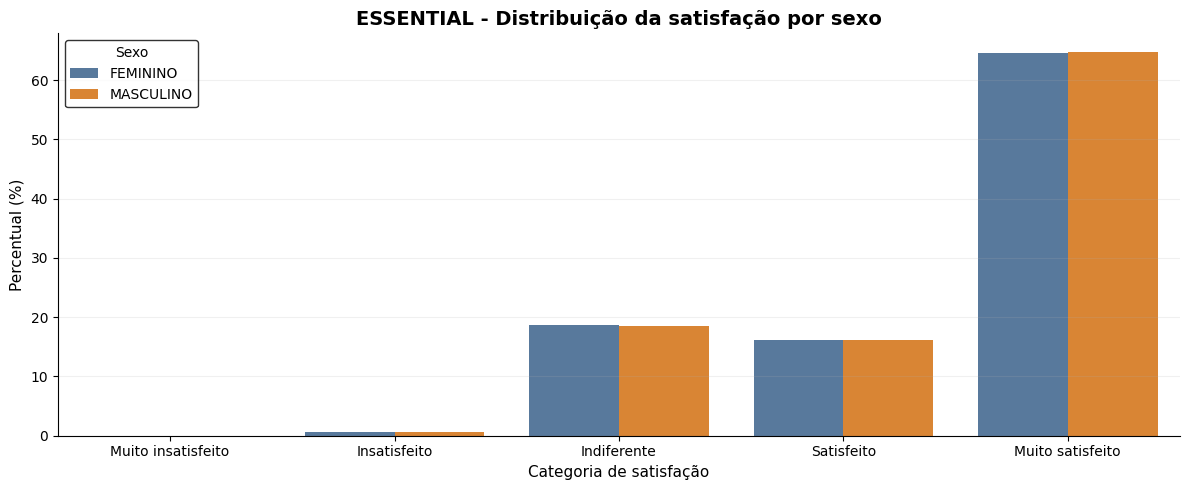

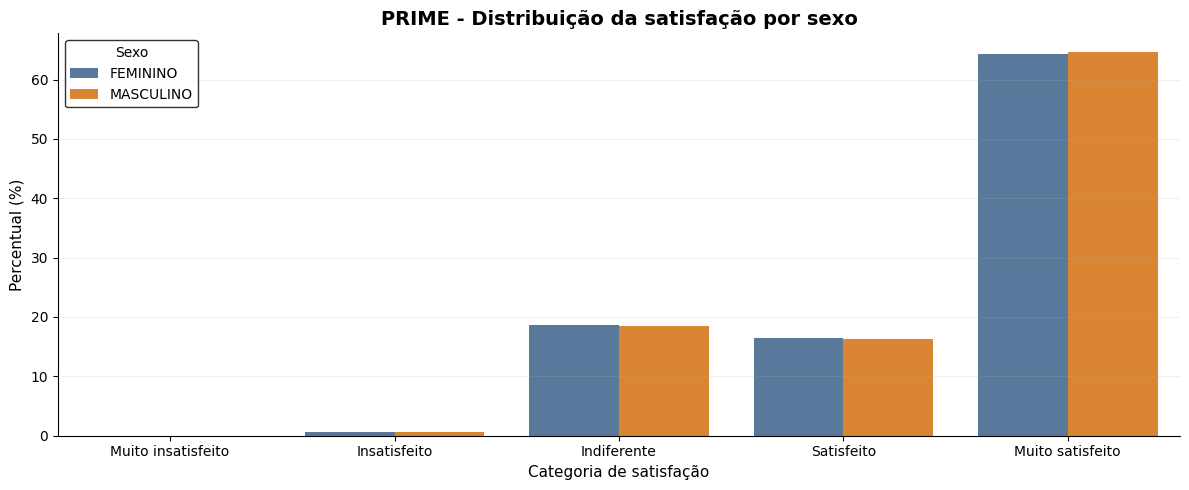

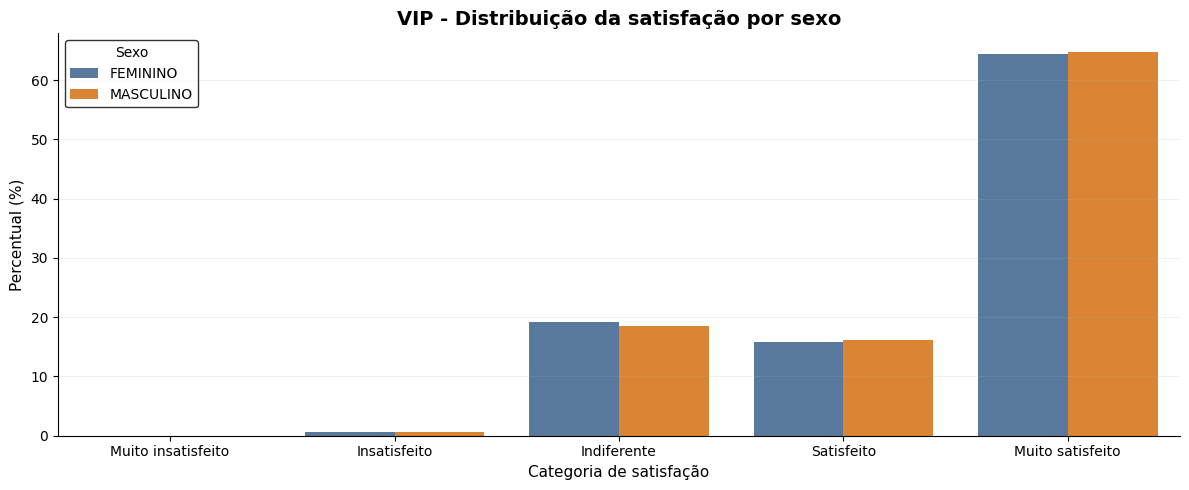

In [ ]:
for grupo in resultado["grupos"]:
    df_plot = tabela_satisfacao_sexo[tabela_satisfacao_sexo["Grupo"] == grupo].copy()

    plt.figure(figsize=(12, 5))

    sns.barplot(
        data=df_plot,
        x="Categoria",
        y="Freq. (%)",
        hue="Sexo",
        palette=["#4C78A8", "#F58518"]
    )

    plt.title(f"{grupo} - Distribuição da satisfação por sexo", fontsize=14, fontweight="bold")
    plt.xlabel("Categoria de satisfação", fontsize=11)
    plt.ylabel("Percentual (%)", fontsize=11)
    plt.grid(axis="y", alpha=0.18)
    plt.legend(title="Sexo", frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()


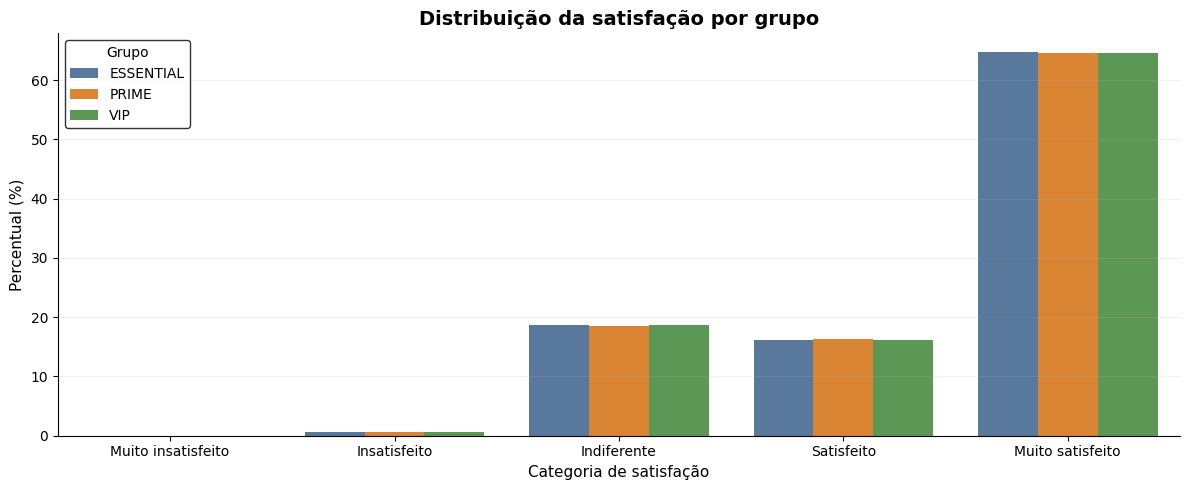

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=tabela_satisfacao,
    x="Categoria",
    y="Freq. (%)",
    hue="Grupo",
    palette=["#4C78A8", "#F58518", "#54A24B"]
)

plt.title("Distribuição da satisfação por grupo", fontsize=14, fontweight="bold")
plt.xlabel("Categoria de satisfação", fontsize=11)
plt.ylabel("Percentual (%)", fontsize=11)
plt.grid(axis="y", alpha=0.18)
plt.legend(title="Grupo", frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()


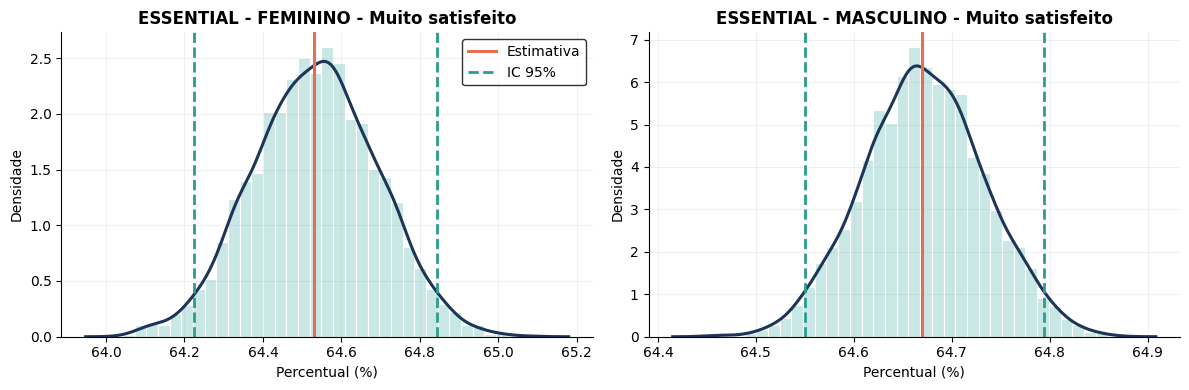

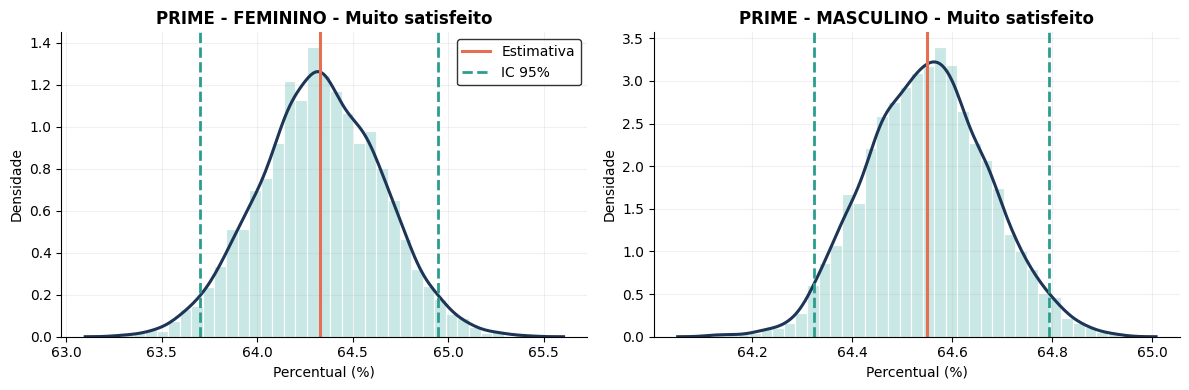

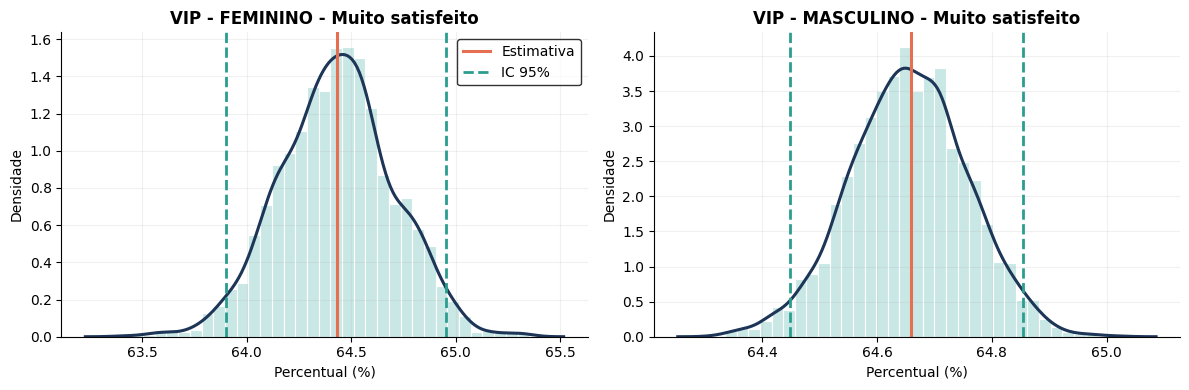

In [ ]:
categoria_plot = "Muito satisfeito"

for grupo in resultado["grupos"]:
    sexos_grupo = tabela_satisfacao_sexo[tabela_satisfacao_sexo["Grupo"] == grupo]["Sexo"].unique()

    fig, axes = plt.subplots(1, len(sexos_grupo), figsize=(6 * len(sexos_grupo), 4))

    if len(sexos_grupo) == 1:
        axes = [axes]

    for ax, sexo in zip(axes, sexos_grupo):
        boot = resultado["bootstrap"][grupo]["por_sexo"][sexo][categoria_plot]["bootstrap_%"]
        ic_inf, ic_sup = resultado["bootstrap"][grupo]["por_sexo"][sexo][categoria_plot]["ic95_%"]

        estimativa = tabela_satisfacao_sexo[
            (tabela_satisfacao_sexo["Grupo"] == grupo) &
            (tabela_satisfacao_sexo["Sexo"] == sexo) &
            (tabela_satisfacao_sexo["Categoria"] == categoria_plot)
        ]["Freq. (%)"].iloc[0]

        sns.histplot(
            boot,
            bins=35,
            stat="density",
            color="#B8E1DD",
            edgecolor="white",
            alpha=0.75,
            ax=ax
        )

        sns.kdeplot(
            boot,
            color="#1D3557",
            linewidth=2.2,
            ax=ax
        )

        ax.axvline(estimativa, color="#E76F51", linewidth=2.2, label="Estimativa")
        ax.axvline(ic_inf, color="#2A9D8F", linestyle="--", linewidth=2, label="IC 95%")
        ax.axvline(ic_sup, color="#2A9D8F", linestyle="--", linewidth=2)

        ax.set_title(f"{grupo} - {sexo} - {categoria_plot}", fontsize=12, fontweight="bold")
        ax.set_xlabel("Percentual (%)")
        ax.set_ylabel("Densidade")
        ax.grid(alpha=0.18)

    axes[0].legend(frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()


###Atividade A3.2: Análise Bootstrap do resultado da Pesquisa de Satisfação

In [ ]:
def AtividadeA3_2():
    if "A3.1" not in RESULTADOS:
        raise ValueError("Execute a Atividade A3.1 antes desta etapa.")

    resultado_a31 = RESULTADOS["A3.1"]

    tabela_geral = resultado_a31["tabela_resultados"].copy()
    tabela_sexo = resultado_a31["tabela_resultados_sexo"].copy()

    linhas_geral = []
    linhas_sexo = []

    for grupo in resultado_a31["grupos"]:
        for categoria in resultado_a31["ordem_categorias"]:
            linha = tabela_geral[
                (tabela_geral["Grupo"] == grupo) &
                (tabela_geral["Categoria"] == categoria)
            ].iloc[0]

            boot = resultado_a31["bootstrap"][grupo]["geral"][categoria]["bootstrap_%"]
            ic_inf, ic_sup = resultado_a31["bootstrap"][grupo]["geral"][categoria]["ic95_%"]
            se_boot = float(np.std(boot, ddof=1))

            linhas_geral.append({
                "Grupo": grupo,
                "Categoria": categoria,
                "N válidos": int(linha["N válidos"]),
                "Freq. (%)": float(linha["Freq. (%)"]),
                "Erro padrão bootstrap": se_boot,
                "IC 95% inferior": float(ic_inf),
                "IC 95% superior": float(ic_sup),
                "Amplitude IC": float(ic_sup - ic_inf),
            })

    for grupo in resultado_a31["grupos"]:
        sexos_grupo = sorted(
            tabela_sexo[tabela_sexo["Grupo"] == grupo]["Sexo"].dropna().unique()
        )

        for sexo in sexos_grupo:
            for categoria in resultado_a31["ordem_categorias"]:
                linha = tabela_sexo[
                    (tabela_sexo["Grupo"] == grupo) &
                    (tabela_sexo["Sexo"] == sexo) &
                    (tabela_sexo["Categoria"] == categoria)
                ].iloc[0]

                boot = resultado_a31["bootstrap"][grupo]["por_sexo"][sexo][categoria]["bootstrap_%"]
                ic_inf, ic_sup = resultado_a31["bootstrap"][grupo]["por_sexo"][sexo][categoria]["ic95_%"]
                se_boot = float(np.std(boot, ddof=1))

                linhas_sexo.append({
                    "Grupo": grupo,
                    "Sexo": sexo,
                    "Categoria": categoria,
                    "N válidos": int(linha["N válidos"]),
                    "Freq. (%)": float(linha["Freq. (%)"]),
                    "Erro padrão bootstrap": se_boot,
                    "IC 95% inferior": float(ic_inf),
                    "IC 95% superior": float(ic_sup),
                    "Amplitude IC": float(ic_sup - ic_inf),
                })

    tabela_bootstrap_geral = pd.DataFrame(linhas_geral)
    tabela_bootstrap_sexo = pd.DataFrame(linhas_sexo)

    RESULTADOS["A3.2"] = {
        "grupos": resultado_a31["grupos"],
        "ordem_categorias": resultado_a31["ordem_categorias"],
        "tabela_bootstrap": tabela_bootstrap_geral,
        "tabela_bootstrap_sexo": tabela_bootstrap_sexo,
        "bootstrap": resultado_a31["bootstrap"],
    }

    print("Análise bootstrap da satisfação por grupos concluída.")
    print(f"Grupos analisados: {len(resultado_a31['grupos'])}")
    print(f"Categorias analisadas: {len(resultado_a31['ordem_categorias'])}")
    print("Também foi calculada a precisão bootstrap por sexo dentro de cada grupo.")


In [ ]:
AtividadeA3_2()

resultado = RESULTADOS["A3.2"]
tabela_bootstrap = resultado["tabela_bootstrap"].copy()
tabela_bootstrap_sexo = resultado["tabela_bootstrap_sexo"].copy()


Análise bootstrap da satisfação por grupos concluída.
Grupos analisados: 3
Categorias analisadas: 5
Também foi calculada a precisão bootstrap por sexo dentro de cada grupo.


In [ ]:
tabela_bootstrap[[
    "Freq. (%)",
    "Erro padrão bootstrap",
    "IC 95% inferior",
    "IC 95% superior",
    "Amplitude IC"
]] = tabela_bootstrap[[
    "Freq. (%)",
    "Erro padrão bootstrap",
    "IC 95% inferior",
    "IC 95% superior",
    "Amplitude IC"
]].round(2)

display(tabela_bootstrap)


,Grupo,Categoria,N válidos,Freq. (%),Erro padrão bootstrap,IC 95% inferior,IC 95% superior,Amplitude IC
0,ESSENTIAL,Muito insatisfeito,700015,0.00,0.00,0.00,0.00,0.00
1,ESSENTIAL,Insatisfeito,700015,0.60,0.01,0.58,0.62,0.04
2,ESSENTIAL,Indiferente,700015,18.61,0.05,18.51,18.70,0.19
3,ESSENTIAL,Satisfeito,700015,16.14,0.04,16.06,16.23,0.17
4,ESSENTIAL,Muito satisfeito,700015,64.65,0.06,64.54,64.77,0.23
5,PRIME,Muito insatisfeito,175002,0.00,0.00,0.00,0.00,0.00
6,PRIME,Insatisfeito,175002,0.60,0.02,0.56,0.64,0.07
7,PRIME,Indiferente,175002,18.52,0.09,18.33,18.69,0.36
8,PRIME,Satisfeito,175002,16.36,0.09,16.19,16.54,0.35
9,PRIME,Muito satisfeito,175002,64.52,0.12,64.29,64.75,0.45


In [ ]:
for grupo in resultado["grupos"]:
    print(f"\nGrupo: {grupo}")
    display(
        tabela_bootstrap[tabela_bootstrap["Grupo"] == grupo][[
            "Categoria",
            "Freq. (%)",
            "Erro padrão bootstrap",
            "IC 95% inferior",
            "IC 95% superior",
            "Amplitude IC"
        ]]
    )



Grupo: ESSENTIAL


,Categoria,Freq. (%),Erro padrão bootstrap,IC 95% inferior,IC 95% superior,Amplitude IC
0,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
1,Insatisfeito,0.60,0.01,0.58,0.62,0.04
2,Indiferente,18.61,0.05,18.51,18.70,0.19
3,Satisfeito,16.14,0.04,16.06,16.23,0.17
4,Muito satisfeito,64.65,0.06,64.54,64.77,0.23



Grupo: PRIME


,Categoria,Freq. (%),Erro padrão bootstrap,IC 95% inferior,IC 95% superior,Amplitude IC
5,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
6,Insatisfeito,0.60,0.02,0.56,0.64,0.07
7,Indiferente,18.52,0.09,18.33,18.69,0.36
8,Satisfeito,16.36,0.09,16.19,16.54,0.35
9,Muito satisfeito,64.52,0.12,64.29,64.75,0.45



Grupo: VIP


,Categoria,Freq. (%),Erro padrão bootstrap,IC 95% inferior,IC 95% superior,Amplitude IC
10,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
11,Insatisfeito,0.61,0.02,0.58,0.64,0.06
12,Indiferente,18.61,0.08,18.46,18.77,0.31
13,Satisfeito,16.15,0.07,16.01,16.30,0.29
14,Muito satisfeito,64.63,0.10,64.43,64.81,0.38


In [ ]:
tabela_bootstrap_sexo[[
    "Freq. (%)",
    "Erro padrão bootstrap",
    "IC 95% inferior",
    "IC 95% superior",
    "Amplitude IC"
]] = tabela_bootstrap_sexo[[
    "Freq. (%)",
    "Erro padrão bootstrap",
    "IC 95% inferior",
    "IC 95% superior",
    "Amplitude IC"
]].round(2)

for grupo in resultado["grupos"]:
    print(f"\nGrupo: {grupo} - bootstrap por sexo")
    display(
        tabela_bootstrap_sexo[tabela_bootstrap_sexo["Grupo"] == grupo][[
            "Sexo",
            "Categoria",
            "Freq. (%)",
            "Erro padrão bootstrap",
            "IC 95% inferior",
            "IC 95% superior",
            "Amplitude IC"
        ]]
    )



Grupo: ESSENTIAL - bootstrap por sexo


,Sexo,Categoria,Freq. (%),Erro padrão bootstrap,IC 95% inferior,IC 95% superior,Amplitude IC
0,FEMININO,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
1,FEMININO,Insatisfeito,0.61,0.03,0.56,0.66,0.10
2,FEMININO,Indiferente,18.67,0.13,18.41,18.92,0.51
3,FEMININO,Satisfeito,16.19,0.12,15.95,16.43,0.48
4,FEMININO,Muito satisfeito,64.53,0.16,64.22,64.84,0.62
5,MASCULINO,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
6,MASCULINO,Insatisfeito,0.60,0.01,0.58,0.62,0.04
7,MASCULINO,Indiferente,18.60,0.05,18.50,18.69,0.19
8,MASCULINO,Satisfeito,16.13,0.05,16.04,16.23,0.19
9,MASCULINO,Muito satisfeito,64.67,0.06,64.55,64.79,0.24



Grupo: PRIME - bootstrap por sexo


,Sexo,Categoria,Freq. (%),Erro padrão bootstrap,IC 95% inferior,IC 95% superior,Amplitude IC
10,FEMININO,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
11,FEMININO,Insatisfeito,0.61,0.05,0.52,0.71,0.19
12,FEMININO,Indiferente,18.62,0.26,18.11,19.13,1.01
13,FEMININO,Satisfeito,16.44,0.25,15.95,16.92,0.97
14,FEMININO,Muito satisfeito,64.33,0.32,63.70,64.95,1.25
15,MASCULINO,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
16,MASCULINO,Insatisfeito,0.60,0.02,0.56,0.64,0.08
17,MASCULINO,Indiferente,18.50,0.10,18.31,18.69,0.38
18,MASCULINO,Satisfeito,16.35,0.10,16.16,16.54,0.38
19,MASCULINO,Muito satisfeito,64.55,0.12,64.32,64.79,0.47



Grupo: VIP - bootstrap por sexo


,Sexo,Categoria,Freq. (%),Erro padrão bootstrap,IC 95% inferior,IC 95% superior,Amplitude IC
20,FEMININO,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
21,FEMININO,Insatisfeito,0.63,0.04,0.55,0.72,0.17
22,FEMININO,Indiferente,19.13,0.22,18.70,19.56,0.86
23,FEMININO,Satisfeito,15.81,0.20,15.42,16.22,0.80
24,FEMININO,Muito satisfeito,64.43,0.27,63.90,64.96,1.06
25,MASCULINO,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
26,MASCULINO,Insatisfeito,0.60,0.02,0.57,0.64,0.07
27,MASCULINO,Indiferente,18.54,0.08,18.37,18.70,0.33
28,MASCULINO,Satisfeito,16.20,0.08,16.05,16.36,0.31
29,MASCULINO,Muito satisfeito,64.66,0.10,64.45,64.85,0.41


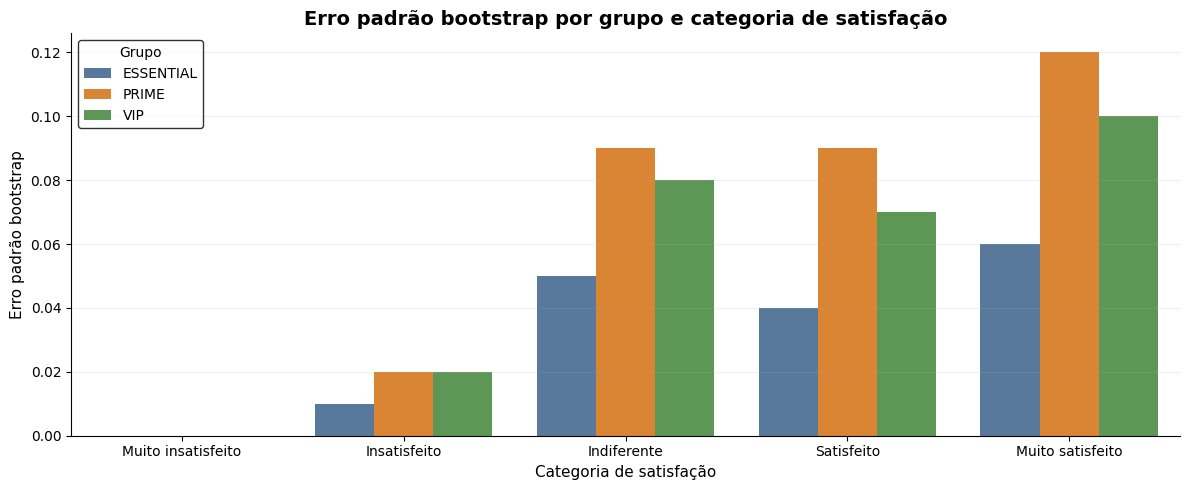

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=tabela_bootstrap,
    x="Categoria",
    y="Erro padrão bootstrap",
    hue="Grupo",
    palette=["#4C78A8", "#F58518", "#54A24B"]
)

plt.title("Erro padrão bootstrap por grupo e categoria de satisfação", fontsize=14, fontweight="bold")
plt.xlabel("Categoria de satisfação", fontsize=11)
plt.ylabel("Erro padrão bootstrap", fontsize=11)
plt.grid(axis="y", alpha=0.18)
plt.legend(title="Grupo", frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()



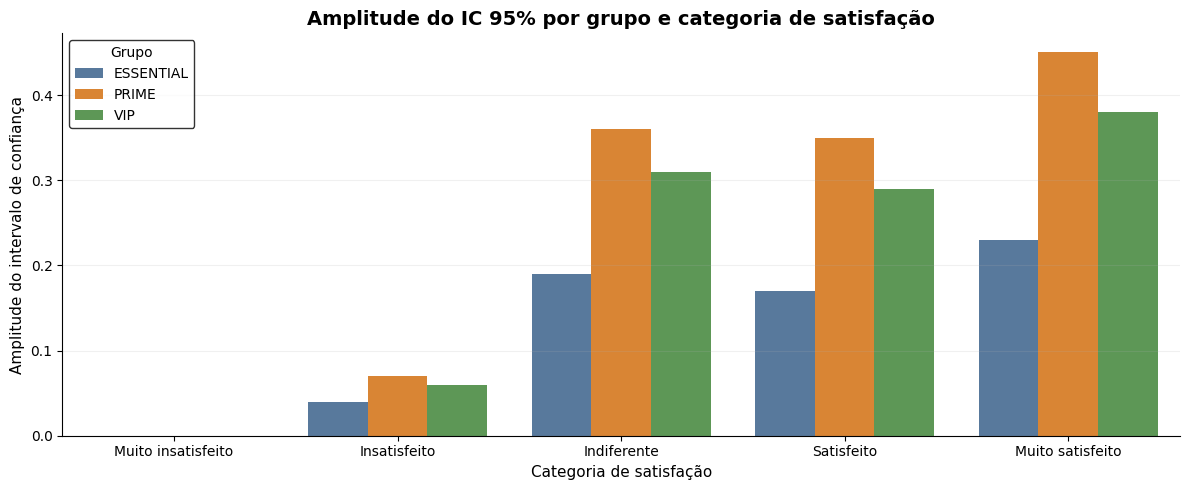

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=tabela_bootstrap,
    x="Categoria",
    y="Amplitude IC",
    hue="Grupo",
    palette=["#4C78A8", "#F58518", "#54A24B"]
)

plt.title("Amplitude do IC 95% por grupo e categoria de satisfação", fontsize=14, fontweight="bold")
plt.xlabel("Categoria de satisfação", fontsize=11)
plt.ylabel("Amplitude do intervalo de confiança", fontsize=11)
plt.grid(axis="y", alpha=0.18)
plt.legend(title="Grupo", frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()


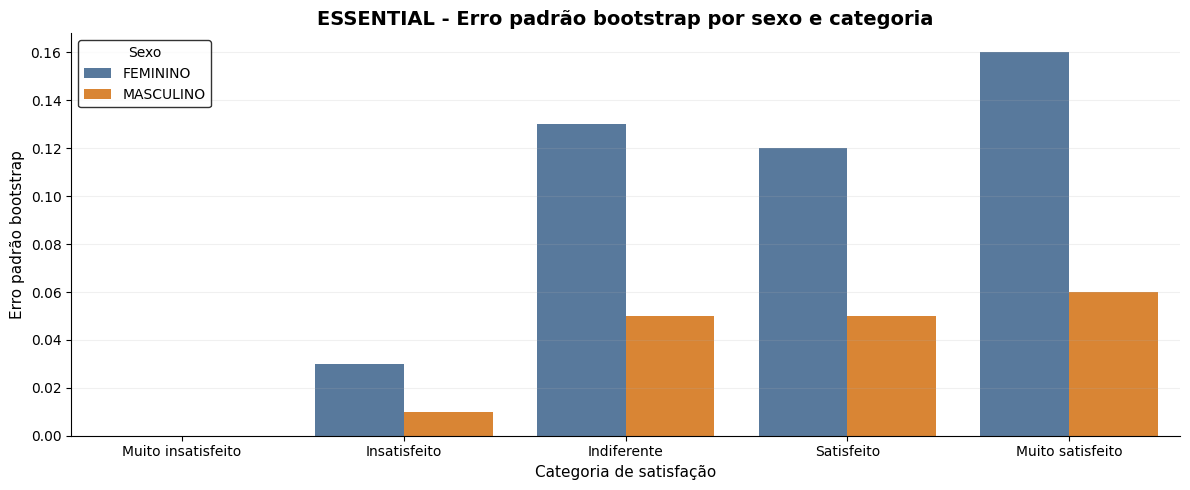

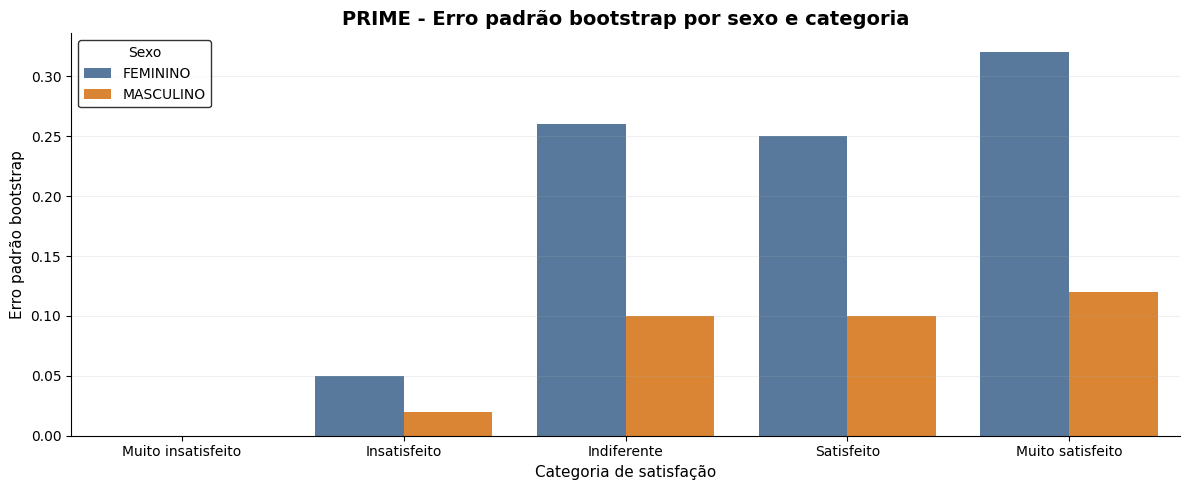

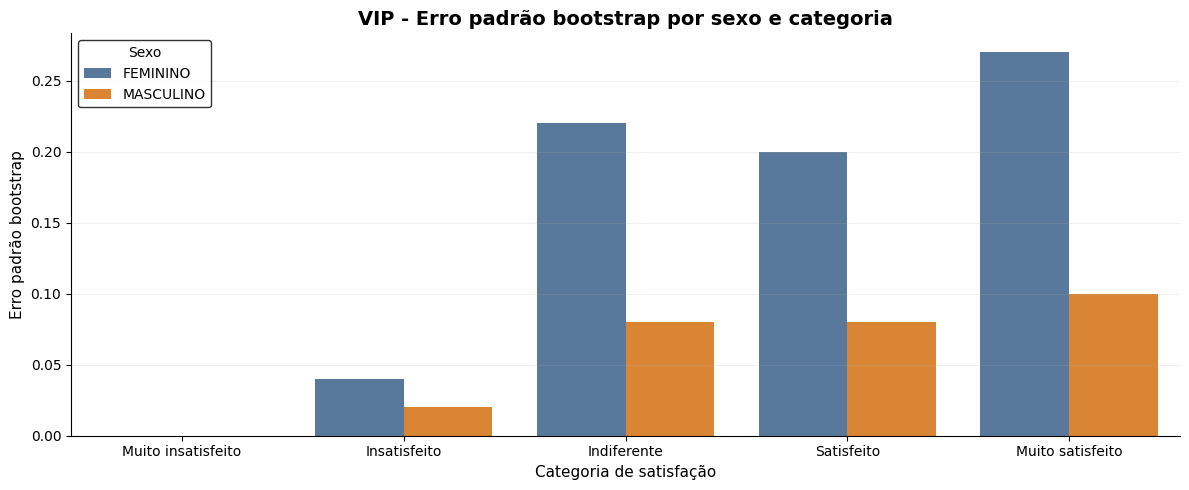

In [ ]:
for grupo in resultado["grupos"]:
    df_plot = tabela_bootstrap_sexo[tabela_bootstrap_sexo["Grupo"] == grupo].copy()

    plt.figure(figsize=(12, 5))

    sns.barplot(
        data=df_plot,
        x="Categoria",
        y="Erro padrão bootstrap",
        hue="Sexo",
        palette=["#4C78A8", "#F58518"]
    )

    plt.title(f"{grupo} - Erro padrão bootstrap por sexo e categoria", fontsize=14, fontweight="bold")
    plt.xlabel("Categoria de satisfação", fontsize=11)
    plt.ylabel("Erro padrão bootstrap", fontsize=11)
    plt.grid(axis="y", alpha=0.18)
    plt.legend(title="Sexo", frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()


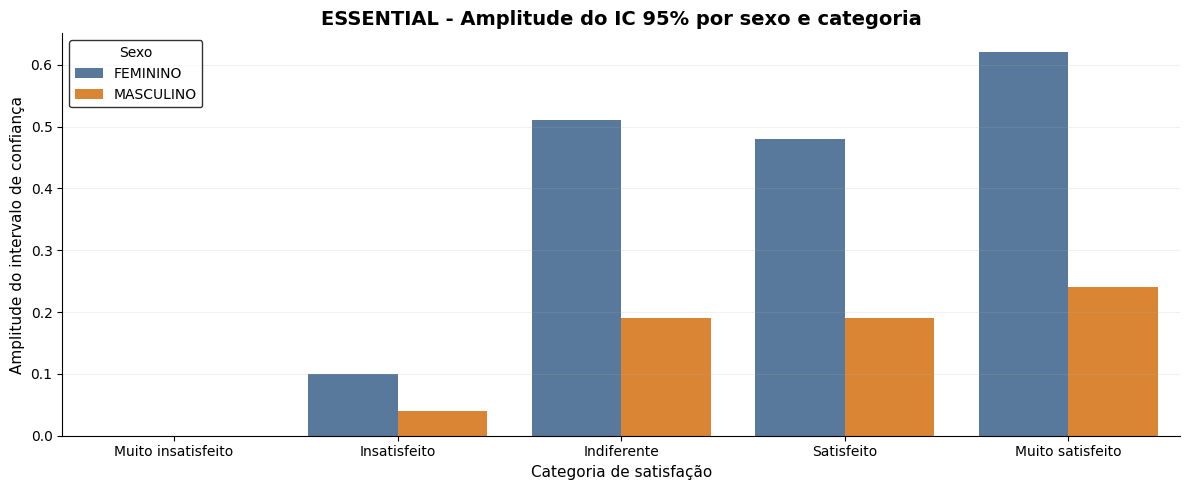

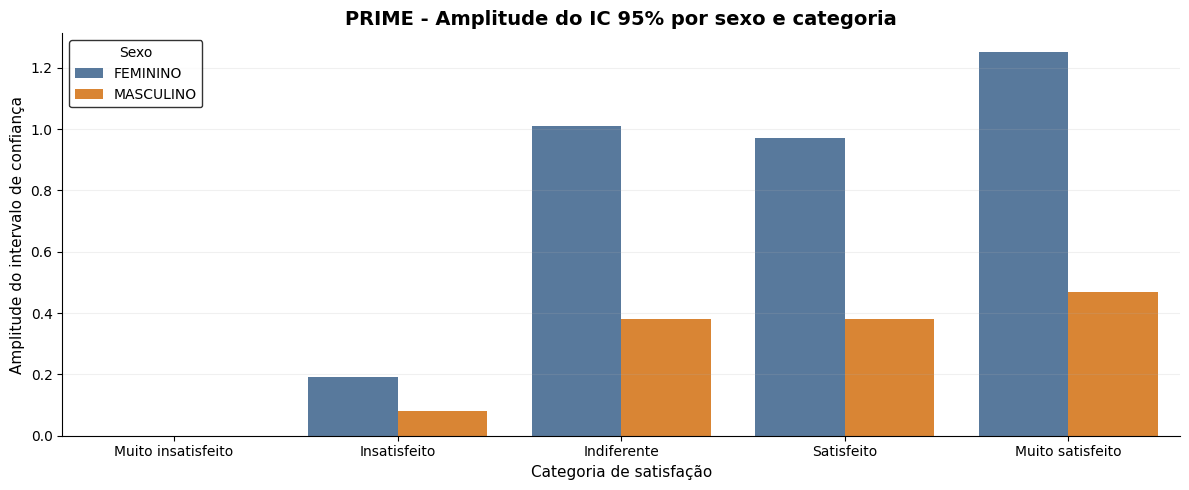

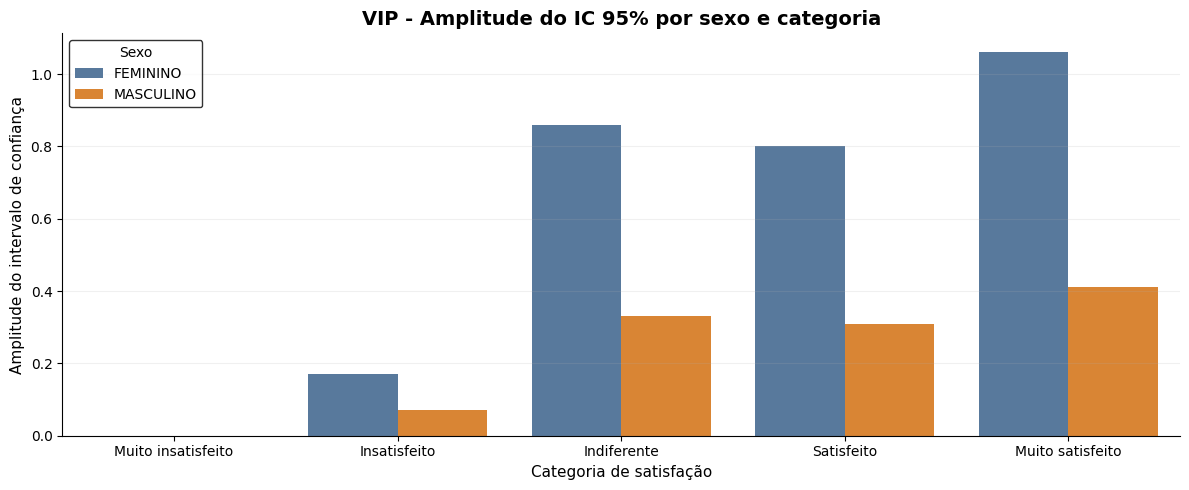

In [ ]:
for grupo in resultado["grupos"]:
    df_plot = tabela_bootstrap_sexo[tabela_bootstrap_sexo["Grupo"] == grupo].copy()

    plt.figure(figsize=(12, 5))

    sns.barplot(
        data=df_plot,
        x="Categoria",
        y="Amplitude IC",
        hue="Sexo",
        palette=["#4C78A8", "#F58518"]
    )

    plt.title(f"{grupo} - Amplitude do IC 95% por sexo e categoria", fontsize=14, fontweight="bold")
    plt.xlabel("Categoria de satisfação", fontsize=11)
    plt.ylabel("Amplitude do intervalo de confiança", fontsize=11)
    plt.grid(axis="y", alpha=0.18)
    plt.legend(title="Sexo", frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()


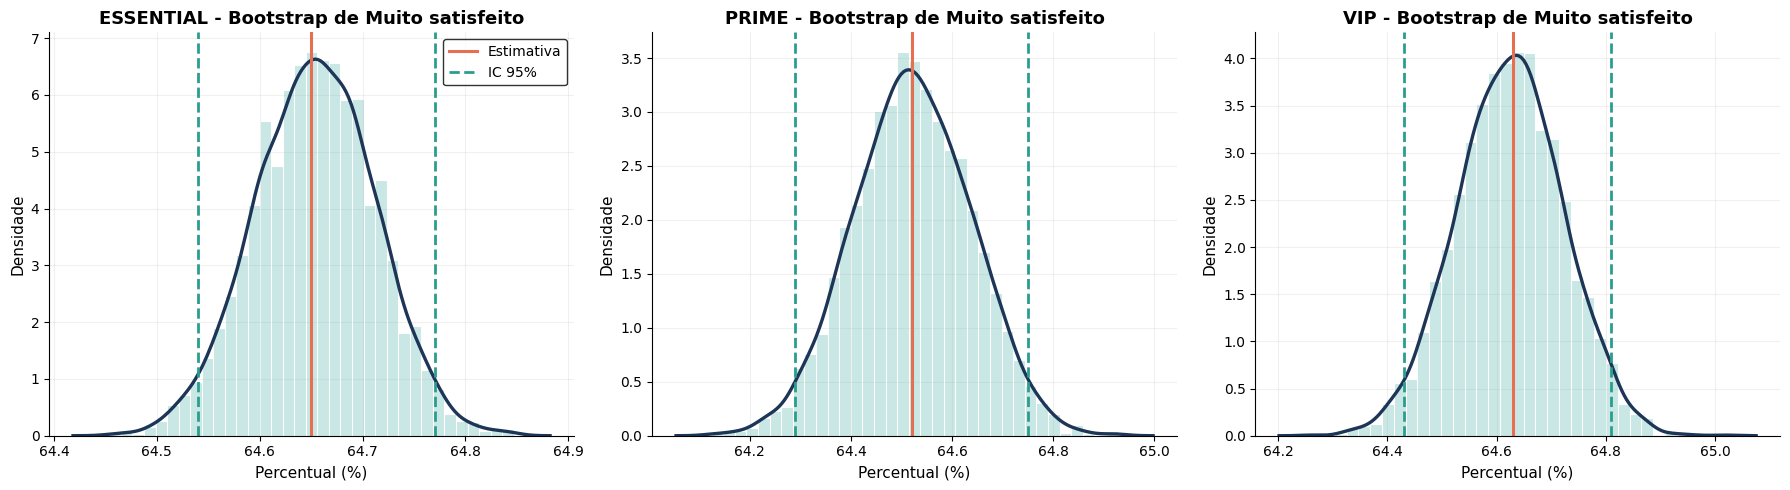

In [ ]:
categoria_plot = "Muito satisfeito"

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, grupo in zip(axes, resultado["grupos"]):
    boot = resultado["bootstrap"][grupo]["geral"][categoria_plot]["bootstrap_%"]

    linha = tabela_bootstrap[
        (tabela_bootstrap["Grupo"] == grupo) &
        (tabela_bootstrap["Categoria"] == categoria_plot)
    ].iloc[0]

    estimativa = linha["Freq. (%)"]
    ic_inf = linha["IC 95% inferior"]
    ic_sup = linha["IC 95% superior"]

    sns.histplot(
        boot,
        bins=35,
        stat="density",
        color="#B8E1DD",
        edgecolor="white",
        alpha=0.75,
        ax=ax
    )

    sns.kdeplot(
        boot,
        color="#1D3557",
        linewidth=2.4,
        ax=ax
    )

    ax.axvline(estimativa, color="#E76F51", linewidth=2.2, label="Estimativa")
    ax.axvline(ic_inf, color="#2A9D8F", linestyle="--", linewidth=2, label="IC 95%")
    ax.axvline(ic_sup, color="#2A9D8F", linestyle="--", linewidth=2)

    ax.set_title(f"{grupo} - Bootstrap de {categoria_plot}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Percentual (%)", fontsize=11)
    ax.set_ylabel("Densidade", fontsize=11)
    ax.grid(alpha=0.18)

axes[0].legend(frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()


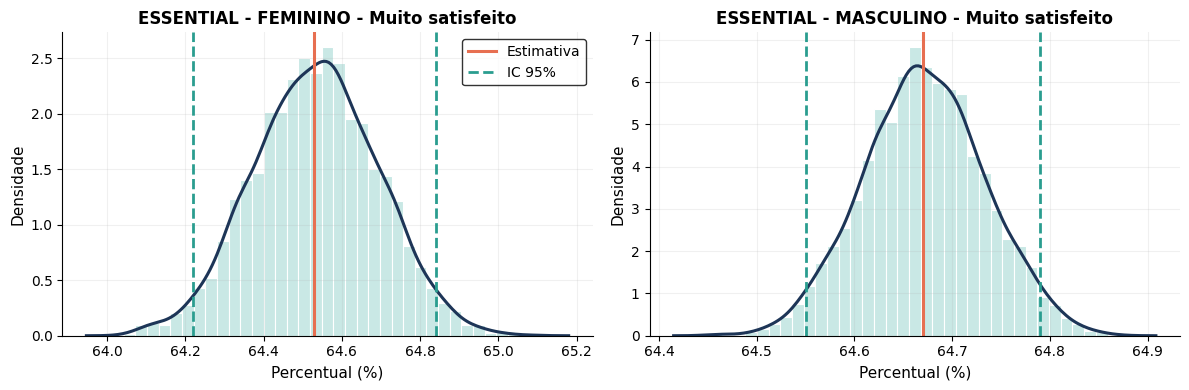

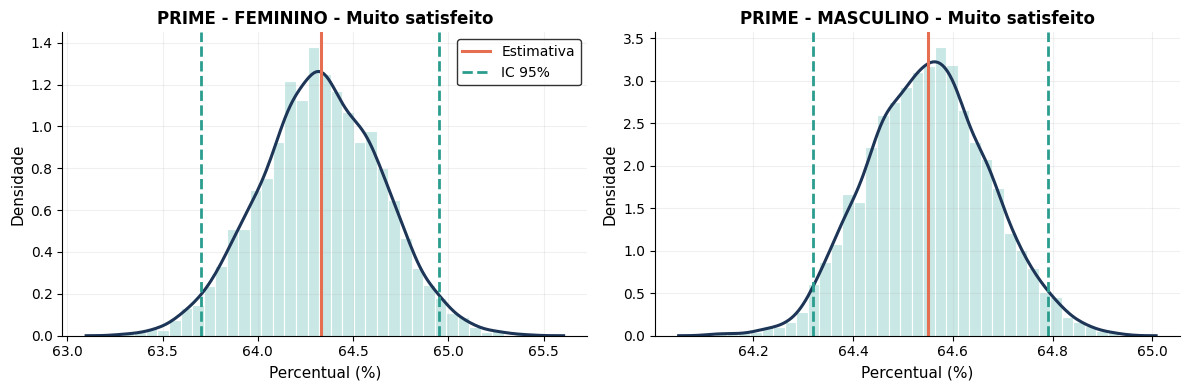

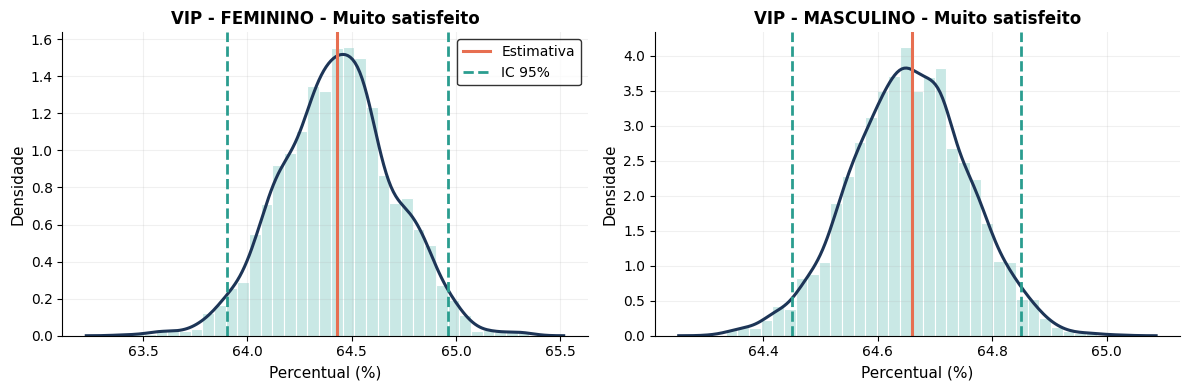

In [ ]:
categoria_plot = "Muito satisfeito"

for grupo in resultado["grupos"]:
    sexos_grupo = sorted(
        tabela_bootstrap_sexo[tabela_bootstrap_sexo["Grupo"] == grupo]["Sexo"].unique()
    )

    fig, axes = plt.subplots(1, len(sexos_grupo), figsize=(6 * len(sexos_grupo), 4))

    if len(sexos_grupo) == 1:
        axes = [axes]

    for ax, sexo in zip(axes, sexos_grupo):
        boot = resultado["bootstrap"][grupo]["por_sexo"][sexo][categoria_plot]["bootstrap_%"]

        linha = tabela_bootstrap_sexo[
            (tabela_bootstrap_sexo["Grupo"] == grupo) &
            (tabela_bootstrap_sexo["Sexo"] == sexo) &
            (tabela_bootstrap_sexo["Categoria"] == categoria_plot)
        ].iloc[0]

        estimativa = linha["Freq. (%)"]
        ic_inf = linha["IC 95% inferior"]
        ic_sup = linha["IC 95% superior"]

        sns.histplot(
            boot,
            bins=35,
            stat="density",
            color="#B8E1DD",
            edgecolor="white",
            alpha=0.75,
            ax=ax
        )

        sns.kdeplot(
            boot,
            color="#1D3557",
            linewidth=2.2,
            ax=ax
        )

        ax.axvline(estimativa, color="#E76F51", linewidth=2.2, label="Estimativa")
        ax.axvline(ic_inf, color="#2A9D8F", linestyle="--", linewidth=2, label="IC 95%")
        ax.axvline(ic_sup, color="#2A9D8F", linestyle="--", linewidth=2)

        ax.set_title(f"{grupo} - {sexo} - {categoria_plot}", fontsize=12, fontweight="bold")
        ax.set_xlabel("Percentual (%)", fontsize=11)
        ax.set_ylabel("Densidade", fontsize=11)
        ax.grid(alpha=0.18)

    axes[0].legend(frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()


###Atividade A3.3: Resultado Final da Pesquisa de Satisfação

In [ ]:
def AtividadeA3_3():
    if "A3.1" not in RESULTADOS or "A3.2" not in RESULTADOS:
        raise ValueError("Execute as Atividades A3.1 e A3.2 antes desta etapa.")

    r31 = RESULTADOS["A3.1"]
    r32 = RESULTADOS["A3.2"]

    tabela_freq = r31["tabela_resultados"].copy()
    tabela_freq_sexo = r31["tabela_resultados_sexo"].copy()

    tabela_boot = r32["tabela_bootstrap"].copy()
    tabela_boot_sexo = r32["tabela_bootstrap_sexo"].copy()

    tabela_detalhada = tabela_freq.merge(
        tabela_boot[[
            "Grupo", "Categoria", "Erro padrão bootstrap", "Amplitude IC"
        ]],
        on=["Grupo", "Categoria"],
        how="left"
    )

    tabela_detalhada_sexo = tabela_freq_sexo.merge(
        tabela_boot_sexo[[
            "Grupo", "Sexo", "Categoria", "Erro padrão bootstrap", "Amplitude IC"
        ]],
        on=["Grupo", "Sexo", "Categoria"],
        how="left"
    )

    linhas_final = []
    linhas_final_sexo = []

    for grupo in r31["grupos"]:
        df_grupo = tabela_detalhada[tabela_detalhada["Grupo"] == grupo].copy()

        pct_muito_insatisfeito = float(df_grupo.loc[df_grupo["Categoria"] == "Muito insatisfeito", "Freq. (%)"].iloc[0])
        pct_insatisfeito = float(df_grupo.loc[df_grupo["Categoria"] == "Insatisfeito", "Freq. (%)"].iloc[0])
        pct_indiferente = float(df_grupo.loc[df_grupo["Categoria"] == "Indiferente", "Freq. (%)"].iloc[0])
        pct_satisfeito = float(df_grupo.loc[df_grupo["Categoria"] == "Satisfeito", "Freq. (%)"].iloc[0])
        pct_muito_satisfeito = float(df_grupo.loc[df_grupo["Categoria"] == "Muito satisfeito", "Freq. (%)"].iloc[0])

        positivos = pct_satisfeito + pct_muito_satisfeito
        negativos = pct_insatisfeito + pct_muito_insatisfeito
        neutros = pct_indiferente
        saldo_satisfacao = positivos - negativos

        linha_dominante = df_grupo.sort_values("Freq. (%)", ascending=False).iloc[0]
        categoria_dominante = linha_dominante["Categoria"]
        percentual_dominante = float(linha_dominante["Freq. (%)"])

        amp_media_ic = float(df_grupo["Amplitude IC"].mean())
        erro_padrao_medio = float(df_grupo["Erro padrão bootstrap"].mean())

        linhas_final.append({
            "Grupo": grupo,
            "Muito insatisfeito (%)": pct_muito_insatisfeito,
            "Insatisfeito (%)": pct_insatisfeito,
            "Indiferente (%)": pct_indiferente,
            "Satisfeito (%)": pct_satisfeito,
            "Muito satisfeito (%)": pct_muito_satisfeito,
            "Positivos (%)": positivos,
            "Neutros (%)": neutros,
            "Negativos (%)": negativos,
            "Saldo satisfação": saldo_satisfacao,
            "Categoria dominante": categoria_dominante,
            "Percentual dominante (%)": percentual_dominante,
            "Erro padrão médio": erro_padrao_medio,
            "Amplitude média IC": amp_media_ic,
        })

        sexos_grupo = sorted(
            tabela_detalhada_sexo[tabela_detalhada_sexo["Grupo"] == grupo]["Sexo"].unique()
        )

        for sexo in sexos_grupo:
            df_sub = tabela_detalhada_sexo[
                (tabela_detalhada_sexo["Grupo"] == grupo) &
                (tabela_detalhada_sexo["Sexo"] == sexo)
            ].copy()

            pct_muito_insatisfeito = float(df_sub.loc[df_sub["Categoria"] == "Muito insatisfeito", "Freq. (%)"].iloc[0])
            pct_insatisfeito = float(df_sub.loc[df_sub["Categoria"] == "Insatisfeito", "Freq. (%)"].iloc[0])
            pct_indiferente = float(df_sub.loc[df_sub["Categoria"] == "Indiferente", "Freq. (%)"].iloc[0])
            pct_satisfeito = float(df_sub.loc[df_sub["Categoria"] == "Satisfeito", "Freq. (%)"].iloc[0])
            pct_muito_satisfeito = float(df_sub.loc[df_sub["Categoria"] == "Muito satisfeito", "Freq. (%)"].iloc[0])

            positivos = pct_satisfeito + pct_muito_satisfeito
            negativos = pct_insatisfeito + pct_muito_insatisfeito
            neutros = pct_indiferente
            saldo_satisfacao = positivos - negativos

            linha_dominante = df_sub.sort_values("Freq. (%)", ascending=False).iloc[0]
            categoria_dominante = linha_dominante["Categoria"]
            percentual_dominante = float(linha_dominante["Freq. (%)"])

            amp_media_ic = float(df_sub["Amplitude IC"].mean())
            erro_padrao_medio = float(df_sub["Erro padrão bootstrap"].mean())

            linhas_final_sexo.append({
                "Grupo": grupo,
                "Sexo": sexo,
                "Muito insatisfeito (%)": pct_muito_insatisfeito,
                "Insatisfeito (%)": pct_insatisfeito,
                "Indiferente (%)": pct_indiferente,
                "Satisfeito (%)": pct_satisfeito,
                "Muito satisfeito (%)": pct_muito_satisfeito,
                "Positivos (%)": positivos,
                "Neutros (%)": neutros,
                "Negativos (%)": negativos,
                "Saldo satisfação": saldo_satisfacao,
                "Categoria dominante": categoria_dominante,
                "Percentual dominante (%)": percentual_dominante,
                "Erro padrão médio": erro_padrao_medio,
                "Amplitude média IC": amp_media_ic,
            })

    tabela_final = pd.DataFrame(linhas_final)
    tabela_final_sexo = pd.DataFrame(linhas_final_sexo)

    RESULTADOS["A3.3"] = {
        "tabela_detalhada": tabela_detalhada,
        "tabela_detalhada_sexo": tabela_detalhada_sexo,
        "tabela_final": tabela_final,
        "tabela_final_sexo": tabela_final_sexo,
    }

    print("Resultado final da pesquisa de satisfação consolidado.")
    print(f"Grupos analisados: {len(tabela_final)}")
    print("Também foi consolidada a leitura por sexo dentro de cada grupo.")


In [ ]:
AtividadeA3_3()
resultado = RESULTADOS["A3.3"]

Resultado final da pesquisa de satisfação consolidado.
Grupos analisados: 3
Também foi consolidada a leitura por sexo dentro de cada grupo.


In [ ]:
tabela_final = resultado["tabela_final"].copy()

colunas_round = [
    "Muito insatisfeito (%)",
    "Insatisfeito (%)",
    "Indiferente (%)",
    "Satisfeito (%)",
    "Muito satisfeito (%)",
    "Positivos (%)",
    "Neutros (%)",
    "Negativos (%)",
    "Saldo satisfação",
    "Percentual dominante (%)",
    "Erro padrão médio",
    "Amplitude média IC",
]

tabela_final[colunas_round] = tabela_final[colunas_round].round(2)

display(tabela_final)


,Grupo,Muito insatisfeito (%),Insatisfeito (%),Indiferente (%),Satisfeito (%),Muito satisfeito (%),Positivos (%),Neutros (%),Negativos (%),Saldo satisfação,Categoria dominante,Percentual dominante (%),Erro padrão médio,Amplitude média IC
0,ESSENTIAL,0.0,0.60,18.61,16.14,64.65,80.80,18.61,0.60,80.20,Muito satisfeito,64.65,0.03,0.13
1,PRIME,0.0,0.60,18.52,16.36,64.52,80.88,18.52,0.60,80.28,Muito satisfeito,64.52,0.06,0.25
2,VIP,0.0,0.61,18.61,16.15,64.63,80.78,18.61,0.61,80.17,Muito satisfeito,64.63,0.05,0.21


In [ ]:
tabela_final_sexo = resultado["tabela_final_sexo"].copy()
tabela_final_sexo[colunas_round] = tabela_final_sexo[colunas_round].round(2)

for grupo in resultado["tabela_final"]["Grupo"]:
    print(f"\nGrupo: {grupo} - resultado final por sexo")
    display(
        tabela_final_sexo[tabela_final_sexo["Grupo"] == grupo]
    )



Grupo: ESSENTIAL - resultado final por sexo


,Grupo,Sexo,Muito insatisfeito (%),Insatisfeito (%),Indiferente (%),Satisfeito (%),Muito satisfeito (%),Positivos (%),Neutros (%),Negativos (%),Saldo satisfação,Categoria dominante,Percentual dominante (%),Erro padrão médio,Amplitude média IC
0,ESSENTIAL,FEMININO,0.0,0.61,18.67,16.19,64.53,80.73,18.67,0.61,80.12,Muito satisfeito,64.53,0.09,0.34
1,ESSENTIAL,MASCULINO,0.0,0.60,18.60,16.13,64.67,80.81,18.60,0.60,80.21,Muito satisfeito,64.67,0.03,0.13



Grupo: PRIME - resultado final por sexo


,Grupo,Sexo,Muito insatisfeito (%),Insatisfeito (%),Indiferente (%),Satisfeito (%),Muito satisfeito (%),Positivos (%),Neutros (%),Negativos (%),Saldo satisfação,Categoria dominante,Percentual dominante (%),Erro padrão médio,Amplitude média IC
2,PRIME,FEMININO,0.0,0.61,18.62,16.44,64.33,80.77,18.62,0.61,80.16,Muito satisfeito,64.33,0.18,0.69
3,PRIME,MASCULINO,0.0,0.60,18.50,16.35,64.55,80.90,18.50,0.60,80.30,Muito satisfeito,64.55,0.07,0.26



Grupo: VIP - resultado final por sexo


,Grupo,Sexo,Muito insatisfeito (%),Insatisfeito (%),Indiferente (%),Satisfeito (%),Muito satisfeito (%),Positivos (%),Neutros (%),Negativos (%),Saldo satisfação,Categoria dominante,Percentual dominante (%),Erro padrão médio,Amplitude média IC
4,VIP,FEMININO,0.0,0.63,19.13,15.81,64.43,80.24,19.13,0.63,79.60,Muito satisfeito,64.43,0.15,0.58
5,VIP,MASCULINO,0.0,0.60,18.54,16.20,64.66,80.86,18.54,0.60,80.25,Muito satisfeito,64.66,0.06,0.22


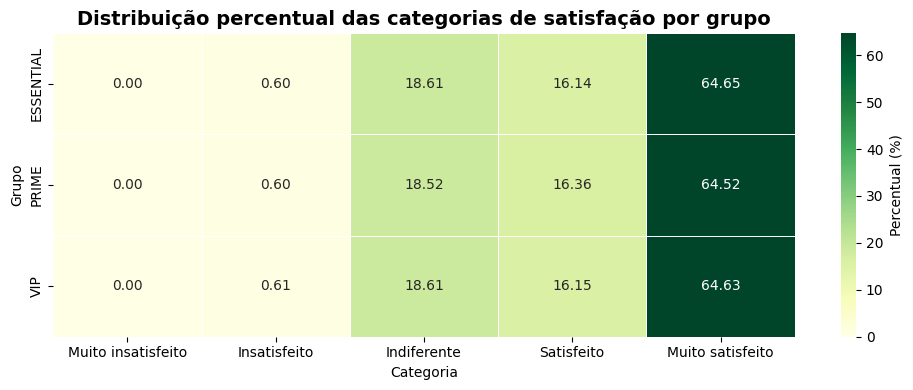

In [ ]:
heatmap_df = resultado["tabela_detalhada"].pivot(
    index="Grupo",
    columns="Categoria",
    values="Freq. (%)"
)[[
    "Muito insatisfeito",
    "Insatisfeito",
    "Indiferente",
    "Satisfeito",
    "Muito satisfeito"
]]

plt.figure(figsize=(10, 4))

sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".2f",
    cmap="YlGn",
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "Percentual (%)"}
)

plt.title("Distribuição percentual das categorias de satisfação por grupo", fontsize=14, fontweight="bold")
plt.xlabel("Categoria")
plt.ylabel("Grupo")
plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.show()


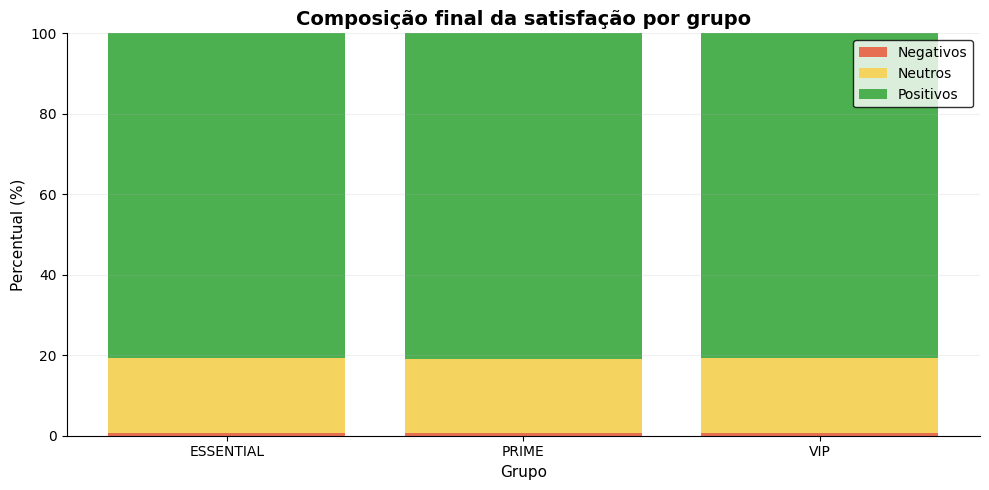

In [ ]:
plot_df = tabela_final.copy()

plt.figure(figsize=(10, 5))

plt.bar(plot_df["Grupo"], plot_df["Negativos (%)"], color="#E76F51", label="Negativos")
plt.bar(plot_df["Grupo"], plot_df["Neutros (%)"], bottom=plot_df["Negativos (%)"], color="#F4D35E", label="Neutros")
plt.bar(
    plot_df["Grupo"],
    plot_df["Positivos (%)"],
    bottom=plot_df["Negativos (%)"] + plot_df["Neutros (%)"],
    color="#4CAF50",
    label="Positivos"
)

plt.title("Composição final da satisfação por grupo", fontsize=14, fontweight="bold")
plt.xlabel("Grupo", fontsize=11)
plt.ylabel("Percentual (%)", fontsize=11)
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.18)
plt.legend(frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()


/tmp/ipykernel_1263/2303619261.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


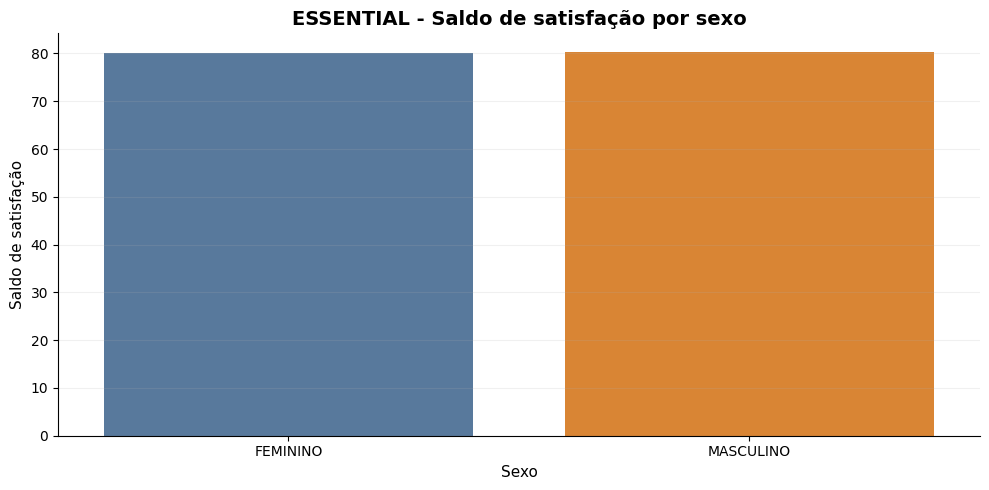

/tmp/ipykernel_1263/2303619261.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


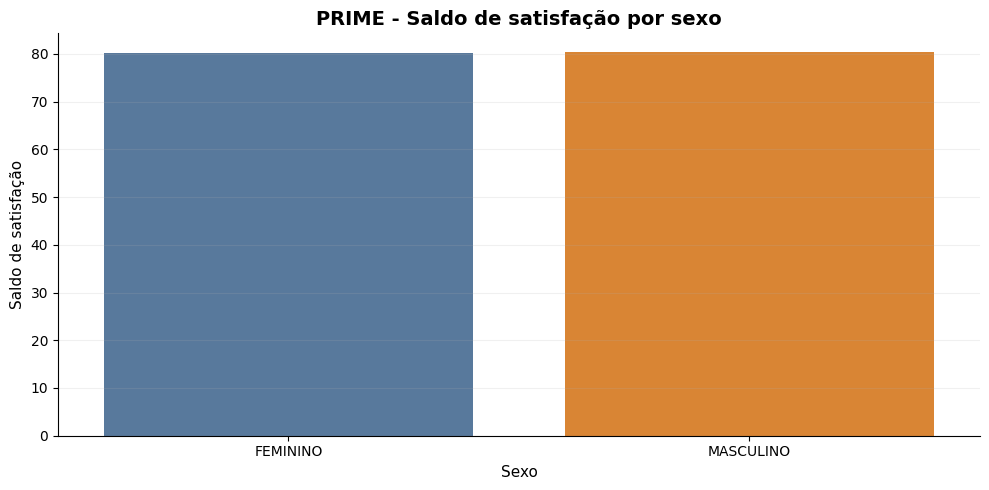

/tmp/ipykernel_1263/2303619261.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


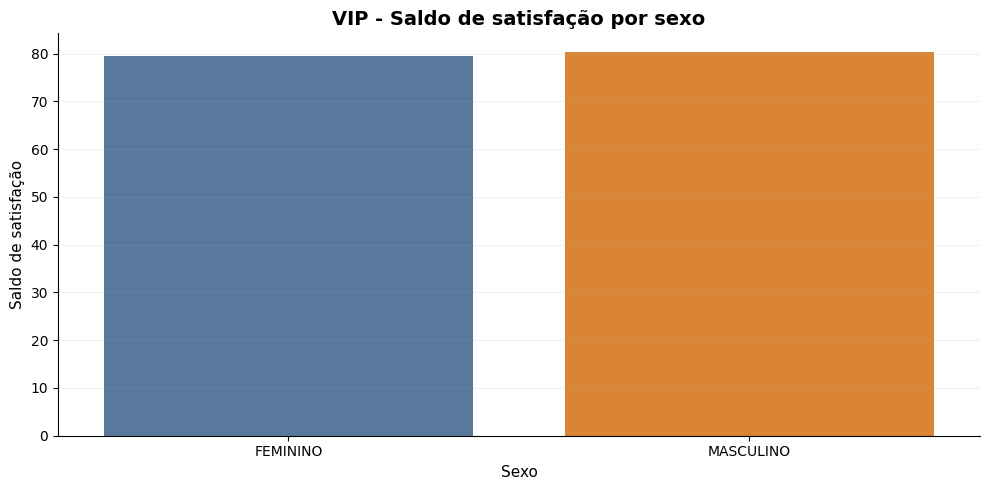

In [ ]:
for grupo in tabela_final_sexo["Grupo"].unique():
    df_plot = tabela_final_sexo[tabela_final_sexo["Grupo"] == grupo].copy()

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=df_plot,
        x="Sexo",
        y="Saldo satisfação",
        palette=["#4C78A8", "#F58518"]
    )

    plt.title(f"{grupo} - Saldo de satisfação por sexo", fontsize=14, fontweight="bold")
    plt.xlabel("Sexo", fontsize=11)
    plt.ylabel("Saldo de satisfação", fontsize=11)
    plt.grid(axis="y", alpha=0.18)
    plt.tight_layout()
    sns.despine()
    plt.show()


In [ ]:
ranking = tabela_final[[
    "Grupo", "Positivos (%)", "Negativos (%)", "Saldo satisfação", "Categoria dominante"
]].sort_values("Saldo satisfação", ascending=False)

display(ranking.round(2))


,Grupo,Positivos (%),Negativos (%),Saldo satisfação,Categoria dominante
1,PRIME,80.88,0.60,80.28,Muito satisfeito
0,ESSENTIAL,80.80,0.60,80.20,Muito satisfeito
2,VIP,80.78,0.61,80.17,Muito satisfeito


In [ ]:
ranking_sexo = tabela_final_sexo[[
    "Grupo", "Sexo", "Positivos (%)", "Negativos (%)", "Saldo satisfação", "Categoria dominante"
]].sort_values(["Grupo", "Saldo satisfação"], ascending=[True, False])

display(ranking_sexo.round(2))


,Grupo,Sexo,Positivos (%),Negativos (%),Saldo satisfação,Categoria dominante
1,ESSENTIAL,MASCULINO,80.81,0.60,80.21,Muito satisfeito
0,ESSENTIAL,FEMININO,80.73,0.61,80.12,Muito satisfeito
3,PRIME,MASCULINO,80.90,0.60,80.30,Muito satisfeito
2,PRIME,FEMININO,80.77,0.61,80.16,Muito satisfeito
5,VIP,MASCULINO,80.86,0.60,80.25,Muito satisfeito
4,VIP,FEMININO,80.24,0.63,79.60,Muito satisfeito


# RELATÓRIO FINAL - PARTE 1

Fazer aqui:

*   **RELATÓRIO FINAL - PARTE 1** com todas as conclusões e resultados que serão apresentados as gestores da **EMPRESA: UVVine**.
*   Responder a pergunta principal: **QUAL O TAMANHO IDEAL DA AMOSTRA ?**

Justifique sua resposta com os resultados obtidos:

    * Atividade A1: Estratificação amostral da população
    * Atividade A2: Estatística Descritiva

Conclusão Final

A análise realizada sobre a base da UVVine, composta por 1.120.000 registros e 23 variáveis, permitiu avaliar a qualidade dos dados, determinar um tamanho amostral adequado e compreender as principais características dos clientes. Inicialmente, verificou-se que a base não apresenta valores ausentes nas variáveis analisadas e não foram identificados valores negativos nas principais variáveis quantitativas.

Na Atividade A1 – Estratificação Amostral, verificou-se que o erro-padrão da estimativa diminui à medida que o tamanho da amostra aumenta, apresentando estabilização progressiva. Para a população geral, o critério adotado indicou um tamanho ideal de 51.500 registros, com média de TOTAL de R$ 790,98, erro-padrão médio de 3,638091 e intervalo de confiança de 95% entre R$ 783,85 e R$ 798,11.

A análise estratificada também apresentou resultados próximos para os três segmentos: 50.700 registros para ESSENTIAL, 45.400 para PRIME e 51.400 para VIP. Dessa forma, o tamanho de 51.500 registros é considerado adequado para uma amostra geral, pois atende ao maior tamanho amostral identificado entre os segmentos e proporciona maior segurança na representatividade dos dados.

Os testes de hipóteses mostraram que a variável TOTAL (R$) não apresenta distribuição normal nos grupos analisados. Entretanto, os testes de distribuição e de comparação das médias entre TRAIN, VALIDATION e TEST não identificaram diferenças estatisticamente significativas relevantes, indicando que a divisão das amostras manteve características estatísticas semelhantes entre as partições.

Na Atividade A2 – Estatística Descritiva, foram observadas diferenças importantes entre os segmentos. O grupo PRIME apresentou o maior valor médio de TOTAL, de R$ 2.237,57, enquanto o ESSENTIAL apresentou R$ 392,27 e o VIP R$ 896,92. Também foram identificadas diferenças nos níveis de dispersão e assimetria, especialmente nas variáveis financeiras, evidenciando a presença de valores extremos e uma distribuição não normal.

Em relação às características qualitativas, os três grupos apresentam perfis semelhantes, com predominância da região Sudeste, do sexo masculino, do estado civil casado e de clientes com 1 dependente. A variável de opinião do cliente, por sua vez, apresenta maior diversidade de categorias.

Dessa forma, conclui-se que o tamanho ideal da amostra para a análise geral da UVVine é de 51.500 registros. Esse tamanho apresenta equilíbrio entre representatividade estatística e redução do erro-padrão, sendo suficientemente amplo para representar a população de 1.120.000 registros e, ao mesmo tempo, adequado para a realização das análises estatísticas posteriores. Portanto, recomenda-se à gestão da UVVine utilizar 51.500 registros como tamanho de referência da amostra na continuidade do projeto.

QUAL O TAMANHO IDEAL DA AMOSTRA?

51.500 registros.
Esse foi o tamanho identificado pela análise de estabilização do erro-padrão para a população geral e é o valor adotado no projeto para as etapas posteriores.

In [9]:
!jupyter nbconvert --to html WORKFLOWJ.ipynb
from google.colab import files
files.download("/content/WORKFLOWJ.html")

[NbConvertApp] Converting notebook WORKFLOWJ.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 71 image(s).
[NbConvertApp] Writing 6895512 bytes to WORKFLOWJ.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>